# Лабораторная работа 1 — рабочий ноутбук

**ФИО:** Дмитриченко Пётр
**Файлы данных:** `clients.csv`, `transactions.csv`

Ноутбук исполняется сверху вниз на сырых файлах и на выходе даёт
очищенную таблицу, `cleaning_log.csv` и `campaign_list.csv`.

## 0. Окружение и настройки

In [274]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 200)
sns.set_theme(style='whitegrid')

RAW_CLIENTS = 'data/clients.csv'
RAW_TXN = 'data/transactions.csv'

BASE_START = pd.Timestamp('2024-01-01')
BASE_END   = pd.Timestamp('2024-12-31 23:59:59')
EVAL_START = pd.Timestamp('2025-01-01')
EVAL_END   = pd.Timestamp('2025-06-30 23:59:59')

GROUP_MIN = 150
CAMPAIGN_MAX = 2000

log_rows = []

def log(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    log_rows.append(dict(field=field, issue=issue, scope=scope, n_rows=int(n_rows),
                         value_before=str(value_before), action=action,
                         value_after=str(value_after), rationale=rationale))

## 1. Загрузка сырых данных

Разделитель и кодировка определяются автоматически: файлы выгружены
разными системами и в задании прямо сказано, что они не совпадают.
Всё читается как `str`, чтобы аудит был честным — без «тихих»
преобразований pandas.

In [275]:
def sniff_sep(path):
    with open(path, encoding='utf-8', errors='ignore') as f:
        line = f.readline()
    return ';' if line.count(';') > line.count(',') else ','

def read_raw(path, sep=None):
    if sep is None:
        sep = sniff_sep(path)
    for enc in ('utf-8-sig', 'utf-8', 'cp1251', 'windows-1251'):
        try:
            df = pd.read_csv(path, sep=sep, encoding=enc, dtype=str,
                             keep_default_na=False, na_values=[''], engine='python')
            print(path, '| encoding=', enc, '| sep=', repr(sep), '| shape=', df.shape)
            return df, sep, enc
        except (UnicodeDecodeError, UnicodeError):
            continue
    raise RuntimeError('Не удалось прочитать ' + path)

clients_raw, sep_c, enc_c = read_raw(RAW_CLIENTS)
txn_raw, sep_t, enc_t = read_raw(RAW_TXN)

data/clients.csv | encoding= utf-8-sig | sep= ',' | shape= (5713, 16)
data/transactions.csv | encoding= cp1251 | sep= ';' | shape= (611074, 9)


In [276]:
display(clients_raw.head())
display(txn_raw.head())

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004267,1980-09-10,М,Казань,Зарплатный,Золото,Кредитная,10.06.2022,22.01.2025,Зарплата в нашем банке,57.6,Да,2025-01,4,00707,Нет
1,C002417,1965-07-07,М,москва,Массовый,Базовый,Дебетовая,07.02.2014,12.11.2018,Не указан,NaN,Да,2024-12,NaN,00821,Да
2,C004134,1986-11-08,Ж,г.Екатеринбург,Массовый,Базовый,Дебетовая,21.02.2017,18.11.2017,Зарплата в нашем банке,81700.0,Да,2024-09,NaN,00578,Да
3,C004609,1957-11-30,М,Санкт-Петербург,Массовый,Серебро,Дебетовая,10.04.2013,09.03.2019,Не указан,29400.0,Нет,NaN,NaN,00887,Да
4,C004522,1970-05-09,М,г. Москва,Массовый,Базовый,Кредитная,24.03.2015,02.11.2019,Зарплата в нашем банке,75900.0,Да,2024-02,NaN,00223,Да


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990033,C001515,2023-11-23 13:48:04,"1057,66",RUB,Продукты,5411,Карта,успешно
1,990009,C000624,2023-11-26 09:58:02,"175,36",RUB,Транспорт,4111,СБП,успешно
2,990091,C004898,2023-11-29 08:19:48,"442,22",RUB,Аптеки,5912,Карта,успешно
3,990162,C004247,2023-12-01 21:39:56,"1491,75",RUB,Одежда и обувь,5651,Карта,успешно
4,990093,C000931,2023-12-06 21:27:43,"30904,06",RUB,Одежда и обувь,5651,Карта,успешно


## 2. Аудит качества

Здесь ничего не исправляем — только измеряем. Для каждой доли
знаменатель указан явно.

### 2.1. Объём, типы, ключи, единица наблюдения

In [277]:
# ============================================================
# 2.1a. clients.csv — что решил бы pandas сам (auto-load)
# ============================================================
# Демонстрация намеренно: §0 грузит как str. Здесь — что было бы,
# если бы оставили pandas.infer_objects() по умолчанию.
clients_auto = pd.read_csv(RAW_CLIENTS, sep=sep_c, encoding=enc_c, engine='python')

print('=== clients.csv — AUTO-load ===')
print('shape:', clients_auto.shape)
print('columns:', list(clients_auto.columns))
print('единица наблюдения: 1 строка = 1 клиент')
print('inferred dtypes:')
print(clients_auto.dtypes.to_string())

print(f'\nunique client_id: {clients_auto["client_id"].nunique()}')
print(f'дублей client_id: {int(clients_auto["client_id"].duplicated().sum())}')
print(f'client_id уникален: {clients_auto["client_id"].is_unique}')

print('\n=== Что auto-load оставил бы незамеченным ===')

print(f"\n• monthly_income: dtype={clients_auto['monthly_income'].dtype}")
print(f"  пример: {clients_auto['monthly_income'].head(3).tolist()}")
print(f"  min={clients_auto['monthly_income'].min()}, "
      f"median={clients_auto['monthly_income'].median()}, "
      f"max={clients_auto['monthly_income'].max()}")
print('  ПРОБЛЕМА: 57.6 — это тыс. руб., а 81700.0 — уже рубли.')
print('  auto-load видит единый float64 и «всё ОК»; mean/median смещены.')
print('  §3.1a делает ×1000 по правилу (inc < 1000) — это видно только на str-загрузке.')

print(f"\n• satisfaction_score: dtype={clients_auto['satisfaction_score'].dtype}")
print(f"  пример: {clients_auto['satisfaction_score'].head(4).tolist()}")
print('  ПРОБЛЕМА: порядковая шкала 1..5 в float провоцирует mean «4.3 звёзд».')
print('  §3.1a оставляет float, но §5.1 потом меряет моду/медиану, а не mean.')

print('\n• даты:')
for col in ['birth_date','registration_date','card_open_date','app_last_login']:
    print(f'  {col}: dtype={clients_auto[col].dtype}, пример={clients_auto[col].head(2).tolist()}')
print('  ПРОБЛЕМА: pandas не парсит даты без явного запроса — они остаются строками.')
print('  §3.1a делает pd.to_datetime(dayfirst=True) явно.')

print(f"\n• branch_code: dtype={clients_auto['branch_code'].dtype}")
print(f"  пример: {clients_auto['branch_code'].head(3).tolist()}")
print('  В этой выгрузке ведущие нули сохранены (object).')
print('  Но если бы все коды были числовыми — pandas сделал бы int64 и «съел» нули;')
print('  §3.1a делает zfill(5) осознанно, без надежды на auto-load.')

print(f"\n• has_mobile_app: dtype={clients_auto['has_mobile_app'].dtype}")
print(f"  пример: {clients_auto['has_mobile_app'].head(3).tolist()}")
print('  ПРОБЛЕМА: «Да»/«Нет» уже как object — pandas здесь не ошибается,')
print('  но §3.2a всё равно прогоняет через norm_bool (регистр, yes/no, 1/0).')

print('\n=== Сравнение: auto vs str (как в §0) ===')
cmp = pd.DataFrame({
    'auto':    clients_auto.dtypes.astype(str),
    'str(§0)': clients_raw.dtypes.astype(str),
})
cmp['differs'] = cmp['auto'] != cmp['str(§0)']
display(cmp)

print('\nРешение: наивное читает как str (dtype=str, keep_default_na=False).')
print('§3.1a затем явно приводит типы. Это дороже в одну ячейку, но:')
print('  — видно, что 57.6 и 81700.0 в одной колонке, но в разных единицах;')
print('  — видно, что «1980-09-10» и «10.06.2022» соседствуют (два формата дат);')
print('  — ведущие нули в branch_code и client_id не теряются молча.')
display(clients_raw.head(3))

=== clients.csv — AUTO-load ===
shape: (5713, 16)
columns: ['client_id', 'birth_date', 'gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'registration_date', 'card_open_date', 'income_source', 'monthly_income', 'has_mobile_app', 'app_last_login', 'satisfaction_score', 'branch_code', 'marketing_opt_in']
единица наблюдения: 1 строка = 1 клиент
inferred dtypes:
client_id                 str
birth_date                str
gender                    str
city                      str
segment                   str
loyalty_tier              str
card_type                 str
registration_date         str
card_open_date            str
income_source             str
monthly_income        float64
has_mobile_app            str
app_last_login            str
satisfaction_score    float64
branch_code             int64
marketing_opt_in          str

unique client_id: 5658
дублей client_id: 55
client_id уникален: False

=== Что auto-load оставил бы незамеченным ===

• monthly_income: dtype=float64


,auto,str(§0),differs
client_id,str,str,False
birth_date,str,str,False
gender,str,str,False
city,str,str,False
segment,str,str,False
loyalty_tier,str,str,False
card_type,str,str,False
registration_date,str,str,False
card_open_date,str,str,False
income_source,str,str,False



Решение: наивное читает как str (dtype=str, keep_default_na=False).
§3.1a затем явно приводит типы. Это дороже в одну ячейку, но:
  — видно, что 57.6 и 81700.0 в одной колонке, но в разных единицах;
  — видно, что «1980-09-10» и «10.06.2022» соседствуют (два формата дат);
  — ведущие нули в branch_code и client_id не теряются молча.


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004267,1980-09-10,М,Казань,Зарплатный,Золото,Кредитная,10.06.2022,22.01.2025,Зарплата в нашем банке,57.6,Да,2025-01,4,00707,Нет
1,C002417,1965-07-07,М,москва,Массовый,Базовый,Дебетовая,07.02.2014,12.11.2018,Не указан,NaN,Да,2024-12,NaN,00821,Да
2,C004134,1986-11-08,Ж,г.Екатеринбург,Массовый,Базовый,Дебетовая,21.02.2017,18.11.2017,Зарплата в нашем банке,81700.0,Да,2024-09,NaN,00578,Да


In [278]:
# ============================================================
# 2.1b. transactions.csv — что решил бы pandas сам (auto-load)
# ============================================================
txn_auto = pd.read_csv(RAW_TXN, sep=sep_t, encoding=enc_t, engine='python')

print('=== transactions.csv — AUTO-load ===')
print('shape:', txn_auto.shape)
print('columns:', list(txn_auto.columns))
print('единица наблюдения: 1 строка = 1 операция')
print('inferred dtypes:')
print(txn_auto.dtypes.to_string())

print(f'\nunique txn_id: {txn_auto["txn_id"].nunique()}')
print(f'дублей txn_id: {int(txn_auto["txn_id"].duplicated().sum())}')
print(f'txn_id уникален: {txn_auto["txn_id"].is_unique}')
print(f'unique client_id (в операциях): {txn_auto["client_id"].nunique()}')

print('\n=== Что auto-load оставил бы незамеченным ===')

print(f"\n• amount: dtype={txn_auto['amount'].dtype}")
print(f"  пример: {txn_auto['amount'].head(3).tolist()}")
print('  ПРОБЛЕМА: «1057,66» — запятая как десятичный разделитель;')
print('  pandas молча оставляет object. .mean() даст TypeError.')
print('  §3.1b делает .str.replace(",", ".") → float64 явно.')

print(f"\n• txn_datetime: dtype={txn_auto['txn_datetime'].dtype}")
print(f"  пример: {txn_auto['txn_datetime'].head(2).tolist()}")
print('  ПРОБЛЕМА: даты остаются строками. Фильтр «2024-01-01 .. 2025-06-30»')
print('  в §3.5b не сработает без pd.to_datetime.')

print(f"\n• txn_id: dtype={txn_auto['txn_id'].dtype}")
print(f"  пример: {txn_auto['txn_id'].head(3).tolist()}")
print('  ПРОБЛЕМА: int64. В этой выгрузке безобидно, но:')
print('    — длинные ID (>2^63−1) потеряют точность;')
print('    — ведущие нули, если появятся в другой выгрузке, «съест» int64.')
print('  §3.1b оставляет txn_id строкой для надёжности.')

print(f"\n• mcc_code: dtype={txn_auto['mcc_code'].dtype}")
print(f"  пример: {txn_auto['mcc_code'].head(3).tolist()}")
print('  ПРОБЛЕМА: mcc_code — категориальный код типа точки, а не число.')
print('  int64 провоцирует «средний MCC», а в выгрузке с кодами 0742 (ведущий ноль)')
print('  int64 потеряет ноль. §3.1b оставляет mcc_code строкой.')

print('\n=== Сравнение: auto vs str (как в §0) ===')
cmp = pd.DataFrame({
    'auto':    txn_auto.dtypes.astype(str),
    'str(§0)': txn_raw.dtypes.astype(str),
})
cmp['differs'] = cmp['auto'] != cmp['str(§0)']
display(cmp)

print('\nРешение: §0 читает как str (dtype=str, keep_default_na=False).')
print('§3.1b приводит явно:')
print('  — amount: «,» → «.» → float64')
print('  — txn_datetime: pd.to_datetime')
print('  — mcc_code, txn_id: остаются строкой (категория / защита точности)')
display(txn_raw.head(3))

=== transactions.csv — AUTO-load ===
shape: (611074, 9)
columns: ['txn_id', 'client_id', 'txn_datetime', 'amount', 'currency', 'category', 'mcc_code', 'channel', 'status']
единица наблюдения: 1 строка = 1 операция
inferred dtypes:
txn_id          int64
client_id         str
txn_datetime      str
amount            str
currency          str
category          str
mcc_code        int64
channel           str
status            str

unique txn_id: 609574
дублей txn_id: 1500
txn_id уникален: False
unique client_id (в операциях): 5993

=== Что auto-load оставил бы незамеченным ===

• amount: dtype=str
  пример: ['1057,66', '175,36', '442,22']
  ПРОБЛЕМА: «1057,66» — запятая как десятичный разделитель;
  pandas молча оставляет object. .mean() даст TypeError.
  §3.1b делает .str.replace(",", ".") → float64 явно.

• txn_datetime: dtype=str
  пример: ['2023-11-23 13:48:04', '2023-11-26 09:58:02']
  ПРОБЛЕМА: даты остаются строками. Фильтр «2024-01-01 .. 2025-06-30»
  в §3.5b не сработает без pd.to_

,auto,str(§0),differs
txn_id,int64,str,True
client_id,str,str,False
txn_datetime,str,str,False
amount,str,str,False
currency,str,str,False
category,str,str,False
mcc_code,int64,str,True
channel,str,str,False
status,str,str,False



Решение: §0 читает как str (dtype=str, keep_default_na=False).
§3.1b приводит явно:
  — amount: «,» → «.» → float64
  — txn_datetime: pd.to_datetime
  — mcc_code, txn_id: остаются строкой (категория / защита точности)


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990033,C001515,2023-11-23 13:48:04,"1057,66",RUB,Продукты,5411,Карта,успешно
1,990009,C000624,2023-11-26 09:58:02,"175,36",RUB,Транспорт,4111,СБП,успешно
2,990091,C004898,2023-11-29 08:19:48,"442,22",RUB,Аптеки,5912,Карта,успешно


### 2.2. Дубли

In [279]:
n_full = int(clients_raw.duplicated().sum())
n_key  = int(clients_raw['client_id'].duplicated().sum())
print(f'clients: полных дублей = {n_full} | дублей client_id = {n_key} '
      f'(из {len(clients_raw)} строк, {n_key/len(clients_raw)*100:.2f}%)')
if n_key:
    print('\nпримеры дублирующихся client_id:')
    display(clients_raw[clients_raw['client_id'].duplicated(keep=False)]
            .sort_values('client_id').head(10))
else:
    print('дублей нет — действий не потребуется')

clients: полных дублей = 40 | дублей client_id = 55 (из 5713 строк, 0.96%)

примеры дублирующихся client_id:


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
862,C000161,1947-03-26,М,Москва,Зарплатный,Золото,Дебетовая,20.12.2020,07.10.2024,Зарплата в нашем банке,89400.0,Да,2025-04,5,00779,Да
3991,C000161,1947-03-26,М,Москва,Зарплатный,Золото,Дебетовая,20.12.2020,07.10.2024,Зарплата в нашем банке,89400.0,Да,2025-04,5,00779,Да
290,C000283,1952-11-15,М,Екатеринбург,Зарплатный,Серебро,Дебетовая,29.01.2020,16.01.2023,Зарплата в нашем банке,152300.0,Да,2024-06,NaN,00596,Да
2734,C000283,1952-11-15,М,Казань,Зарплатный,Серебро,Дебетовая,29.01.2020,16.01.2023,Зарплата в нашем банке,152300.0,Да,2024-06,NaN,00596,Да
1112,C000614,1977-02-28,М,Санкт-Петербург,Премиальный,Золото,Премиальная,05.09.2018,27.06.2020,Не указан,NaN,Нет,NaN,5,00812,Да
5501,C000614,1977-02-28,М,Екатеринбург,Массовый,Золото,Премиальная,05.09.2018,27.06.2020,Не указан,NaN,Нет,NaN,5,00812,Да
3596,C000735,1975-01-28,Ж,Москва,Массовый,Базовый,Дебетовая,28.11.2015,20.01.2019,Зарплата в нашем банке,55200.0,Да,2024-01,NaN,00727,Да
4581,C000735,1975-01-28,Ж,Москва,Массовый,Базовый,Дебетовая,28.11.2015,20.01.2019,Зарплата в нашем банке,55200.0,Да,2024-01,NaN,00727,Да
2220,C001022,1939-01-17,Ж,Нижний Новгород,Массовый,Базовый,Дебетовая,12.07.2015,23.08.2016,Не указан,91800.0,Нет,NaN,NaN,00895,Да
5215,C001022,1939-01-17,Ж,Новосибирск,Премиальный,Базовый,Дебетовая,12.07.2015,23.08.2016,Не указан,91800.0,Нет,NaN,NaN,00895,Да


In [280]:
n_full = int(txn_raw.duplicated().sum())
n_key  = int(txn_raw['txn_id'].duplicated().sum())
print(f'txn: полных дублей = {n_full} | дублей txn_id = {n_key} '
      f'(из {len(txn_raw)} строк, {n_key/len(txn_raw)*100:.2f}%)')
if n_key:
    print('\nпримеры дублирующихся txn_id:')
    display(txn_raw[txn_raw['txn_id'].duplicated(keep=False)]
            .sort_values('txn_id').head(10))
else:
    print('дублей нет — действий не потребуется')

txn: полных дублей = 1270 | дублей txn_id = 1500 (из 611074 строк, 0.25%)

примеры дублирующихся txn_id:


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
114,100106,C003444,2024-01-01 10:07:13,"2839,12",RUB,АЗС,5541,СБП,успешно
115,100106,C003444,2024-01-01 10:07:13,"2839,12",RUB,АЗС,5541,СБП,успешно
892,100882,C001501,2024-01-02 11:44:37,"1918,47",RUB,Продукты,5411,Карта,успешно
893,100882,C001501,2024-01-02 11:44:37,"1918,47",RUB,Продукты,5411,Карта,успешно
1044,101033,C005121,2024-01-02 14:10:07,"4516,5",RUB,Развлечения и досуг,7832,Токен,успешно
1045,101033,C005121,2024-01-02 14:10:07,"4516,5",RUB,Развлечения и досуг,7832,Токен,успешно
1322,101310,C001355,2024-01-02 18:29:10,"4564,95",RUB,Одежда и обувь,5651,СБП,успешно
1323,101310,C001355,2024-01-02 18:29:10,"4564,95",RUB,Одежда и обувь,5651,СБП,успешно
1583,101570,C001007,2024-01-03 10:53:25,"450,89",RUB,Онлайн-сервисы,5815,Карта,успешно
1584,101570,C001007,2024-01-03 10:53:25,"450,89",RUB,Онлайн-сервисы,5815,Карта,успешно


### 2.3. Соответствие данных описанию полей из задания

In [281]:
# Только измерение. clients_raw / txn_raw не меняются.

print('========== clients.csv: категориальные поля ==========')
for col in ['gender','segment','loyalty_tier','card_type',
            'income_source','has_mobile_app','marketing_opt_in']:
    print(f'--- {col} ---')
    print(clients_raw[col].value_counts(dropna=False).head(15))
    print()

print('========== clients.csv: даты ==========')
for col in ['birth_date','registration_date','card_open_date']:
    s = clients_raw[col].fillna('').astype(str).str.strip()
    p_dmy = pd.to_datetime(s, errors='coerce', dayfirst=True)
    p_ymd = pd.to_datetime(s, errors='coerce', dayfirst=False)
    n_bad = int((p_dmy.isna() & p_ymd.isna() & (s != '')).sum())
    print(f'{col}: нераспознано={n_bad}, min={p_dmy.min()}, max={p_dmy.max()}, '
          f'пусто={int((s=="").sum())}')

print('\n========== clients.csv: monthly_income ==========')
inc_audit = pd.to_numeric(clients_raw['monthly_income'].astype(str)
                          .str.replace(' ','').str.replace(',','.'), errors='coerce')
print('NaN:', int(inc_audit.isna().sum()),
      '| p50:', inc_audit.median(),
      '| p99:', round(inc_audit.quantile(.99), 1),
      '| max:', inc_audit.max())
small = (inc_audit > 0) & (inc_audit < 1000)
print('значений < 1000 (подозрение на тыс. руб.):', int(small.sum()))
print('примеры:', list(inc_audit[small].head(8)))

print('\n========== clients.csv: satisfaction_score ==========')
sat_audit = pd.to_numeric(clients_raw['satisfaction_score'].astype(str)
                          .str.replace(',','.'), errors='coerce')
print('NaN:', int(sat_audit.isna().sum()),
      '| вне 1..5:', int(((sat_audit < 1) | (sat_audit > 5)).sum()),
      '| уникальные значения:', sorted(sat_audit.dropna().unique().tolist()))

print('\n========== clients.csv: city — разнобой написания ==========')
def _simple_norm(s):
    s = str(s).replace('\u00a0',' ').replace('ё','е').replace('Ё','Е')
    s = ' '.join(s.split()).lower()
    for p in ('г. ','г.','гор. ','гор.','город '):
        if s.startswith(p):
            s = s[len(p):]; break
    return s.strip(' .,-')
city_raw_audit = clients_raw['city'].fillna('').astype(str)
city_norm_audit = city_raw_audit.map(_simple_norm)
print(f'вариантов ДО: {city_raw_audit.nunique()} | '
      f'ПОСЛЕ простой нормализации: {city_norm_audit.nunique()}')
print(f'строк, чьё написание изменилось бы: '
      f'{int((city_raw_audit.str.strip() != city_norm_audit).sum())}')
print('примеры склеек:')
collapsed = pd.DataFrame({'raw': city_raw_audit, 'norm': city_norm_audit}).query('raw != norm')
display(collapsed.drop_duplicates('norm').head(10))

print('\n========== transactions.csv: статусы/валюты/каналы ==========')
for col in ['status','currency','channel','category']:
    print(f'--- {col} ---')
    print(txn_raw[col].value_counts(dropna=False))
    print()

print('========== transactions.csv: mcc_code ↔ category ==========')
xt = pd.crosstab(txn_raw['mcc_code'], txn_raw['category'])
multi = (xt > 0).sum(axis=1)
print(f'mcc_code, встречающихся более чем с одной категорией: '
      f'{int((multi > 1).sum())} из {len(xt)}')

========== clients.csv: категориальные поля ==========
--- gender ---
gender
Ж    2860
М    2853
Name: count, dtype: int64

--- segment ---
segment
Массовый       2983
Зарплатный     1611
Премиальный     901
Private         218
Name: count, dtype: int64

--- loyalty_tier ---
loyalty_tier
Базовый    2920
Серебро    1547
Золото      917
Платина     329
Name: count, dtype: int64

--- card_type ---
card_type
Дебетовая      3992
Кредитная      1243
Премиальная     478
Name: count, dtype: int64

--- income_source ---
income_source
Зарплата в нашем банке     2630
Не указан                  1544
Зарплата в другом банке    1539
Name: count, dtype: int64

--- has_mobile_app ---
has_mobile_app
Да     3536
Нет    2177
Name: count, dtype: int64

--- marketing_opt_in ---
marketing_opt_in
Да     5007
Нет     706
Name: count, dtype: int64

========== clients.csv: даты ==========
birth_date: нераспознано=0, min=1936-01-08 00:00:00, max=2001-10-11 00:00:00, пусто=0
registration_date: нераспознано=0, min

C:\Users\Admin\AppData\Local\Temp\ipykernel_32520\3293886495.py:14: UserWarning: Parsing dates in %d.%m.%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  p_ymd = pd.to_datetime(s, errors='coerce', dayfirst=False)


,raw,norm
0,Казань,казань
1,москва,москва
2,г.Екатеринбург,екатеринбург
3,Санкт-Петербург,санкт-петербург
5,Н. Новгород,н. новгород
8,Нижний Новгород,нижний новгород
20,г. Новосибирск,новосибирск
163,СПб,спб
179,Санкт Петербург,санкт петербург



========== transactions.csv: статусы/валюты/каналы ==========
--- status ---
status
успешно      591803
отклонено     11994
возврат        7277
Name: count, dtype: int64

--- currency ---
currency
RUB    608599
USD      1282
EUR      1193
Name: count, dtype: int64

--- channel ---
channel
Карта          313497
СБП            107581
Токен           98200
Онлайн-банк     91796
Name: count, dtype: int64

--- category ---
category
Продукты               162673
Одежда и обувь          67358
Транспорт               65080
АЗС                     56188
Кафе и рестораны        46824
Развлечения и досуг     45800
Аптеки                  45000
Онлайн-сервисы          42384
Связь и интернет        28869
Связь и Интернет        19158
Кафе/рестораны          15885
кафе и рестораны        15855
Name: count, dtype: int64

========== transactions.csv: mcc_code ↔ category ==========
mcc_code, встречающихся более чем с одной категорией: 9 из 9


In [282]:
for col in ['currency','status','channel','category']:
    print('--- ' + col + ' ---')
    print(txn_raw[col].value_counts(dropna=False).head(20))
    print()

amt_raw = pd.to_numeric(txn_raw['amount'].astype(str).str.replace(' ','').str.replace(',','.'), errors='coerce')
print('amount | NaN:', int(amt_raw.isna().sum()), '| min:', amt_raw.min(), '| p50:', amt_raw.median(), '| max:', amt_raw.max(), '| <=0:', int((amt_raw <= 0).sum()))

dt_raw = pd.to_datetime(txn_raw['txn_datetime'], errors='coerce')
print('txn_datetime | не распознано:', int(dt_raw.isna().sum()), '| min:', dt_raw.min(), '| max:', dt_raw.max())

xt = pd.crosstab(txn_raw['mcc_code'], txn_raw['category'])
multi = (xt > 0).sum(axis=1)
print('mcc_code, встречающийся более чем с одной категорией:', int((multi > 1).sum()))

--- currency ---
currency
RUB    608599
USD      1282
EUR      1193
Name: count, dtype: int64

--- status ---
status
успешно      591803
отклонено     11994
возврат        7277
Name: count, dtype: int64

--- channel ---
channel
Карта          313497
СБП            107581
Токен           98200
Онлайн-банк     91796
Name: count, dtype: int64

--- category ---
category
Продукты               162673
Одежда и обувь          67358
Транспорт               65080
АЗС                     56188
Кафе и рестораны        46824
Развлечения и досуг     45800
Аптеки                  45000
Онлайн-сервисы          42384
Связь и интернет        28869
Связь и Интернет        19158
Кафе/рестораны          15885
кафе и рестораны        15855
Name: count, dtype: int64

amount | NaN: 0 | min: -61526.19 | p50: 1062.05 | max: 131749.61 | <=0: 7277
txn_datetime | не распознано: 48820 | min: 2023-11-23 13:48:04 | max: 2026-07-20 20:19:55
mcc_code, встречающийся более чем с одной категорией: 9


### 2.4. Связь между таблицами

In [283]:
orph = ~txn_raw['client_id'].isin(clients_raw['client_id'])
print(f'операций с client_id вне справочника: {int(orph.sum())} '
      f'({orph.mean()*100:.2f}% от {len(txn_raw)})')

has_txn = clients_raw['client_id'].isin(txn_raw['client_id'])
print(f'клиентов без операций: {int((~has_txn).sum())} '
      f'({(~has_txn).mean()*100:.2f}% от {len(clients_raw)})')

per_client = txn_raw.groupby('client_id').size()
print('\nраспределение операций на клиента (только те, у кого есть):')
print(per_client.describe(percentiles=[.5, .9, .99]))

операций с client_id вне справочника: 27423 (4.49% от 611074)
клиентов без операций: 7 (0.12% от 5713)

распределение операций на клиента (только те, у кого есть):
count    5993.000000
mean      101.964625
std        75.312219
min         1.000000
50%        88.000000
90%       196.000000
99%       355.000000
max       903.000000
dtype: float64


**Выводы по аудиту.** Ниже в журнале фиксируются: дубли ключей, разнобой
написаний города и назначения транзакции, несоответствие единиц `monthly_income` (часть значений
в тыс. руб.), смешанные форматы дат, пропуски в доходе и оценке сервиса,
выбросы по сумме операции, а также операции вне справочника клиентов.
Ни одно из нарушений не делает данные непригодными: всё либо приводится
к единому виду, либо осознанно оставляется с обоснованием.

### 2.5 Чего в данных нет

**Чего в данных нет (влияет на выводы):**

- Нет истории до 2024-01-01. Клиенты с `card_open_date < 2024-01`
  наблюдаются меньше полутора лет; «H2-2024 vs H1-2025» — лучшее,
  что можно сделать, но тренд за 2023 неизвестен. Часть падений
  могла начаться до начала данных.
- Нет продуктов вне карт (кредиты, вклады, ипотека, инвестиции).
  Клиент может быть активным клиентом банка, но не пользоваться
  картой.
- Нет данных о конкурентах и причинах ухода. Видно «операции упали»,
  но не «ушёл в другой банк» vs «карта перестала работать».
- Нет дохода у 5–10% клиентов (`income_source = 'Не указан'`).
  Фильтр по доходу исключает их из соответствующих срезов.
- Нет истории обращений в поддержку и жалоб. Спад качества
  обслуживания не виден.
- Полная правильность написания географических имен городов не проверялась, соответсвенно возможны разногласия.

## 3. Препроцессинг

Каждое изменение данных фиксируется в журнале (раздел 4).

### 3.1. Типы, даты, числа

In [284]:
clients = clients_raw.copy()
print('========== 3.1a: clients — типы/даты/числа ==========')

# --- client_id ---
before_ids = clients['client_id'].astype(str)
clients['client_id'] = clients['client_id'].astype(str).str.strip()
n_strip = int((before_ids != clients['client_id']).sum())
print(f'client_id: strip изменил {n_strip} строк')
if clients['client_id'].duplicated().any():
    n = int(clients['client_id'].duplicated().sum())
    before = len(clients)
    clients = clients.drop_duplicates('client_id', keep='first')
    print(f'client_id: удалено дублей {n} ({before} → {len(clients)})')
    log('client_id','дубли ключа справочника','clients.csv', n, f'{before} строк',
        'удалено', f'{len(clients)} строк',
        'ключ справочника должен быть уникален, оставлена первая запись')
else:
    print('client_id: дублей нет')

# --- даты ---
for col in ['birth_date','registration_date','card_open_date']:
    s = clients[col].fillna('').astype(str).str.strip()
    parsed = pd.to_datetime(s, errors='coerce', dayfirst=True)
    n_bad = int((parsed.isna() & (s != '')).sum())
    print(f'{col}: нераспознано {n_bad} → NaT')
    if n_bad:
        log(col,'нераспознанная дата','clients.csv', n_bad, 'смешанные форматы',
            'приведено к datetime', 'NaT',
            'единый тип для возраста/стажа; нераспознанные помечены NaT')
    clients[col] = parsed

def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(' ','').str.replace(',','.'), errors='coerce')

# --- income ---
inc = to_num(clients['monthly_income'])
n_nonnum = int(clients['monthly_income'].notna().sum() - inc.notna().sum())
print(f'monthly_income: не распознано как число {n_nonnum} → NaN')
small = (inc < 1000) & inc.notna()
n_small = int(small.sum())
if n_small:
    inc.loc[small] = inc.loc[small] * 1000
    print(f'monthly_income: {n_small} значений ×1000 (тыс. руб. → руб.)')
    log('monthly_income','единицы измерения: значения в тыс. руб.','clients.csv', n_small,
        'напр. 57.6', 'умножено на 1000', '57600',
        'доход < 1000 ₽ нереалистичен; приведено к рублям')
clients['monthly_income'] = inc

# --- satisfaction ---
clients['satisfaction_score'] = to_num(clients['satisfaction_score'])
n_s = int(clients['satisfaction_score'].isna().sum() - clients_raw['satisfaction_score'].isna().sum())
print(f'satisfaction_score: не распознано {n_s} → NaN')

# --- branch_code ---
before_bc = clients['branch_code'].astype(str).str.strip()
clients['branch_code'] = clients['branch_code'].fillna('').astype(str).str.strip().str.zfill(5)
n_bc = int((before_bc != clients['branch_code']).sum())
print(f'branch_code: дополнено нулями {n_bc} строк')

# --- app_last_login ---
before_al = clients['app_last_login'].fillna('').astype(str)
clients['app_last_login'] = pd.to_datetime(before_al.str.strip(), errors='coerce')
n_al = int((clients['app_last_login'].isna() & (before_al.str.strip() != '')).sum())
print(f'app_last_login: нераспознано {n_al} → NaT')

========== 3.1a: clients — типы/даты/числа ==========
client_id: strip изменил 0 строк
client_id: удалено дублей 55 (5713 → 5658)
birth_date: нераспознано 3437 → NaT
registration_date: нераспознано 0 → NaT
card_open_date: нераспознано 0 → NaT
monthly_income: не распознано как число 0 → NaN
monthly_income: 247 значений ×1000 (тыс. руб. → руб.)
satisfaction_score: не распознано -40 → NaN
branch_code: дополнено нулями 0 строк
app_last_login: нераспознано 0 → NaT


In [285]:
txn_raw = txn_raw.copy()

for c in ['txn_id', 'client_id', 'mcc_code']:
    txn_raw[c] = txn_raw[c].astype(str).str.strip()

txn_raw['amount_raw'] = txn_raw['amount'].astype(str)
txn_raw['amount'] = to_num(txn_raw['amount_raw'])
n_bad_amt = int((txn_raw['amount'].isna() &
                 (txn_raw['amount_raw'].str.strip() != '')).sum())
print(f'amount: не распознано как число {n_bad_amt} → NaN')

txn_raw['txn_datetime'] = pd.to_datetime(txn_raw['txn_datetime'], errors='coerce')
n_bad_dt = int(txn_raw['txn_datetime'].isna().sum())
print(f'txn_datetime: невалидных {n_bad_dt} → NaT')

txn_raw['status']   = txn_raw['status'].astype(str).str.strip().str.lower()
txn_raw['currency'] = txn_raw['currency'].astype(str).str.strip().str.upper()
txn_raw['channel']  = txn_raw['channel'].astype(str).str.strip()
txn_raw['category'] = txn_raw['category'].astype(str).str.strip()

assert txn_raw['amount'].dtype != object, \
    'amount должен быть числовым — все агрегации идут через него'
assert 'amount_num' not in txn_raw.columns, \
    'amount_num не должен существовать: единственная числовая колонка — amount'

print(f'\nshape: {txn_raw.shape}')
print(f'amount dtype: {txn_raw["amount"].dtype}')
print(f'amount NaN: {txn_raw["amount"].isna().sum()}')
print(f'txn_datetime dtype: {txn_raw["txn_datetime"].dtype}')

amount: не распознано как число 0 → NaN
txn_datetime: невалидных 48820 → NaT

shape: (611074, 10)
amount dtype: float64
amount NaN: 0
txn_datetime dtype: datetime64[us]


### 3.2. Категориальные признаки

In [286]:
# --- city: нормализация написаний ---
CITY_PREFIXES = ('г. ', 'г.', 'г ', 'гор. ', 'гор.', 'гор ', 'город ')

def norm_city(x):
    if pd.isna(x):
        return x
    s = str(x).replace('\u00a0',' ').replace('ё','е').replace('Ё','Е')
    s = ' '.join(s.split())
    low = s.lower()
    for p in CITY_PREFIXES:
        if low.startswith(p):
            s = s[len(p):]; low = s.lower(); break
    s = s.strip(' .,-')
    if not s:
        return np.nan
    return ' '.join(w.capitalize() for w in s.split())

before_city = clients['city'].copy()
before_n    = clients['city'].nunique(dropna=True)
before_ex   = ', '.join(map(str, before_city.dropna().unique()[:5]))

clients['city'] = clients['city'].map(norm_city)

after_n   = clients['city'].nunique(dropna=True)
n_changed = int((before_city.fillna('__NA__') != clients['city'].fillna('__NA__')).sum())
after_ex  = ', '.join(map(str, clients['city'].dropna().unique()[:5]))

if n_changed:
    log('city', 'разнобой написания (регистр, «г./гор.», пробелы, ё/е)',
        'clients.csv', n_changed,
        f'{before_n} вариантов, напр.: {before_ex}',
        'нормализовано',
        f'{after_n} вариантов, напр.: {after_ex}',
        'приведены регистр, префиксы «г.», лишние пробелы, ё→е; смысл значения не меняется')

# --- gender ---
before_g = clients['gender'].copy()
clients['gender'] = (clients['gender'].astype(str).str.strip().str.upper()
                     .map({'М':'М','M':'М','МУЖ':'М','МУЖ.':'М',
                           'Ж':'Ж','F':'Ж','ЖЕН':'Ж','ЖЕН.':'Ж'})
                     .fillna(clients['gender'].astype(str).str.strip().str.upper()))
n_g = int((before_g.astype(str) != clients['gender'].astype(str)).sum())
if n_g:
    log('gender','разнобой написания (М/M/муж/Ж/F/жен)','clients.csv', n_g,
        'смешанные коды', 'нормализовано', 'М/Ж', 'единый код для группировок')

# --- boolean ---
def norm_bool(x):
    s = str(x).strip().lower()
    if s in ('да','yes','y','1','true'):  return 'Да'
    if s in ('нет','no','n','0','false'): return 'Нет'
    return x
for c in ['has_mobile_app','marketing_opt_in']:
    b = clients[c].copy()
    clients[c] = clients[c].map(norm_bool)
    n_b = int((b.astype(str) != clients[c].astype(str)).sum())
    if n_b:
        log(c,'разнобой написания boolean','clients.csv', n_b,
            'смешанные коды', 'нормализовано', 'Да/Нет', 'единый код')

# --- прочие строки: strip ---
for c in ['segment','loyalty_tier','card_type','income_source']:
    clients[c] = clients[c].astype(str).str.strip()

In [287]:
# --- category: нормализация написаний ---
CATEGORY_CANON = {
    'Связь и интернет':  'Связь и интернет',
    'Связь и Интернет':  'Связь и интернет',    # регистр «И»
    'Кафе и рестораны':  'Кафе и рестораны',
    'Кафе/рестораны':    'Кафе и рестораны',    # слэш вместо «и»
    'кафе и рестораны':  'Кафе и рестораны',    # нижний регистр
}
merged = {}
for variant, canon in CATEGORY_CANON.items():
    if variant != canon:
        merged.setdefault(canon, []).append(variant)

before_cat = txn_raw['category'].copy()
before_n   = txn_raw['category'].nunique(dropna=True)
before_vc  = txn_raw['category'].value_counts()

txn_raw['category'] = txn_raw['category'].replace(CATEGORY_CANON)

after_n   = txn_raw['category'].nunique(dropna=True)
n_changed = int((before_cat.fillna('__NA__') != txn_raw['category'].fillna('__NA__')).sum())

if n_changed:
    detail = '; '.join(
        f"{canon} ← {{{', '.join(sorted(vs))}}} "
        f"({sum(int(before_vc.get(v, 0)) for v in vs + [canon]):,})"
        for canon, vs in merged.items()
    )
    log('category', 'разнобой написания (регистр, слэш вместо «и», лишние пробелы)',
        'transactions.csv', n_changed,
        f'{before_n} вариантов',
        'нормализовано',
        f'{after_n} вариантов',
        f'схлопнуты: {detail}; смысл значения не меняется')

# проверка: ни один не-канонический вариант не остался
residual = set(txn_raw['category'].unique()) & {v for v, c in CATEGORY_CANON.items() if v != c}
assert not residual, f'в category остались не-канонические варианты: {residual}'

### 3.3. Пропуски

Для каждого поля — доля от всех строк справочника, гипотеза о механизме
и решение.

In [288]:
miss = pd.DataFrame({
    'n_missing': clients.isna().sum(),
    'share_%': (clients.isna().mean()*100).round(2),
})
display(miss[miss.n_missing > 0].sort_values('share_%', ascending=False))

miss_t = pd.DataFrame({
    'n_missing': txn_raw.isna().sum(),
    'share_%': (txn_raw.isna().mean()*100).round(2),
})
display(miss_t[miss_t.n_missing > 0].sort_values('share_%', ascending=False))

print('app_last_login пуст по наличию приложения:')
print(pd.crosstab(clients['has_mobile_app'], clients['app_last_login'].isna(), dropna=False))

,n_missing,share_%
birth_date,3437,60.75
satisfaction_score,3367,59.51
app_last_login,2157,38.12
monthly_income,574,10.14


,n_missing,share_%
txn_datetime,48820,7.99


app_last_login пуст по наличию приложения:
app_last_login  False  True 
has_mobile_app              
Да               3501      0
Нет                 0   2157


In [289]:
n_inc = int(clients['monthly_income'].isna().sum())
log('monthly_income','пропуски','clients.csv', n_inc, 'NaN', 'оставлено', 'NaN',
    'пропуск связан с отказом указать доход (income_source = «Не указан»); заполнение медианой исказило бы распределение, а для отбора групп поле не критично')

n_sat = int(clients['satisfaction_score'].isna().sum())
log('satisfaction_score','пропуски','clients.csv', n_sat, 'NaN', 'оставлено', 'NaN',
    'отсутствие ответа на опрос — механизм MAR (не отвечают случайно); заполнение средним по порядковой шкале методически неверно')

n_app = int(clients['app_last_login'].isna().sum())
log('app_last_login','пропуски','clients.csv', n_app, 'NaT', 'оставлено', 'NaT',
    'дата входа отсутствует в т.ч. у клиентов без приложения — это ожидаемое отсутствие, а не дефект')

### 3.4. Выбросы

Обнаружение и решение — два разных шага: сначала измеряем, потом решаем.

In [290]:
q1, q3 = txn_raw['amount'].quantile([0.25, 0.75])
iqr = q3 - q1
hi = q3 + 3*iqr
n_out = int((txn_raw['amount'] > hi).sum())
print('amount: Q1=%.2f Q3=%.2f IQR=%.2f верхняя граница 3*IQR=%.2f' % (q1, q3, iqr, hi))
print('операций выше границы:', n_out, '(%.3f%% от %d)' % (n_out/len(txn_raw)*100, len(txn_raw)))
print('максимум:', txn_raw['amount'].max())
log('amount','выбросы: суммы выше 3*IQR','transactions.csv', n_out, '> %.2f' % hi,
    'оставлено', 'без изменений',
    'крупные суммы могут быть реальными покупками; удаление искажает оборот, проверена устойчивость медианных метрик')

q1i, q3i = clients['monthly_income'].quantile([0.25, 0.75])
iqri = q3i - q1i
hii = q3i + 3*iqri
n_outi = int((clients['monthly_income'] > hii).sum())
print('monthly_income выше 3*IQR:', n_outi, '| граница %.0f' % hii)

amount: Q1=464.11 Q3=2251.52 IQR=1787.41 верхняя граница 3*IQR=7613.76
операций выше границы: 21531 (3.523% от 611074)
максимум: 131749.61
monthly_income выше 3*IQR: 186 | граница 276275


### 3.5. Фильтры, применяемые перед расчётом активности

In [291]:
steps = []
def step(name, df):
    steps.append((name, len(df)))
    return df

txn_f = txn_raw.copy()
step('вход (после снятия дублей)',            txn_f)
txn_f = step('status = "успешно"',            txn_f[txn_f['status'] == 'успешно'])
txn_f = step('currency = "RUB"',              txn_f[txn_f['currency'] == 'RUB'])
txn_f = step('txn_datetime валиден',          txn_f[txn_f['txn_datetime'].notna()])
txn_f = step('2024-01-01 .. 2025-06-30',      txn_f[(txn_f['txn_datetime'] >= BASE_START) &
                                                   (txn_f['txn_datetime'] <= EVAL_END)])
txn_f = step('client_id есть в справочнике',  txn_f[txn_f['client_id'].isin(clients['client_id'])])
txn_f = step('amount > 0',                txn_f[txn_f['amount'].notna() &
                                                   (txn_f['amount'] > 0)])

funnel = pd.DataFrame(steps, columns=['шаг','строк'])
funnel['доля от входа, %'] = (funnel['строк'] / funnel['строк'].iloc[0] * 100).round(2)
funnel['отсечено']         = funnel['строк'].shift(1).fillna(funnel['строк'].iloc[0]).astype(int) - funnel['строк']
display(funnel)

# --- журнал: n_rows = сколько отсекает ИМЕННО этот фильтр ---
# статус отсекается от всего входа
n_status_cut = int((txn_raw['status'] != 'успешно').sum())
log('status', 'в расчёте активности только успешные операции', 'transactions.csv',
    n_status_cut, 'отклонено/возврат', 'исключено', 'только успешно',
    'отклонённые не являются покупками, возвраты — обратные движения, их нельзя складывать с покупками')

# валюта — только среди тех, кто прошёл фильтр по статусу
n_currency_cut = int(((txn_raw['status'] == 'успешно') &
                      (txn_raw['currency'] != 'RUB')).sum())
log('currency', 'оставлены только рублёвые операции', 'transactions.csv',
    n_currency_cut, 'иные валюты', 'исключено', 'только RUB',
    'единая единица измерения для сравнения периодов')

,шаг,строк,"доля от входа, %",отсечено
0,вход (после снятия дублей),611074,100.00,0
1,"status = ""успешно""",591803,96.85,19271
2,"currency = ""RUB""",589414,96.46,2389
3,txn_datetime валиден,542368,88.76,47046
4,2024-01-01 .. 2025-06-30,542289,88.74,79
5,client_id есть в справочнике,517903,84.75,24386
6,amount > 0,517903,84.75,0


## 4. Журнал изменений

In [292]:
cleaning_log = pd.DataFrame(log_rows, columns=[
    'field','issue','scope','n_rows','value_before','action','value_after','rationale',
])
display(cleaning_log)

,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,client_id,дубли ключа справочника,clients.csv,55,5713 строк,удалено,5658 строк,"ключ справочника должен быть уникален, оставле..."
1,birth_date,нераспознанная дата,clients.csv,3437,смешанные форматы,приведено к datetime,NaT,единый тип для возраста/стажа; нераспознанные ...
2,monthly_income,единицы измерения: значения в тыс. руб.,clients.csv,247,напр. 57.6,умножено на 1000,57600,доход < 1000 ₽ нереалистичен; приведено к рублям
3,city,"разнобой написания (регистр, «г./гор.», пробел...",clients.csv,1953,"17 вариантов, напр.: Казань, москва, г.Екатер...",нормализовано,"9 вариантов, напр.: Казань, Москва, Екатеринбу...","приведены регистр, префиксы «г.», лишние пробе..."
4,category,"разнобой написания (регистр, слэш вместо «и», ...",transactions.csv,50898,12 вариантов,нормализовано,9 вариантов,схлопнуты: Связь и интернет ← {Связь и Интерне...
5,monthly_income,пропуски,clients.csv,574,NaN,оставлено,NaN,пропуск связан с отказом указать доход (income...
6,satisfaction_score,пропуски,clients.csv,3367,NaN,оставлено,NaN,отсутствие ответа на опрос — механизм MAR (не ...
7,app_last_login,пропуски,clients.csv,2157,NaT,оставлено,NaT,дата входа отсутствует в т.ч. у клиентов без п...
8,amount,выбросы: суммы выше 3*IQR,transactions.csv,21531,> 7613.76,оставлено,без изменений,крупные суммы могут быть реальными покупками; ...
9,status,в расчёте активности только успешные операции,transactions.csv,19271,отклонено/возврат,исключено,только успешно,"отклонённые не являются покупками, возвраты — ..."


## 5. Разведочный анализ

### 5.1. Распределения количественных признаков

Суммы операций и доходы имеют длинный правый хвост, поэтому
на графике обрезаем по p99 — иначе гистограмма может растянуться.

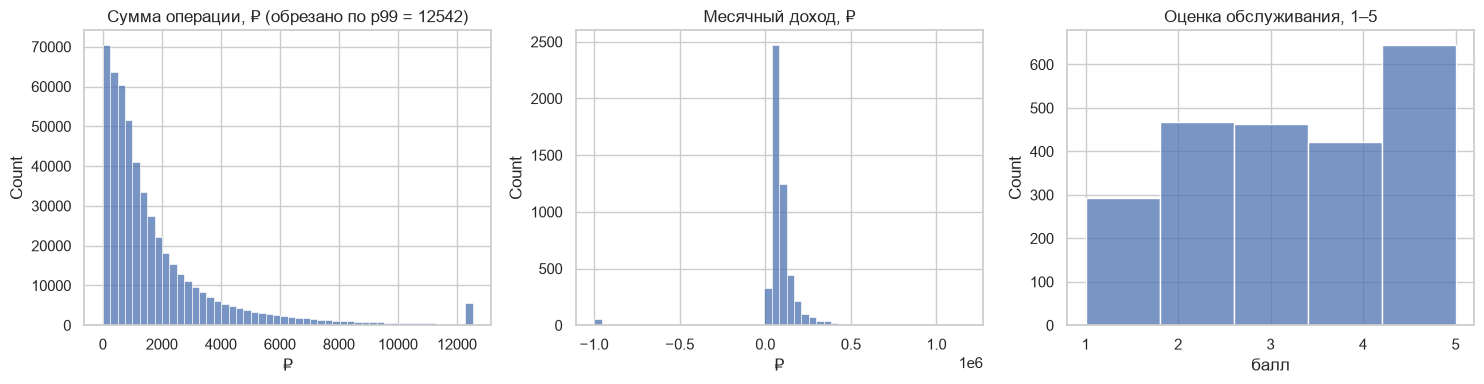

,"amount, ₽"
count,517903.000000
mean,1892.469047
std,2621.871143
min,2.720000
50%,1080.590000
90%,4361.104000
99%,12541.535400
max,131749.610000


,"monthly_income, ₽"
count,5.084000e+03
mean,8.646554e+04
std,1.376905e+05
min,-9.990000e+05
50%,7.470000e+04
90%,1.728700e+05
99%,4.422170e+05
max,1.161700e+06


,satisfaction_score
count,2291.000000
mean,3.289393
std,1.393862
min,1.000000
50%,3.000000
90%,5.000000
99%,5.000000
max,5.000000


In [293]:
amt_series = txn_f['amount'].dropna()        # числовая колонка из 3.1b
p99 = amt_series.quantile(0.99)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(amt_series.clip(upper=p99), bins=50, ax=axes[0])
axes[0].set_title(f'Сумма операции, ₽ (обрезано по p99 = {p99:.0f})')
axes[0].set_xlabel('₽')

sns.histplot(clients['monthly_income'].dropna(), bins=50, ax=axes[1])
axes[1].set_title('Месячный доход, ₽')
axes[1].set_xlabel('₽')

sns.histplot(clients['satisfaction_score'].dropna(), bins=5, ax=axes[2])
axes[2].set_title('Оценка обслуживания, 1–5')
axes[2].set_xlabel('балл')

plt.tight_layout()
plt.show()

display(amt_series.describe(percentiles=[.5, .9, .99]).to_frame('amount, ₽'))
display(clients['monthly_income'].describe(percentiles=[.5, .9, .99]).to_frame('monthly_income, ₽'))
display(clients['satisfaction_score'].describe(percentiles=[.5, .9, .99]).to_frame('satisfaction_score'))

### 5.2. Частотные характеристики категориальных признаков

In [294]:
for col in ['segment','loyalty_tier','card_type','has_mobile_app','marketing_opt_in','gender']:
    print('--- ' + col + ' ---')
    print(clients[col].value_counts(dropna=False))
    print()

for col in ['channel','category']:
    print('--- txn.' + col + ' ---')
    print(txn_f[col].value_counts(normalize=True).mul(100).round(2).head(15))
    print()

--- segment ---
segment
Массовый       2954
Зарплатный     1601
Премиальный     888
Private         215
Name: count, dtype: int64

--- loyalty_tier ---
loyalty_tier
Базовый    2890
Серебро    1532
Золото      910
Платина     326
Name: count, dtype: int64

--- card_type ---
card_type
Дебетовая      3953
Кредитная      1233
Премиальная     472
Name: count, dtype: int64

--- has_mobile_app ---
has_mobile_app
Да     3501
Нет    2157
Name: count, dtype: int64

--- marketing_opt_in ---
marketing_opt_in
Да     4958
Нет     700
Name: count, dtype: int64

--- gender ---
gender
Ж    2839
М    2819
Name: count, dtype: int64

--- txn.channel ---
channel
Карта          51.33
СБП            17.57
Токен          16.15
Онлайн-банк    14.95
Name: proportion, dtype: float64

--- txn.category ---
category
Продукты               26.64
Кафе и рестораны       12.88
Одежда и обувь         10.91
Транспорт              10.70
АЗС                     9.19
Связь и интернет        7.87
Развлечения и досуг     7.49

### 5.3. Динамика по месяцам

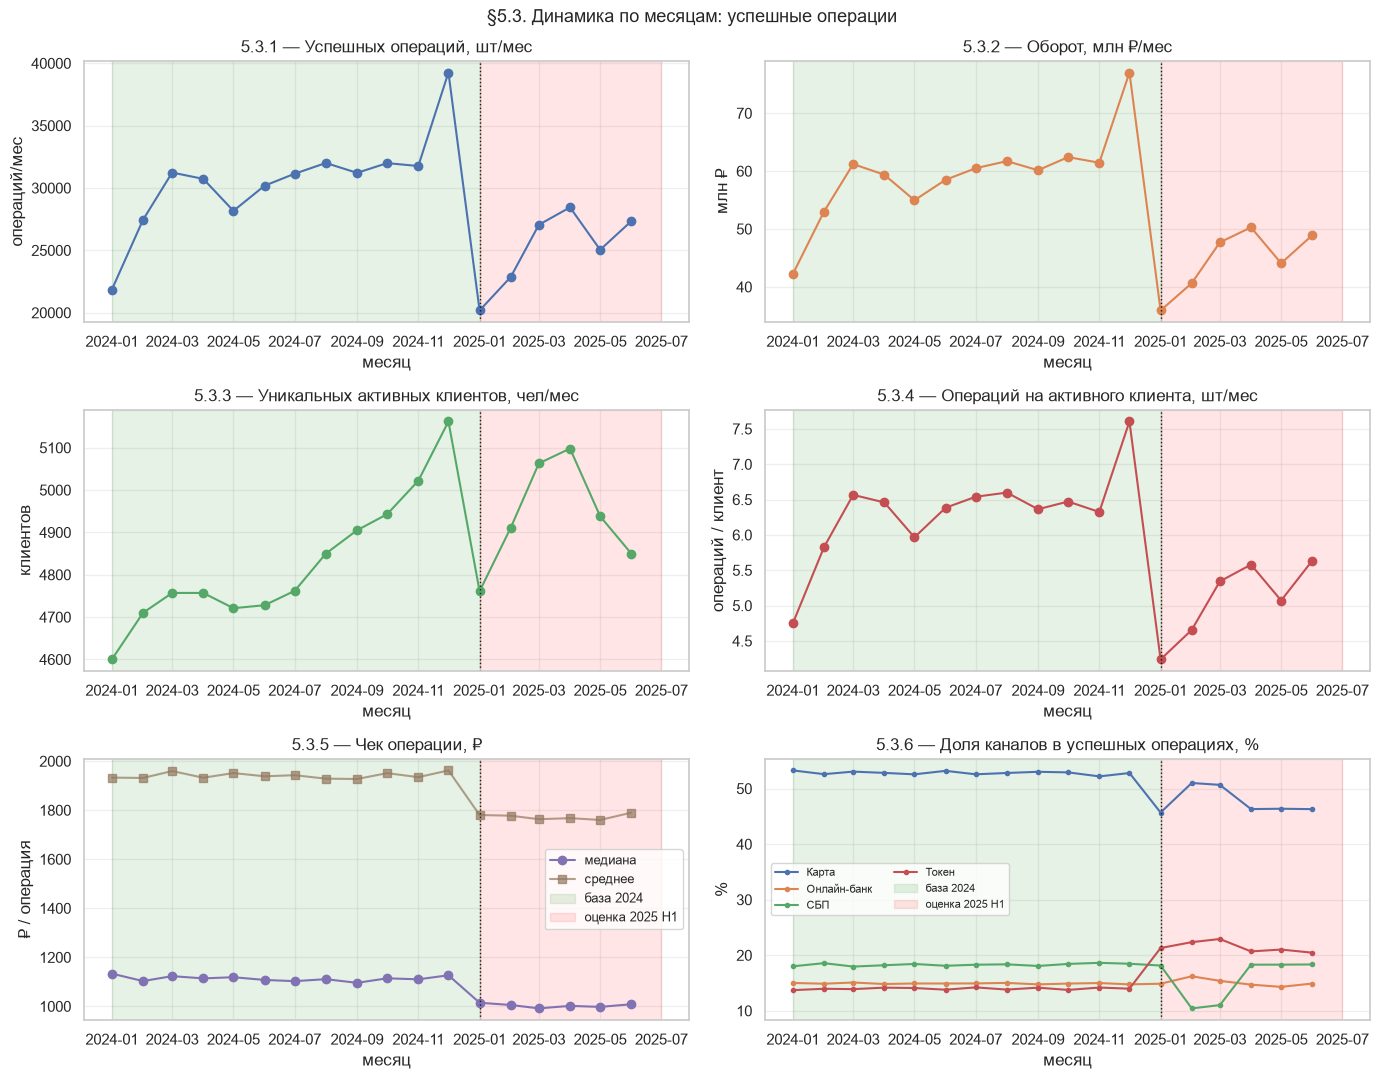

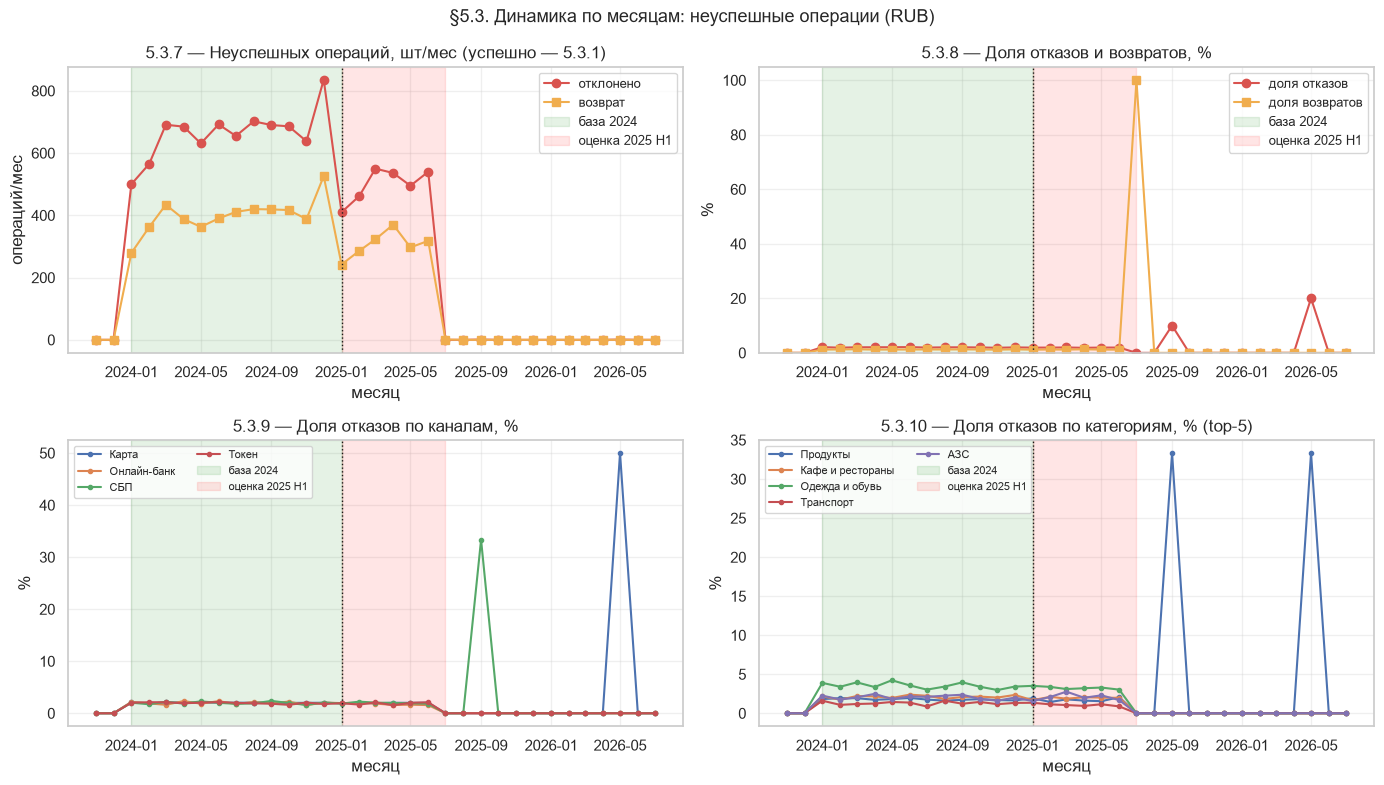

§5.3 — сводка:
  период: 2024-01 .. 2025-06, месяцев: 18
  операций (успешно) за период: 517,903
  оборот за период: 0.98 млрд ₽
  max операций в месяц: 39,259 (2024-12)
  min операций в месяц: 20,178 (2025-01)
  медиана чека: 1,105 ₽ (размах 991..1,133)
  rejection rate за период: 1.99%
  refund rate за период: 3.70%


In [295]:
# ============================================================
# §5.3 — динамика по месяцам
# ============================================================
# Что показывает: как меняется объём, состав и качество операций
# по месяцам за весь период (2024-01 .. 2025-06).
#
# Источники:
#   txn_f   — успешные RUB-операции в периоде (см. §3.5), для объёмов
#   txn_raw — все статусы, все валюты RUB, без дублей, для отказов
#
# ВАЖНО: метрика ops_c(τ) вводится в §6, здесь её нет. Все графики
# на сырых агрегатах. Это правильный порядок: сначала аудит
# (что вообще происходит с данными), потом метрика (§6), потом
# группы (§7).
#
# Нумерация 5.3.1 .. 5.3.10, каждая ось — свой показатель.


def shade_periods(ax):
    """Зелёная зона = база 2024, красная = оценка H1-2025."""
    ax.axvspan(BASE_START, BASE_END, alpha=0.10, color='green',
               label='база 2024')
    ax.axvspan(EVAL_START, EVAL_END, alpha=0.10, color='red',
               label='оценка 2025 H1')
    ax.axvline(EVAL_START, color='k', linestyle=':', linewidth=1)
    ax.grid(True, alpha=0.3)


def _month_starts(s):
    """Все 'YYYY-MM-01' от min до max, безопасно к NaT и пустому ряду."""
    s = pd.Series(s).dropna()
    if not len(s):
        return pd.DatetimeIndex([])
    return pd.date_range(
        s.min().to_period('M').to_timestamp(),
        s.max().to_period('M').to_timestamp(),
        freq='MS',
    )


# ============================================================
# Агрегаты успешных операций по месяцам
# ============================================================

full_months = _month_starts(txn_f['txn_datetime'])

m = txn_f.groupby(pd.Grouper(key='txn_datetime', freq='MS')).agg(
    n=('txn_id', 'count'),
    amt=('amount', 'sum'),
    clients=('client_id', 'nunique'),
    ticket_median=('amount', 'median'),
    ticket_mean=('amount', 'mean'),
)
if len(full_months):
    m = m.reindex(full_months)
m = m.fillna(0)                       # NaN от median/mean пустого месяца → 0
m['freq_per_client'] = (m['n'] / m['clients'].replace(0, np.nan)).fillna(0)

ch = (txn_f.groupby([pd.Grouper(key='txn_datetime', freq='MS'), 'channel'])
      .size().unstack(fill_value=0))
if len(full_months):
    ch = ch.reindex(full_months, fill_value=0)

ch_share = ch.div(ch.sum(axis=1).replace(0, np.nan), axis=0) * 100
ch_share = ch_share.fillna(0)


# ============================================================
# Figure 1: успешные операции (5.3.1 – 5.3.6)
# ============================================================
fig, axes = plt.subplots(3, 2, figsize=(14, 11))

# 5.3.1 — сколько всего успешных операций в месяц
ax = axes[0, 0]
ax.plot(m.index, m['n'], marker='o', color='C0')
shade_periods(ax)
ax.set_title('5.3.1 — Успешных операций, шт/мес')
ax.set_ylabel('операций/мес')

# 5.3.2 — оборот в млн ₽
ax = axes[0, 1]
ax.plot(m.index, m['amt'] / 1e6, marker='o', color='C1')
shade_periods(ax)
ax.set_title('5.3.2 — Оборот, млн ₽/мес')
ax.set_ylabel('млн ₽')

# 5.3.3 — сколько клиентов вообще пользовались картой в этом месяце
ax = axes[1, 0]
ax.plot(m.index, m['clients'], marker='o', color='C2')
shade_periods(ax)
ax.set_title('5.3.3 — Уникальных активных клиентов, чел/мес')
ax.set_ylabel('клиентов')

# 5.3.4 — частота: сколько операций делает один активный клиент
ax = axes[1, 1]
ax.plot(m.index, m['freq_per_client'], marker='o', color='C3')
shade_periods(ax)
ax.set_title('5.3.4 — Операций на активного клиента, шт/мес')
ax.set_ylabel('операций / клиент')

# 5.3.5 — размер чека: медиана и среднее
ax = axes[2, 0]
ax.plot(m.index, m['ticket_median'], marker='o', color='C4', label='медиана')
ax.plot(m.index, m['ticket_mean'], marker='s', color='C5', alpha=0.7,
        label='среднее')
shade_periods(ax)
ax.set_title('5.3.5 — Чек операции, ₽')
ax.set_ylabel('₽ / операция')
ax.legend(fontsize=9)

# 5.3.6 — структура каналов: доля каждой, сумма = 100% в каждом месяце
ax = axes[2, 1]
for c in ch_share.columns:
    ax.plot(ch_share.index, ch_share[c], marker='o', markersize=3, label=str(c))
shade_periods(ax)
ax.set_title('5.3.6 — Доля каналов в успешных операциях, %')
ax.set_ylabel('%')
ax.legend(fontsize=8, ncol=2)

for ax in axes.flat:
    if not len(m):
        ax.text(0.5, 0.5, 'нет данных за период',
                ha='center', va='center', transform=ax.transAxes)
    ax.set_xlabel('месяц')

fig.suptitle('§5.3. Динамика по месяцам: успешные операции',
             fontsize=13)
plt.tight_layout()
plt.show()


# ============================================================
# Агрегаты неуспешных операций по месяцам
# ============================================================
tx = txn_raw[txn_raw['currency'] == 'RUB'].copy()
tx = tx[tx['txn_datetime'].notna() & tx['status'].notna()]
tx['month'] = tx['txn_datetime'].dt.to_period('M').dt.to_timestamp()

tx_months = _month_starts(tx['month'])

status_month = tx.groupby(['month', 'status']).size().unstack(fill_value=0)
for col in ['успешно', 'отклонено', 'возврат']:
    if col not in status_month.columns:
        status_month[col] = 0
status_month = status_month[['успешно', 'отклонено', 'возврат']]
if len(tx_months):
    status_month = status_month.reindex(tx_months, fill_value=0)

attempts = status_month['успешно'] + status_month['отклонено']
rej_rate = (status_month['отклонено'] / attempts.replace(0, np.nan) * 100).fillna(0)
ref_rate = (status_month['возврат']  / status_month['успешно'].replace(0, np.nan) * 100).fillna(0)

# rejection rate по каналам (по месяцам)
ch_stat = tx.groupby(['month', 'channel', 'status']).size() \
            .unstack('status', fill_value=0)
for col in ['успешно', 'отклонено']:
    if col not in ch_stat.columns:
        ch_stat[col] = 0
ch_rej_month = ((ch_stat['отклонено'] /
                 (ch_stat['успешно'] + ch_stat['отклонено'])
                 .replace(0, np.nan)) * 100).unstack('channel')
if len(tx_months):
    ch_rej_month = ch_rej_month.reindex(tx_months).fillna(0)
else:
    ch_rej_month = ch_rej_month.fillna(0)

# rejection rate по категориям (по месяцам)
cat_stat = tx.groupby(['month', 'category', 'status']).size() \
             .unstack('status', fill_value=0)
for col in ['успешно', 'отклонено']:
    if col not in cat_stat.columns:
        cat_stat[col] = 0
cat_rej_month = ((cat_stat['отклонено'] /
                  (cat_stat['успешно'] + cat_stat['отклонено'])
                  .replace(0, np.nan)) * 100).unstack('category')
if len(tx_months):
    cat_rej_month = cat_rej_month.reindex(tx_months).fillna(0)
else:
    cat_rej_month = cat_rej_month.fillna(0)

top_cats = tx['category'].value_counts().head(5).index.tolist()


# ============================================================
# Figure 2: неуспешные операции (5.3.7 – 5.3.10)
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# 5.3.7 — абсолютный объём неуспешных: отказы и возвраты в месяц
ax = axes[0, 0]
ax.plot(status_month.index, status_month['отклонено'], marker='o',
        color='#D9534F', label='отклонено')
ax.plot(status_month.index, status_month['возврат'], marker='s',
        color='#F0AD4E', label='возврат')
shade_periods(ax)
ax.set_title('5.3.7 — Неуспешных операций, шт/мес (успешно — 5.3.1)')
ax.set_ylabel('операций/мес')
ax.set_xlabel('месяц')
ax.legend(fontsize=9)

# 5.3.8 — доля отказов и возвратов
ax = axes[0, 1]
ax.plot(rej_rate.index, rej_rate.values, marker='o',
        color='#D9534F', label='доля отказов')
ax.plot(ref_rate.index, ref_rate.values, marker='s',
        color='#F0AD4E', label='доля возвратов')
shade_periods(ax)
ax.set_title('5.3.8 — Доля отказов и возвратов, %')
ax.set_ylabel('%')
ax.set_ylim(0, None)
ax.set_xlabel('месяц')
ax.legend(fontsize=9)

# 5.3.9 — откуда отказы: по каналам
ax = axes[1, 0]
for c in ch_rej_month.columns:
    ax.plot(ch_rej_month.index, ch_rej_month[c], marker='o',
            markersize=3, label=str(c))
shade_periods(ax)
ax.set_title('5.3.9 — Доля отказов по каналам, %')
ax.set_ylabel('%')
ax.set_xlabel('месяц')
ax.legend(fontsize=8, ncol=2)

# 5.3.10 — в каких категориях отказывают чаще (top-5 по объёму)
ax = axes[1, 1]
for c in top_cats:
    if c in cat_rej_month.columns:
        ax.plot(cat_rej_month.index, cat_rej_month[c], marker='o',
                markersize=3, label=str(c))
shade_periods(ax)
ax.set_title('5.3.10 — Доля отказов по категориям, % (top-5)')
ax.set_ylabel('%')
ax.set_xlabel('месяц')
ax.legend(fontsize=8, ncol=2)

for ax in axes.flat:
    if not len(status_month):
        ax.text(0.5, 0.5, 'нет данных за период',
                ha='center', va='center', transform=ax.transAxes)

fig.suptitle('§5.3. Динамика по месяцам: неуспешные операции (RUB)',
             fontsize=13)
plt.tight_layout()
plt.show()


# ============================================================
# Сводка для текста отчёта
# ============================================================
print('§5.3 — сводка:')
if len(m) and pd.notna(m.index.min()) and pd.notna(m.index.max()):
    print(f'  период: {m.index.min().strftime("%Y-%m")} .. '
          f'{m.index.max().strftime("%Y-%m")}, месяцев: {len(m)}')
    print(f'  операций (успешно) за период: {int(m["n"].sum()):,}')
    print(f'  оборот за период: {m["amt"].sum()/1e9:.2f} млрд ₽')
    print(f'  max операций в месяц: '
          f'{int(m["n"].max()):,} ({m["n"].idxmax().strftime("%Y-%m")})')
    print(f'  min операций в месяц: '
          f'{int(m["n"].min()):,} ({m["n"].idxmin().strftime("%Y-%m")})')
    print(f'  медиана чека: '
          f'{int(m["ticket_median"].median()):,} ₽ '
          f'(размах {int(m["ticket_median"].min()):,}..'
          f'{int(m["ticket_median"].max()):,})')
    print(f'  rejection rate за период: {rej_rate.mean():.2f}%')
    print(f'  refund rate за период: {ref_rate.mean():.2f}%')
else:
    print('  (нет успешных операций за период — нечего суммировать)')

### 5.4. Разрезы и связи между признаками

Поскольку главная метрика определяется в следующем разделе большинство графиков показывающих её связь другими признаками или отсутсвие таковой будут там же, после её определения.

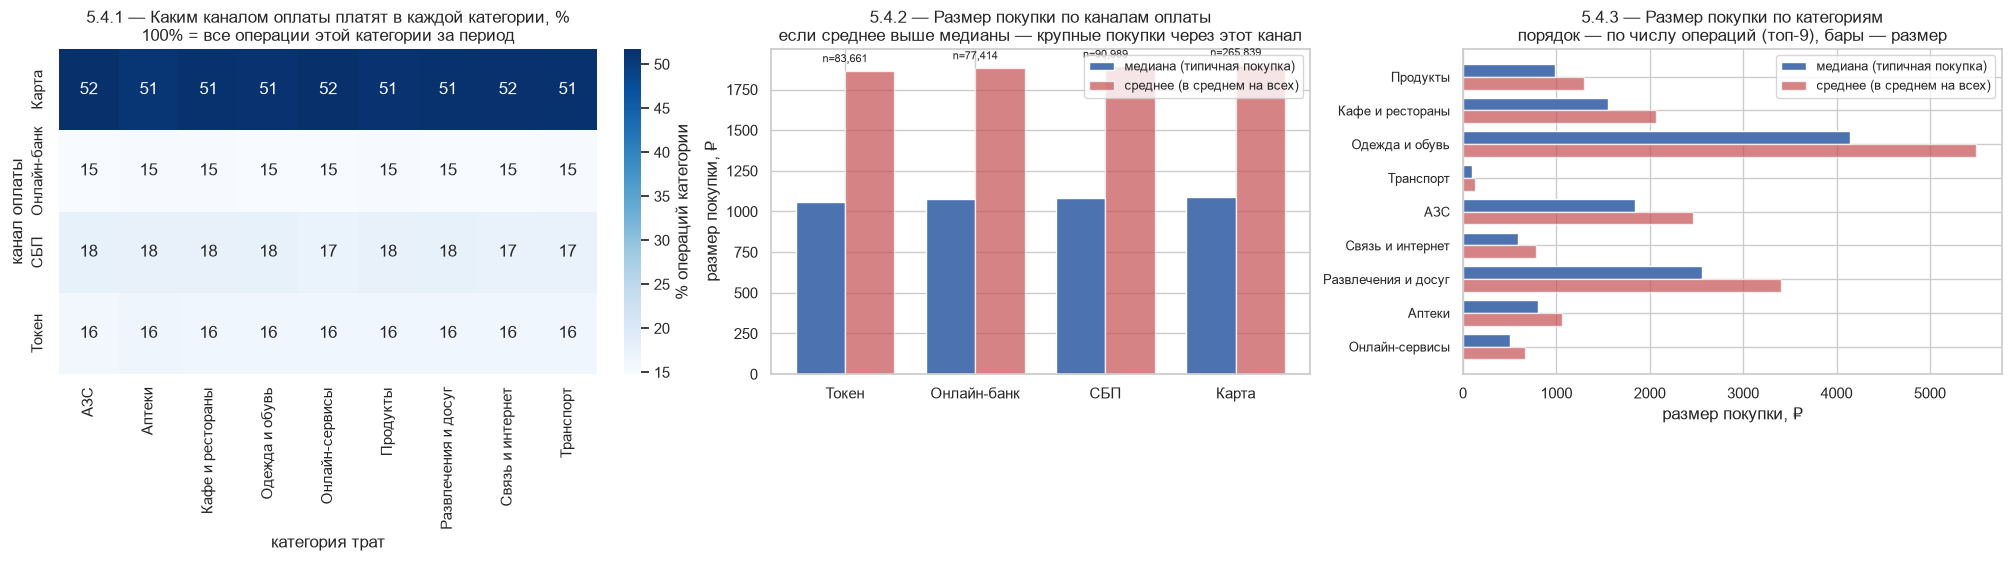

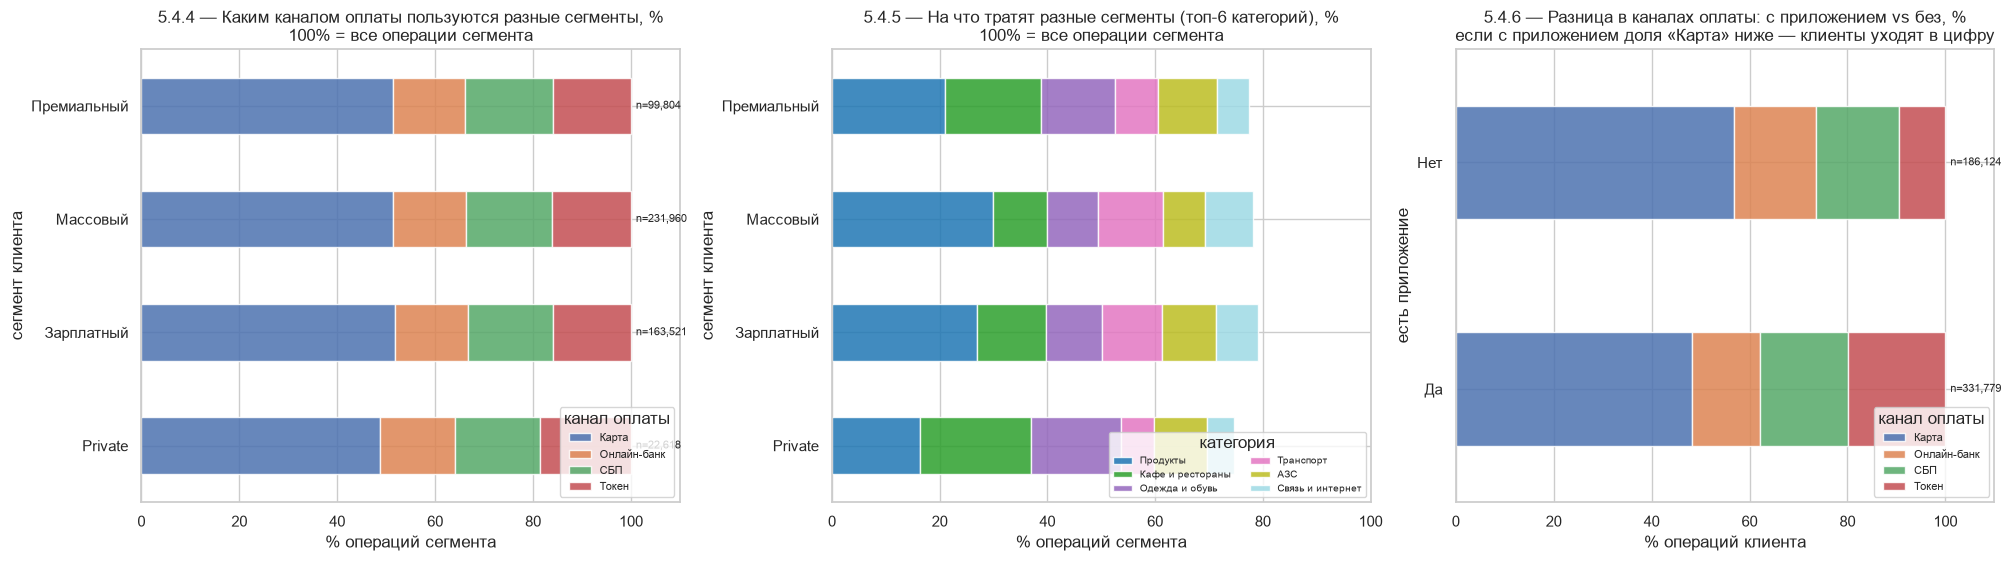

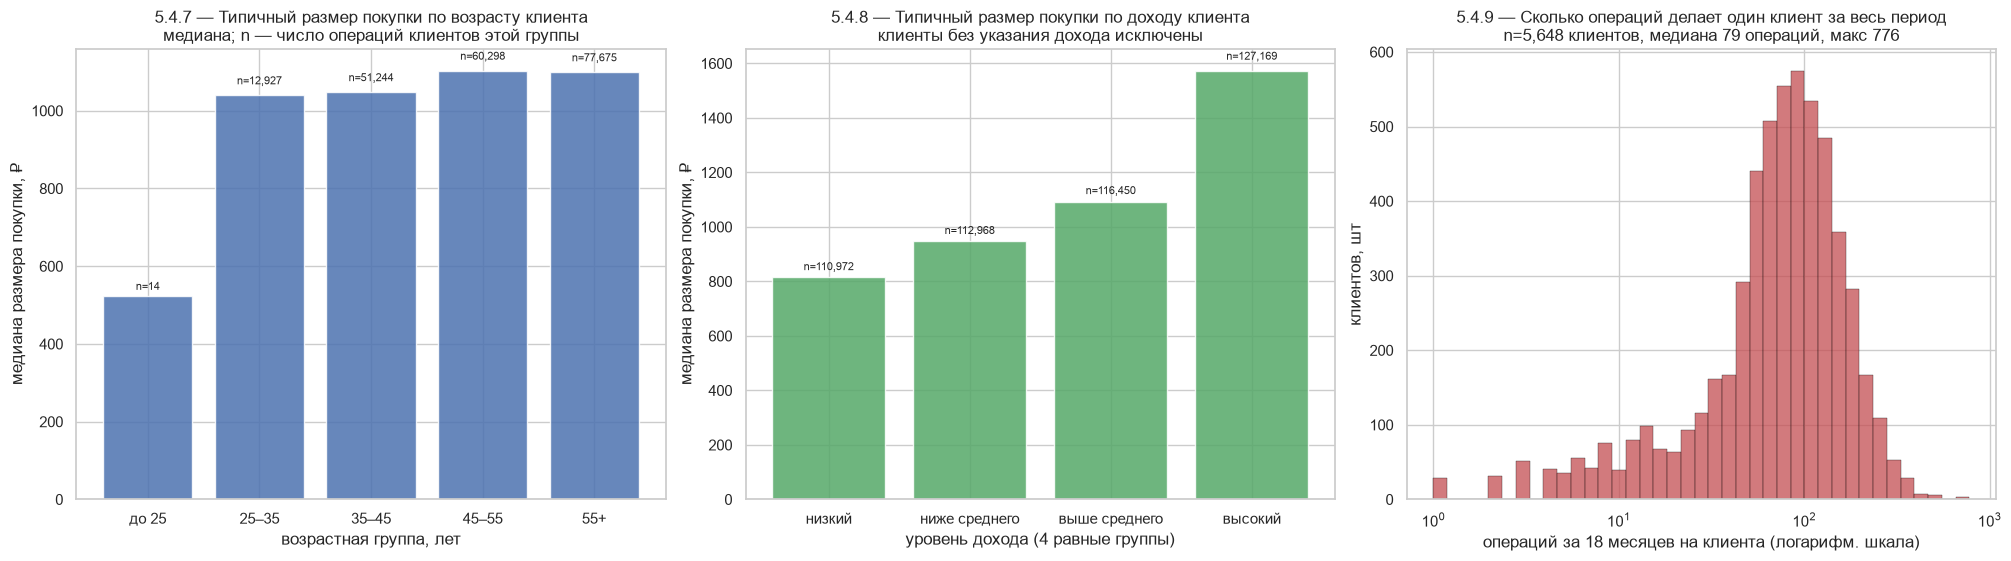

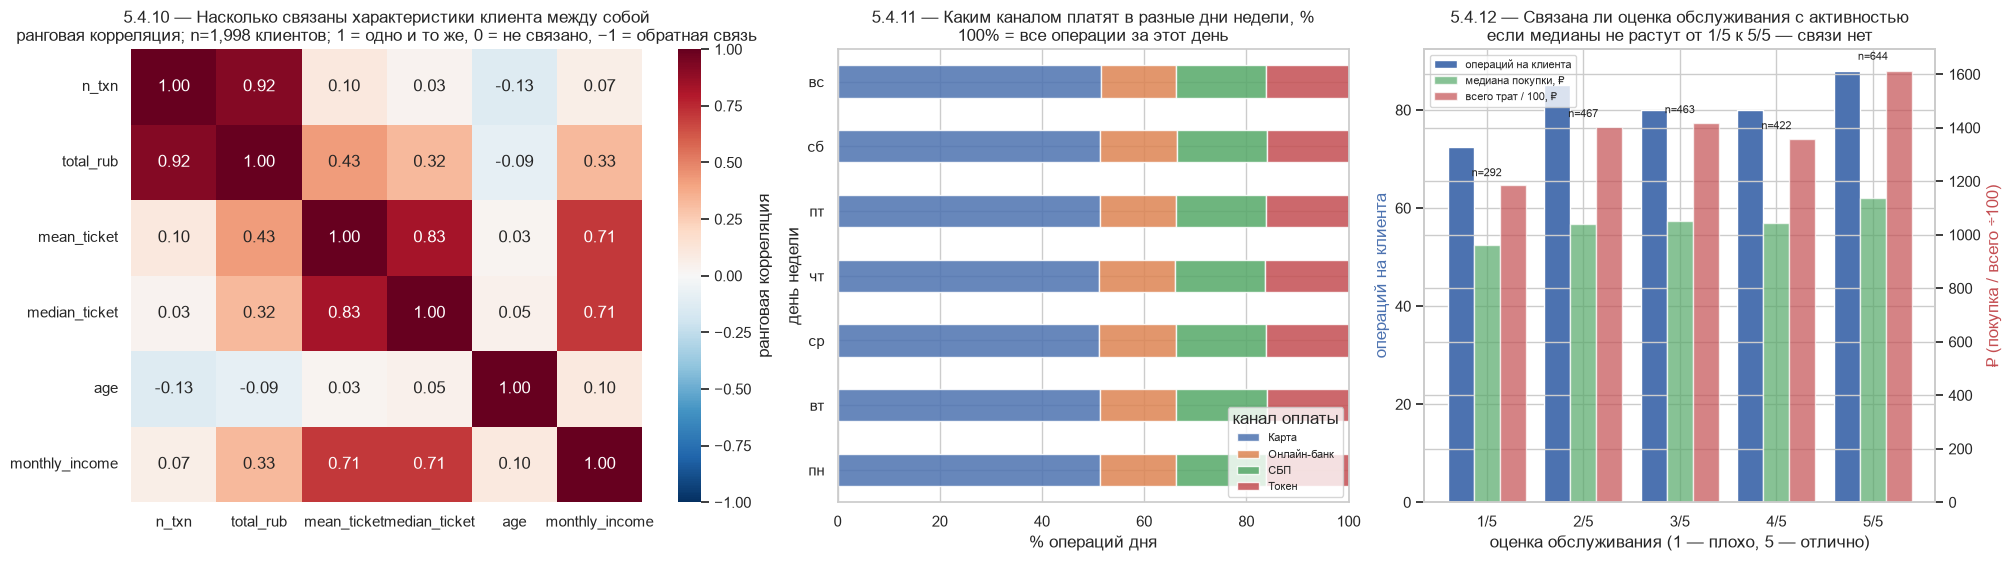

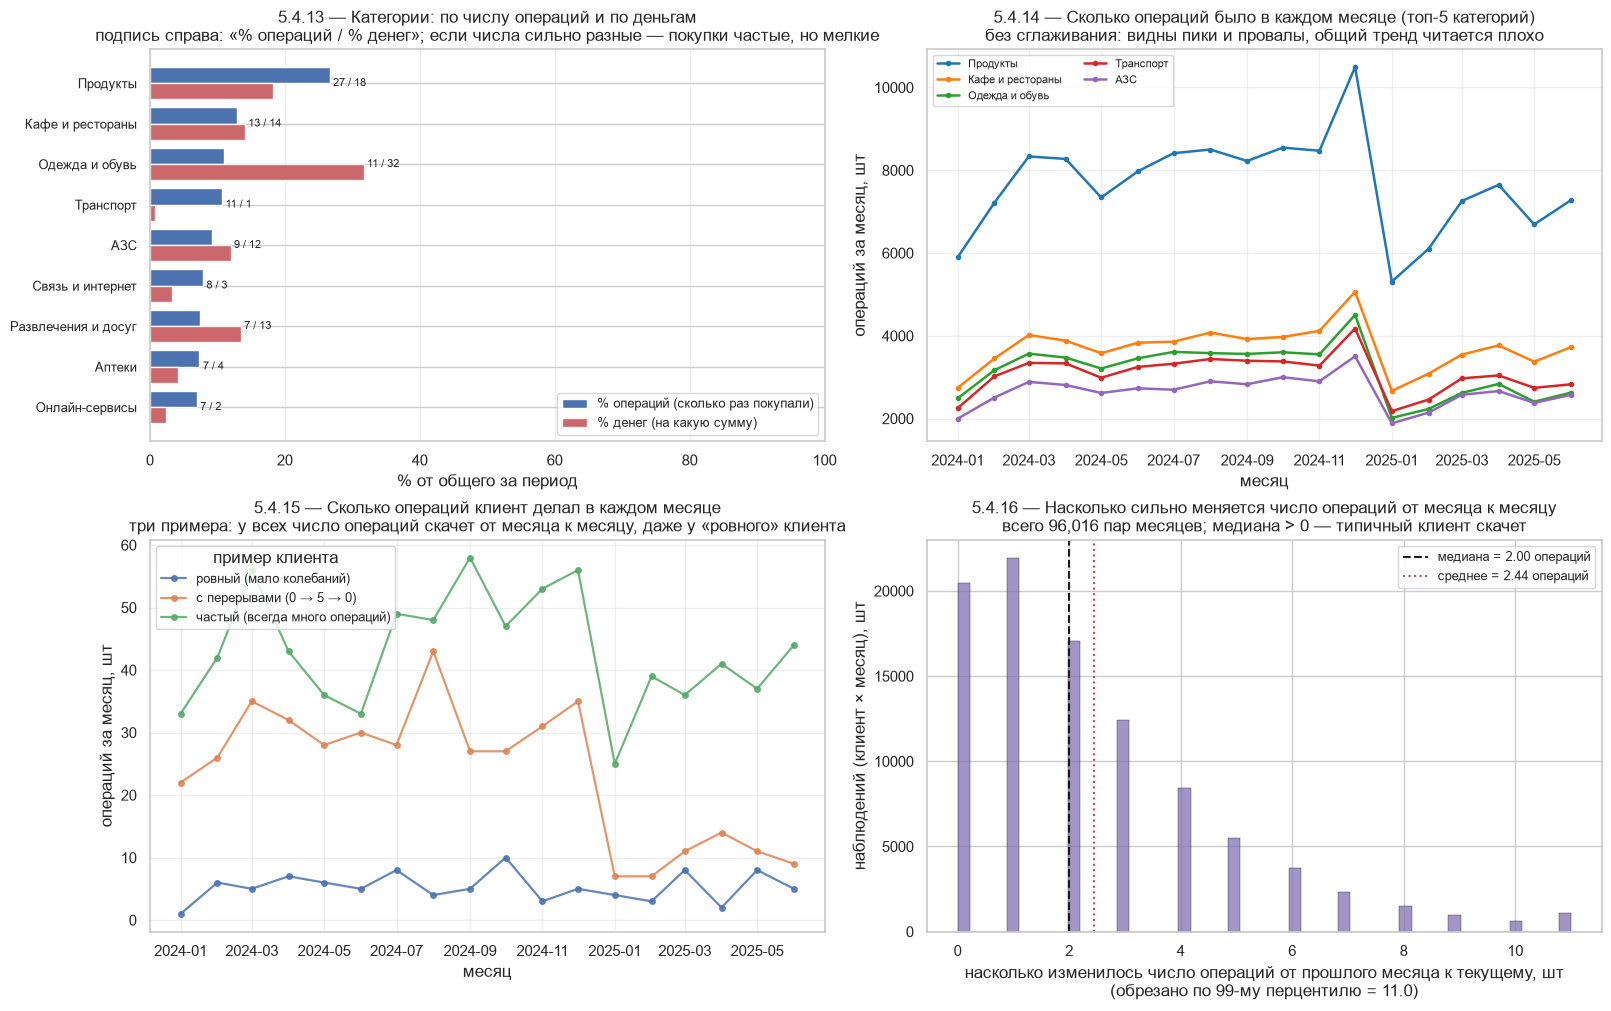

§5.4 — сводка:
  категорий: 9, каналов: 4
  операций в анализе: 517,903
  клиентов с операциями: 5,648

доли категорий: % операций vs % денег (5.4.13):
  Продукты              операции  26.6%  деньги  18.3%  (n_ops= 137,982, оборот=  179.0 млн ₽)
  Кафе и рестораны      операции  12.9%  деньги  14.1%  (n_ops=  66,692, оборот=  138.0 млн ₽)
  Одежда и обувь        операции  10.9%  деньги  31.7%  (n_ops=  56,525, оборот=  310.5 млн ₽)
  Транспорт             операции  10.7%  деньги   0.7%  (n_ops=  55,411, оборот=    7.2 млн ₽)
  АЗС                   операции   9.2%  деньги  11.9%  (n_ops=  47,611, оборот=  117.1 млн ₽)
  Связь и интернет      операции   7.9%  деньги   3.2%  (n_ops=  40,782, оборот=   31.8 млн ₽)
  Развлечения и досуг   операции   7.5%  деньги  13.5%  (n_ops=  38,767, оборот=  132.1 млн ₽)
  Аптеки                операции   7.3%  деньги   4.1%  (n_ops=  38,048, оборот=   40.4 млн ₽)
  Онлайн-сервисы        операции   7.0%  деньги   2.4%  (n_ops=  36,085, оборот=   24.0 

In [296]:
# ============================================================
# §5.4 — разрезы и связи между признаками
# ============================================================
# Что в этом разделе:
#   5.4.1–5.4.6   — какими каналами и на что тратят клиенты
#   5.4.7–5.4.9   — как размер покупки зависит от клиента
#   5.4.10–5.4.12 — связи между характеристиками клиента
#   5.4.13–5.4.16 — зачем нужно сглаживание (см. §6)
#
# Термины, которые дальше встречаются:
#   медиана — «типичное» значение. Если покупатели тратят 200, 300,
#     и один 100 000 ₽, среднее будет 33 800, но медиана — 300.
#     Медиана устойчива к разовым крупным покупкам, поэтому
#     используется рядом со средним.
#   среднее — арифметическое. Показывает «в среднем на всех»,
#     но легко сдвигается одной большой покупкой.
#   доля — процент от какой-то базы (100% = все операции сегмента /
#     категории / дня). В подписи каждой оси база указана.
#   сглаживание — замена сырых чисел «усреднённой» оценкой тренда.
#     Подробно в §6.
#
# О корреляции 5.4.10: используется ранговая корреляция Спирмена,
# не Пирсона. Причина:
#   • число операций на клиента — счётчик (0, 1, 2, …). Распределение
#     смещено вправо (несколько клиентов с сотнями операций), поэтому
#     обычная линейная корреляция (Пирсон) даст число, зависящее
#     от этих нескольких клиентов;
#   • сумма трат, средний чек — тоже смещены вправо;
#   • ранговая корреляция смотрит на «кто выше/ниже кого» (по рангам),
#     устойчива к выбросам и смещениям, работает для счётчиков
#     и оценок 1–5.
#   • satisfaction_score — оценка от 1 до 5, Пирсон на ней
#     математически невалиден (разница «1 балл» не определена).
#     Смотрится отдельно в 5.4.12 через медианы по каждой оценке.
#
# Все графики с layout='constrained', без plt.tight_layout().

REF_DATE = pd.Timestamp('2025-06-30')

cl = clients.copy()
cl['age'] = (REF_DATE - cl['birth_date']).dt.days / 365.25
cl['age_bucket'] = pd.cut(cl['age'],
                          bins=[0, 25, 35, 45, 55, 100],
                          labels=['до 25', '25–35', '35–45', '45–55', '55+'])
_inc_ok = cl['monthly_income'].notna()
cl.loc[_inc_ok, 'income_bucket'] = pd.qcut(
    cl.loc[_inc_ok, 'monthly_income'], q=4,
    labels=['низкий', 'ниже среднего', 'выше среднего', 'высокий'])
CLIENT_COLS = ['client_id', 'segment', 'loyalty_tier', 'card_type',
               'has_mobile_app', 'gender', 'age', 'age_bucket',
               'monthly_income', 'income_bucket', 'satisfaction_score']

txc = txn_f.merge(cl[CLIENT_COLS], on='client_id', how='left')


# ============================================================
# Figure 1: каналы, категории, размер покупки (5.4.1 — 5.4.3)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), layout='constrained')

# 5.4.1 — доля канала внутри категории
# Вопрос: «в каждой категории покупок какой долей платят
# пластиковой картой, какой — телефоном, какой — переводом?»
ax = axes[0]
ct = pd.crosstab(txc['channel'], txc['category'], normalize='columns') * 100
sns.heatmap(ct, annot=True, fmt='.0f', cmap='Blues', ax=ax,
            cbar_kws={'label': '% операций категории'})
ax.set_title('5.4.1 — Каким каналом оплаты платят в каждой категории, %\n'
             '100% = все операции этой категории за период')
ax.set_xlabel('категория трат')
ax.set_ylabel('канал оплаты')

# 5.4.2 — размер покупки по каналам: медиана vs среднее
# Вопрос: «через какой канал тратят больше за одну покупку?»
ax = axes[1]
ch_stats = txn_f.groupby('channel')['amount'].agg(
    ['median', 'mean', 'count']).sort_values('median')
x = np.arange(len(ch_stats))
w = 0.38
ax.bar(x - w/2, ch_stats['median'], w, color='C0',
       label='медиана (типичная покупка)')
ax.bar(x + w/2, ch_stats['mean'],  w, color='C3', alpha=0.7,
       label='среднее (в среднем на всех)')
for i, (med, mean, n) in enumerate(ch_stats[['median', 'mean', 'count']].values):
    ax.text(i, max(med, mean) * 1.02, f'n={int(n):,}',
            ha='center', va='bottom', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(ch_stats.index)
ax.set_ylabel('размер покупки, ₽')
ax.set_title('5.4.2 — Размер покупки по каналам оплаты\n'
             'если среднее выше медианы — крупные покупки через этот канал')
ax.legend(fontsize=9)

# 5.4.3 — размер покупки по категориям
ax = axes[2]
cat_stats = txn_f.groupby('category')['amount'].agg(
    ['median', 'mean', 'count']).sort_values('count', ascending=False).head(9)
x = np.arange(len(cat_stats))
ax.barh(x - w/2, cat_stats['median'], w, color='C0',
        label='медиана (типичная покупка)')
ax.barh(x + w/2, cat_stats['mean'],  w, color='C3', alpha=0.7,
        label='среднее (в среднем на всех)')
ax.set_yticks(x)
ax.set_yticklabels(cat_stats.index, fontsize=9)
ax.set_xlabel('размер покупки, ₽')
ax.set_title('5.4.3 — Размер покупки по категориям\n'
             'порядок — по числу операций (топ-9), бары — размер')
ax.invert_yaxis()
ax.legend(fontsize=9)

plt.show()


# ============================================================
# Figure 2: сегменты клиента и их операции (5.4.4 — 5.4.6)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), layout='constrained')

# 5.4.4 — доля каналов оплаты внутри сегмента
ax = axes[0]
ct = pd.crosstab(txc['segment'], txc['channel'], normalize='index') * 100
ct.plot.barh(stacked=True, ax=ax, color=['C0', 'C1', 'C2', 'C3'], alpha=0.85)
for i, seg in enumerate(ct.index):
    ax.text(101, i, f'n={int((txc["segment"] == seg).sum()):,}',
            va='center', fontsize=8)
ax.set_xlabel('% операций сегмента')
ax.set_ylabel('сегмент клиента')
ax.set_title('5.4.4 — Каким каналом оплаты пользуются разные сегменты, %\n'
             '100% = все операции сегмента')
ax.legend(title='канал оплаты', fontsize=8, loc='lower right')
ax.set_xlim(0, 110)

# 5.4.5 — доля категорий трат внутри сегмента
ax = axes[1]
top6 = txn_f['category'].value_counts().head(6).index.tolist()
ct = pd.crosstab(txc['segment'], txc['category'], normalize='index') * 100
ct = ct.reindex(columns=top6, fill_value=0)
ct.plot.barh(stacked=True, ax=ax, colormap='tab20', alpha=0.85)
ax.set_xlabel('% операций сегмента')
ax.set_ylabel('сегмент клиента')
ax.set_title('5.4.5 — На что тратят разные сегменты (топ-6 категорий), %\n'
             '100% = все операции сегмента')
ax.legend(title='категория', fontsize=7, loc='lower right', ncol=2)
ax.set_xlim(0, 100)

# 5.4.6 — каналы оплаты: клиенты с приложением и без
ax = axes[2]
ct = pd.crosstab(txc['has_mobile_app'], txc['channel'], normalize='index') * 100
ct.plot.barh(stacked=True, ax=ax, color=['C0', 'C1', 'C2', 'C3'], alpha=0.85)
for i, app in enumerate(ct.index):
    ax.text(101, i, f'n={int((txc["has_mobile_app"] == app).sum()):,}',
            va='center', fontsize=8)
ax.set_xlabel('% операций клиента')
ax.set_ylabel('есть приложение')
ax.set_title('5.4.6 — Разница в каналах оплаты: с приложением vs без, %\n'
             'если с приложением доля «Карта» ниже — клиенты уходят в цифру')
ax.legend(title='канал оплаты', fontsize=8, loc='lower right')
ax.set_xlim(0, 110)

plt.show()


# ============================================================
# Figure 3: возраст, доход, число операций на клиента
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), layout='constrained')

# 5.4.7 — размер покупки по возрасту
ax = axes[0]
age_chk = txc.dropna(subset=['age_bucket']).groupby(
    'age_bucket', observed=True)['amount'].agg(['median', 'count'])
ax.bar(age_chk.index.astype(str), age_chk['median'], color='C0', alpha=0.85)
for i, (med, n) in enumerate(age_chk[['median', 'count']].values):
    ax.text(i, med * 1.02, f'n={int(n):,}', ha='center', va='bottom', fontsize=8)
ax.set_xlabel('возрастная группа, лет')
ax.set_ylabel('медиана размера покупки, ₽')
ax.set_title('5.4.7 — Типичный размер покупки по возрасту клиента\n'
             'медиана; n — число операций клиентов этой группы')

# 5.4.8 — размер покупки по доходу
ax = axes[1]
inc_chk = txc.dropna(subset=['income_bucket']).groupby(
    'income_bucket', observed=True)['amount'].agg(['median', 'count'])
ax.bar(inc_chk.index.astype(str), inc_chk['median'], color='C2', alpha=0.85)
for i, (med, n) in enumerate(inc_chk[['median', 'count']].values):
    ax.text(i, med * 1.02, f'n={int(n):,}', ha='center', va='bottom', fontsize=8)
ax.set_xlabel('уровень дохода (4 равные группы)')
ax.set_ylabel('медиана размера покупки, ₽')
ax.set_title('5.4.8 — Типичный размер покупки по доходу клиента\n'
             'клиенты без указания дохода исключены')

# 5.4.9 — сколько операций делает один клиент за весь период
ax = axes[2]
n_per_client = txn_f.groupby('client_id').size()
bins = np.logspace(0, np.log10(n_per_client.max() + 1), 40)
ax.hist(n_per_client, bins=bins, color='C3', alpha=0.75,
        edgecolor='black', linewidth=0.3)
ax.set_xscale('log')
ax.set_xlabel('операций за 18 месяцев на клиента (логарифм. шкала)')
ax.set_ylabel('клиентов, шт')
ax.set_title(f'5.4.9 — Сколько операций делает один клиент за весь период\n'
             f'n={len(n_per_client):,} клиентов, медиана '
             f'{int(n_per_client.median())} операций, '
             f'макс {int(n_per_client.max())}')

plt.show()


# ============================================================
# Figure 4: связи характеристик, дни недели, satisfaction
# ============================================================
per_client = (txn_f.groupby('client_id')['amount']
              .agg(n_txn='count', total_rub='sum', median_ticket='median')
              .reset_index())
per_client = per_client.merge(
    cl[['client_id', 'age', 'monthly_income', 'satisfaction_score']],
    on='client_id', how='left')
per_client['mean_ticket'] = (per_client['total_rub'] /
                             per_client['n_txn'].replace(0, np.nan))

NUMERIC_COLS = ['n_txn', 'total_rub', 'mean_ticket',
                'median_ticket', 'age', 'monthly_income']
corr_df = per_client[NUMERIC_COLS].dropna()
corr_matrix = corr_df.corr(method='spearman')

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), layout='constrained')

# 5.4.10 — ранговая корреляция (Спирмен)
ax = axes[0]
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            vmin=-1, vmax=1, ax=ax, cbar_kws={'label': 'ранговая корреляция'})
ax.set_title(f'5.4.10 — Насколько связаны характеристики клиента между собой\n'
             f'ранговая корреляция; n={len(corr_df):,} клиентов; '
             f'1 = одно и то же, 0 = не связано, −1 = обратная связь')

# 5.4.11 — доля каналов оплаты по дням недели
ax = axes[1]
tx_weekday = txn_f.copy()
tx_weekday['weekday'] = tx_weekday['txn_datetime'].dt.day_name().str[:3]
weekday_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekday_ru = {'Mon': 'пн', 'Tue': 'вт', 'Wed': 'ср', 'Thu': 'чт',
              'Fri': 'пт', 'Sat': 'сб', 'Sun': 'вс'}
ct = pd.crosstab(tx_weekday['weekday'], tx_weekday['channel'],
                 normalize='index') * 100
ct = ct.reindex(weekday_order, fill_value=0)
ct.index = [weekday_ru[w] for w in ct.index]
ct.plot.barh(stacked=True, ax=ax, color=['C0', 'C1', 'C2', 'C3'], alpha=0.85)
ax.set_xlabel('% операций дня')
ax.set_ylabel('день недели')
ax.set_title('5.4.11 — Каким каналом платят в разные дни недели, %\n'
             '100% = все операции за этот день')
ax.legend(title='канал оплаты', fontsize=8, loc='lower right')
ax.set_xlim(0, 100)

# 5.4.12 — связана ли оценка обслуживания с активностью
ax = axes[2]
sat_data = per_client.dropna(subset=['satisfaction_score']).copy()
sat_stats = sat_data.groupby('satisfaction_score').agg(
    n_clients=('client_id', 'size'),
    median_n_txn=('n_txn', 'median'),
    median_ticket=('median_ticket', 'median'),
    median_total=('total_rub', 'median'),
)
x = np.arange(len(sat_stats))
w = 0.27
ax.bar(x - w, sat_stats['median_n_txn'], w, color='C0',
       label='операций на клиента')

ax2 = ax.twinx()
ax2.bar(x, sat_stats['median_ticket'], w, color='C2',
        alpha=0.7, label='медиана покупки, ₽')
ax2.bar(x + w, sat_stats['median_total'] / 100, w, color='C3',
        alpha=0.7, label='всего трат / 100, ₽')

for i, (n_txn, tick, tot, n_cl) in enumerate(
        sat_stats[['median_n_txn', 'median_ticket',
                   'median_total', 'n_clients']].values):
    ax2.text(i, max(tick, tot/100) * 1.02,
             f'n={int(n_cl)}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([f'{int(s)}/5' for s in sat_stats.index])
ax.set_ylabel('операций на клиента', color='C0')
ax2.set_ylabel('₽ (покупка / всего ÷100)', color='C3')
ax.set_xlabel('оценка обслуживания (1 — плохо, 5 — отлично)')
ax.set_title('5.4.12 — Связана ли оценка обслуживания с активностью\n'
             'если медианы не растут от 1/5 к 5/5 — связи нет')

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2,
          fontsize=8, loc='upper left')

plt.show()


# ============================================================
# Figure 5: зачем нужно сглаживание (5.4.13 — 5.4.16)
# ============================================================
# Сырое число операций за месяц сильно колеблется даже у клиента,
# который не изменил поведение: месяц без покупок, потом месяц
# с несколькими, снова без. Если «падение активности» считать
# по сырому числу, метрика поймает шум, а не реальный уход.
# В §6 вводится сглаженная метрика ops_c, которая гасит шум.

fig, axes = plt.subplots(2, 2, figsize=(16, 10), layout='constrained')

# 5.4.13 — доли категорий: по числу операций и по деньгам
ax = axes[0, 0]
cat_total = (txn_f.groupby('category')
             .agg(n_ops=('txn_id', 'count'),
                  amount=('amount', 'sum'))
             .sort_values('n_ops', ascending=False))
cat_total['ops_share']    = cat_total['n_ops'] / cat_total['n_ops'].sum() * 100
cat_total['amount_share'] = (cat_total['amount'] /
                             cat_total['amount'].sum() * 100)

x = np.arange(len(cat_total))
w = 0.4
ax.barh(x - w/2, cat_total['ops_share'],    w, color='C0',
        label='% операций (сколько раз покупали)')
ax.barh(x + w/2, cat_total['amount_share'], w, color='C3', alpha=0.85,
        label='% денег (на какую сумму)')
for i, (ops_sh, amt_sh) in enumerate(
        cat_total[['ops_share', 'amount_share']].values):
    ax.text(max(ops_sh, amt_sh) + 0.5, i,
            f'{ops_sh:.0f} / {amt_sh:.0f}',
            va='center', fontsize=8)
ax.set_yticks(x)
ax.set_yticklabels(cat_total.index, fontsize=9)
ax.set_xlabel('% от общего за период')
ax.set_xlim(0, 100)
ax.set_title('5.4.13 — Категории: по числу операций и по деньгам\n'
             'подпись справа: «% операций / % денег»; '
             'если числа сильно разные — покупки частые, но мелкие')
ax.invert_yaxis()
ax.legend(fontsize=9, loc='lower right')
ax.grid(alpha=0.3, axis='x')

# 5.4.14 — сырое число операций по месяцам (топ-5 категорий)
ax = axes[0, 1]
cat_month = (txn_f.groupby([pd.Grouper(key='txn_datetime', freq='MS'),
                            'category']).size().unstack(fill_value=0))
top5 = txn_f['category'].value_counts().head(5).index.tolist()
for cat, color in zip(top5, plt.cm.tab10.colors):
    if cat in cat_month.columns:
        ax.plot(cat_month.index, cat_month[cat].values, '-',
                color=color, lw=1.8, marker='o', markersize=3, label=cat)
ax.set_xlabel('месяц')
ax.set_ylabel('операций за месяц, шт')
ax.set_title('5.4.14 — Сколько операций было в каждом месяце '
             '(топ-5 категорий)\n'
             'без сглаживания: видны пики и провалы, '
             'общий тренд читается плохо')
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)

# 5.4.15 — три клиента: как выглядит история их операций
# Каждая линия — один клиент. Ось X — месяц, ось Y — сколько
# операций клиент сделал в этом месяце.
#
# Смысл: показать, что даже у клиента, который в целом не изменил
# поведение, число операций за конкретный месяц может быть 0,
# а через месяц 5. Без сглаживания мы видим эти колебания и
# не можем отличить шум от реального изменения.
ax = axes[1, 0]
tx_per_client_month = (txn_f
                       .groupby(['client_id',
                                 pd.Grouper(key='txn_datetime', freq='MS')])
                       .size().unstack(fill_value=0))
mean_level = tx_per_client_month.mean(axis=1)
std_level = tx_per_client_month.std(axis=1)
active = mean_level[mean_level > 0].index

if len(active) >= 3:
    s = std_level.loc[active].sort_values()
    n_a = len(s)
    examples = [
        ('ровный (мало колебаний)',          s.index[n_a // 2],           'C0'),
        ('с перерывами (0 → 5 → 0)',         s.index[-1],                 'C1'),
        ('частый (всегда много операций)',   mean_level.loc[active].idxmax(), 'C2'),
    ]
    for label, cid, color in examples:
        vals = tx_per_client_month.loc[cid].values
        ax.plot(tx_per_client_month.columns, vals,
                '-o', color=color, markersize=4, lw=1.6, alpha=0.85,
                label=label)

ax.set_xlabel('месяц')
ax.set_ylabel('операций за месяц, шт')
ax.set_title('5.4.15 — Сколько операций клиент делал в каждом месяце\n'
             'три примера: у всех число операций скачет от месяца '
             'к месяцу, даже у «ровного» клиента')
ax.legend(fontsize=9, loc='upper left', title='пример клиента')
ax.grid(alpha=0.3)

# 5.4.16 — насколько сильно меняется число операций между месяцами
# Для каждого клиента сравниваем «сколько операций в этом месяце»
# и «сколько в прошлом». Разница по модулю. Если клиент стабилен,
# разницы близки к нулю. Если скачет — большие.
ax = axes[1, 1]
mom_diffs = tx_per_client_month.diff(axis=1).abs().iloc[:, 1:].values.flatten()
mom_diffs = mom_diffs[~np.isnan(mom_diffs)]
clip_hi = float(np.percentile(mom_diffs, 99))
ax.hist(np.clip(mom_diffs, 0, clip_hi), bins=50, color='C4', alpha=0.75,
        edgecolor='black', linewidth=0.3)
ax.axvline(np.median(mom_diffs), color='k', linestyle='--', lw=1.5,
           label=f'медиана = {np.median(mom_diffs):.2f} операций')
ax.axvline(np.mean(mom_diffs), color='C3', linestyle=':', lw=1.5,
           label=f'среднее = {np.mean(mom_diffs):.2f} операций')
ax.set_xlabel('насколько изменилось число операций '
              f'от прошлого месяца к текущему, шт\n'
              f'(обрезано по 99-му перцентилю = {clip_hi:.1f})')
ax.set_ylabel('наблюдений (клиент × месяц), шт')
ax.set_title(f'5.4.16 — Насколько сильно меняется число операций '
             f'от месяца к месяцу\n'
             f'всего {len(mom_diffs):,} пар месяцев; медиана > 0 — '
             f'типичный клиент скачет')
ax.legend(fontsize=9)

plt.show()


# ============================================================
# Сводка для текста отчёта
# ============================================================
print('§5.4 — сводка:')
print(f'  категорий: {txn_f["category"].nunique()}, '
      f'каналов: {txn_f["channel"].nunique()}')
print(f'  операций в анализе: {len(txn_f):,}')
print(f'  клиентов с операциями: {txn_f["client_id"].nunique():,}')
print()
print('доли категорий: % операций vs % денег (5.4.13):')
for cat, row in cat_total.iterrows():
    print(f'  {cat:20s}  операции {row["ops_share"]:>5.1f}%  '
          f'деньги {row["amount_share"]:>5.1f}%  '
          f'(n_ops={int(row["n_ops"]):>8,}, '
          f'оборот={row["amount"]/1e6:>7.1f} млн ₽)')
print()
print('размер покупки по каналам (5.4.2):')
for ch_name, row in ch_stats.iterrows():
    print(f'  {ch_name:15s}  медиана {row["median"]:>7.0f} ₽  '
          f'среднее {row["mean"]:>7.0f} ₽  n={int(row["count"]):>8,}')
print()
print('доля каналов оплаты: с приложением vs без (5.4.6):')
ct_app = pd.crosstab(txc['has_mobile_app'], txc['channel'],
                     normalize='index') * 100
for app, row in ct_app.iterrows():
    print(f'  {app:>4s}: Карта {row.get("Карта", 0):.1f}%, '
          f'Токен {row.get("Токен", 0):.1f}%')
print()
print(f'ранговая корреляция по числовым (n={len(corr_df):,}, 5.4.10):')
pairs = []
for i in range(len(NUMERIC_COLS)):
    for j in range(i + 1, len(NUMERIC_COLS)):
        pairs.append((NUMERIC_COLS[i], NUMERIC_COLS[j],
                      corr_matrix.iloc[i, j]))
pairs.sort(key=lambda x: -abs(x[2]))
for a, b, r in pairs[:5]:
    print(f'  {a:15s} vs {b:15s}  r={r:+.2f}')
print()
print('оценка обслуживания (ordinal 1–5) — медианы по каждой (5.4.12):')
for s, row in sat_stats.iterrows():
    print(f'  {int(s)}/5  клиентов {int(row["n_clients"]):>5,}  '
          f'операций {row["median_n_txn"]:>6.0f}  '
          f'покупка {row["median_ticket"]:>7.0f} ₽  '
          f'всего {row["median_total"]:>9.0f} ₽')
print()
print('зачем нужно сглаживание (5.4.14–5.4.16):')
print(f'  типичный клиент меняет число операций на '
      f'{np.median(mom_diffs):.2f} операции в месяц,')
print(f'  что сопоставимо со средним числом операций в месяц —')
print(f'  без сглаживания сложно отличить шум от реального спада.')

## 6. Метрика активности

**Задача** — найти группы клиентов, снизивших активность, а не причины падения оборота. Активность = как часто клиент пользуется картой. Главная метрика — **количество успешных операций**, а не их сумма (сумма зависит от одной крупной покупки и не отражает регулярность).

**Зачем затухание.** Отрезок данных короткий, а число операций в месяц подвержено шуму: общий для всех (сезонность, праздники) и личный для каждого клиента (отпуск, переезд, смена работы). Сырое `ops_raw_c(τ)` нестабильно. Сглаживаем через экспоненциальное затухание.

**Метрика `ops_c(τ)`** — затухающее нормированное число операций:

ops_c(τ) =  Σ_{i: 0 ≤ τ − t_i < 6}  0.5^((τ − t_i)/HL)

            ─────────────────────────────────────────────
            
            Σ_{k=0}^{K_c(τ)}  0.5^(k/HL)

K_c(τ) = min(5, T_c(τ) − 1),
T_c(τ) — число месяцев от card_open_date клиента c до τ включительно
- `t_i` — номер месяца i-й операции клиента.
- **`HL = например 1` месяц** — период полураспада: операция в текущем месяце (`τ − t_i = 0`) весит 1.0, месяц назад (`τ − t_i = 1`) — 0.5, три месяца назад — `0.5^3 = 0.125`, шесть месяцев назад — `0.5^6 ≈ 0.016`. Значение `HL` подбирается по данным (алгоритм в §6.1), здесь — иллюстрация формулы с `HL = 1`.
- Знаменатель — сумма весов полного окна (`≈ 1.97` при `HL = 1`), поэтому для клиента с одинаковым числом операций в каждом месяце окна `ops_c(τ)` равно этому числу (1:1 с `ops_raw` в стабильном случае).
- Для клиента, у которого окно усечено (`registration_date` < 6 месяцев назад), вес нормируется на фактически накопленный, а не на полный.

**Единица — операций в месяц.** Метрика линейна и номинальна: складывается по клиентам, медиана, среднее и разность определены.

**Сравнение с фактом** — обычное число операций за календарный месяц `ops_raw_c(τ) = count операций в месяце τ`. Те же единицы, тот же масштаб. Расхождение = эффект затухания и окна.

**Альтернативы, которые не выбраны:**

1. **`ops_raw_c(τ)` — число операций за месяц.** Слишком нестабильно: сезонные всплески и отпуска не связаны с реальным отношением клиента к банку. При сравнении двух полугодий — то же самое, но зашумлено.
2. **Взвешенная метрика, учитывающая сумму и количество.** Монотонна, но не номинальна — нельзя брать среднее, медиану, вычитать.
3. **Сумма операций за месяц, ₽/мес.** Одна крупная покупка даёт выброс, который не отражает регулярность использования карты. Оборот ≠ активность.
4. **Производная затухающего числа операций (тренд).** Хорошо показывает «ускоряется / замедляется», но не является номинальной величиной — теряются среднее, медиана, разность.

**Что метрика `ops_c(τ)` не увидит:**

- **Полный уход клиента без базы.** Если клиент не делал операций в
  H2-2024, `before = NaN`, `delta = NaN` — он не попадает в пул и не
  считается «упавшим». Для таких клиентов нужен отдельный анализ
  (не в этой кампании).
- **Сдвиг при той же частоте.** 10 операций по 1 000 ₽ vs 10 операций
  по 100 ₽ — `ops_c` не различит. Сумма падает, частота нет. Видно
  только в `driver_category` (какая категория упала), но не в самой
  метрике.
- **Переход в продукты вне карт.** Кредиты, вклады, инвестиции,
  страховки — вне данных `transactions`. Клиент может пользоваться
  банком активнее, но через карту — меньше.
- **Качество обслуживания.** `satisfaction_score` есть, но это
  снимок, а не траектория; сложно понять как `ops_c` зависит от оценки сервиса.
- **Отказ клиента от банка с сохранением карты.** Клиент формально
  активен (операции идут), но ментально уже ушёл — `ops_c` этого не
  покажет, если небольшие транзакции продолжаются.

### 6.1 Подбор half-life

Half-life `HL` — параметр сглаживания в метрике: чем больше `HL`, тем сильнее сглаживается шум, но тем сильнее запаздывает реакция на реальные изменения. Нужен баланс: шум подавить, но не размыть сигнал.

Как выбирается `HL`:

1. **Насколько шумные данные.** Для каждого активного клиента считаем коэффициент вариации `CV = std / mean` по 18 месяцам. Берём медиану по всем клиентам — это «типичный уровень шума» в популяции.

2. **Сколько шума оставить.** Медианный `CV` переводим в целевое отношение дисперсий `R`: шумная популяция → `R = 0.15` (сильное сглаживание), тихая → `R = 0.65` (почти без сглаживания).

3. **Какой `HL` даёт такое `R`.** У фильтра с весами `0.5^(k/HL)` есть формула(точная только для белого шума, но все же достаточная для выбора метрики):
 `R(HL) = Σw²/(Σw)²`. Подбираем `HL`, при котором это равно выбранному `R`.

4. **Ограничение по задержке.** `HL` не может давать задержку больше 1 месяца тк данные будут далее показаны как текущая затухающая активность клиента.

**Результат:** один `HL` на всех клиентов, не персональный. Метрика остаётся в единицах «операций в месяц», складывается по клиентам, сохраняет смысл. У типичного клиента после сглаживания остаётся `R_target` доля исходного разброса — достаточно гладко, чтобы не прыгать на месячном шуме, но и достаточно чутко, чтобы замечать спад за месяц.

=== Почему наивная мера даёт 1.0 ===
mean(raw) по клиент-месяцам:  3.8139 ops
std(MoM diff):                2.6290 ops
naive cv = std/mean:           0.6893  (в норме)

=== Робастная мера (median per-client CV) ===
per-client cv distribution (n=5648 active):
  p20 = 0.725
  median = 0.841
  p80 = 1.082


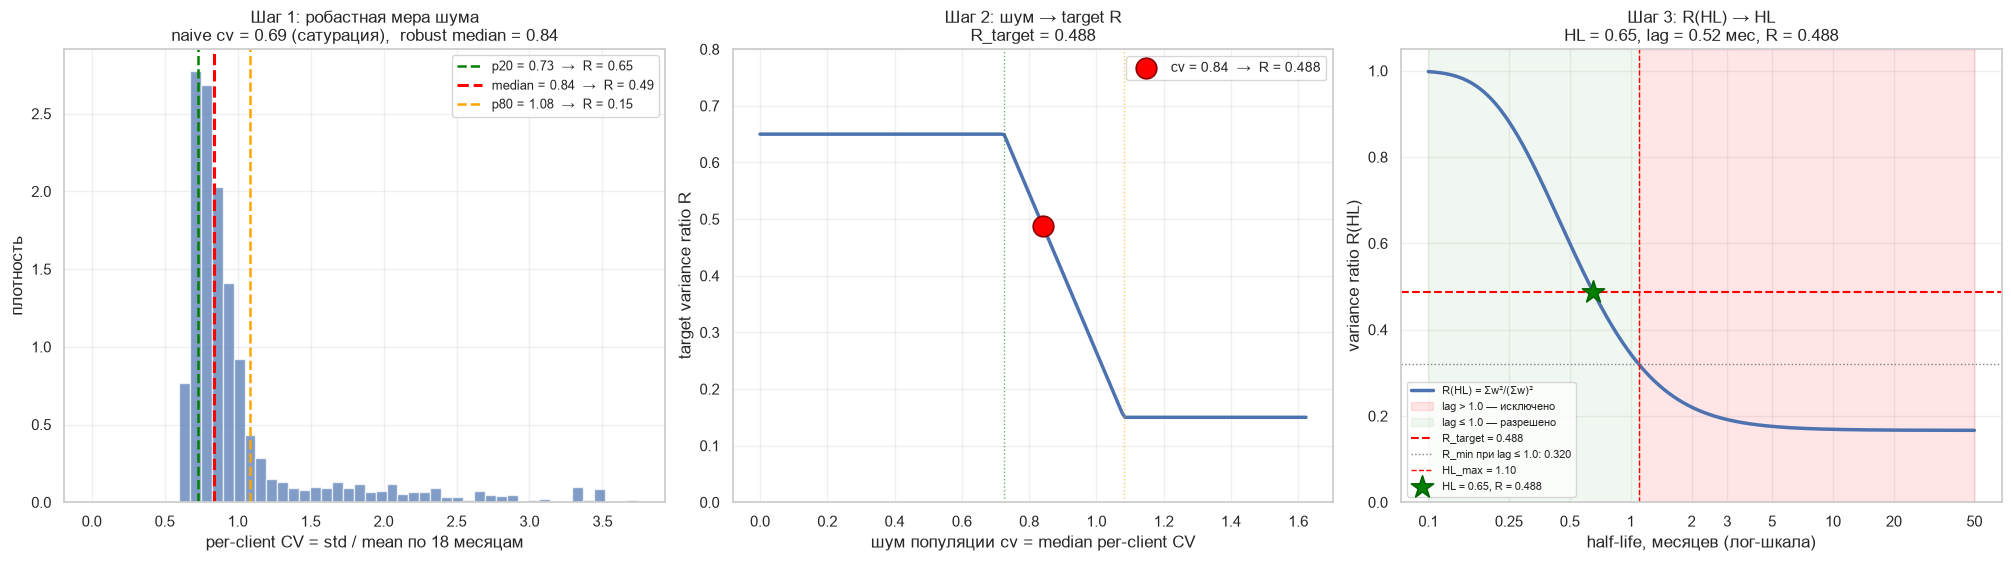


=== Итог ===
naive cv (saturated):   0.6893
robust cv (median):     0.8407
R_target из шума:       0.4883
Достижимый R:           [0.320, 0.998]
HALF_LIFE_MONTHS =      0.6518
  R(HL) = 0.4883
  lag   = 0.517 мес


In [297]:
# ============================================================
# §6.1 — выбор HL: noise → R_target → HL (робастная мера шума)
# ============================================================
# Единственный выход — HALF_LIFE_MONTHS.
# Самодостаточен: определяет ref_months, client_ids, txn_month,
# plot_months здесь, не полагается на §6.2 (он исполняется позже).

# --- базовые объекты (нужны здесь, т.к. §6.2 идёт ниже) ---
txn_f = txn_f.copy()
txn_f['txn_month'] = txn_f['txn_datetime'].dt.to_period('M').dt.to_timestamp()
ref_months = pd.date_range('2024-01-01', '2025-12-01', freq='MS')
plot_months = [m for m in ref_months if m <= pd.Timestamp('2025-06-01')]
client_ids = clients['client_id'].values

WINDOW = 6
MAX_LAG = 1.0

# --- raw per client-month ---
raw_wide = (txn_f.groupby(['client_id', 'txn_month']).size().unstack(fill_value=0)
            .reindex(index=client_ids, columns=ref_months, fill_value=0).astype(float))

# --- диагностика: почему наивная мера сатурируется ---
raw_mean_naive = float(raw_wide.values.mean())
diffs_all = np.abs(np.diff(raw_wide.values, axis=1)).flatten()
diffs_std_naive = float(diffs_all.std())
noise_cv_naive = diffs_std_naive / raw_mean_naive if raw_mean_naive > 0 else 1.0

print('=== Почему наивная мера даёт 1.0 ===')
print(f'mean(raw) по клиент-месяцам:  {raw_mean_naive:.4f} ops')
print(f'std(MoM diff):                {diffs_std_naive:.4f} ops')
print(f'naive cv = std/mean:           {noise_cv_naive:.4f}  '
      f'({"сатурация" if noise_cv_naive >= 1.0 else "в норме"})')

# --- робастная мера: per-client CV, медиана по популяции ---
per_client_cv = []
for i in range(len(client_ids)):
    s = raw_wide.values[i]
    m = s.mean()
    if m > 0:
        per_client_cv.append(float(s.std(ddof=0) / m))
per_client_cv = np.array(per_client_cv)

NOISE_LOW = float(np.percentile(per_client_cv, 20))
NOISE_HIGH = float(np.percentile(per_client_cv, 80))
noise_cv = float(np.median(per_client_cv))

print()
print(f'=== Робастная мера (median per-client CV) ===')
print(f'per-client cv distribution (n={len(per_client_cv)} active):')
print(f'  p20 = {NOISE_LOW:.3f}')
print(f'  median = {noise_cv:.3f}')
print(f'  p80 = {NOISE_HIGH:.3f}')

# --- cv_population → R_target ---
R_HIGH, R_LOW = 0.65, 0.15
frac = float(np.clip((noise_cv - NOISE_LOW) / max(NOISE_HIGH - NOISE_LOW, 1e-9), 0, 1))
R_target = R_HIGH - frac * (R_HIGH - R_LOW)

# --- R(HL), lag(HL) на сетке [0.1, 50] ---
HL_grid = np.logspace(np.log10(0.1), np.log10(50), 2000)
R_grid = np.zeros(len(HL_grid))
lag_grid = np.zeros(len(HL_grid))
for i, hl in enumerate(HL_grid):
    w = 0.5 ** (np.arange(WINDOW) / hl)
    R_grid[i] = (w ** 2).sum() / (w.sum() ** 2)
    lag_grid[i] = (np.arange(WINDOW) * w).sum() / w.sum()

allowed = lag_grid <= MAX_LAG
HL_max_allowed = float(HL_grid[allowed].max())
R_min_achievable = float(R_grid[allowed].min())
R_max_achievable = float(R_grid[allowed].max())

allowed_idx = np.where(allowed)[0]
best_local = int(allowed_idx[np.argmin(np.abs(R_grid[allowed_idx] - R_target))])
HALF_LIFE_MONTHS = float(HL_grid[best_local])
R_chosen = float(R_grid[best_local])
lag_chosen = float(lag_grid[best_local])
saturated = bool(R_target < R_min_achievable - 1e-6)

# --- Figure: 1x3 ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), layout='constrained')

# (1) распределение per-client CV
ax = axes[0]
cv_cap = float(np.percentile(per_client_cv, 99))
ax.hist(per_client_cv, bins=50, range=(0, cv_cap),
        color='C0', alpha=0.7, density=True)
ax.axvline(NOISE_LOW, color='green', linestyle='--', lw=1.8,
           label=f'p20 = {NOISE_LOW:.2f}  →  R = 0.65')
ax.axvline(noise_cv, color='red', linestyle='--', lw=2.2,
           label=f'median = {noise_cv:.2f}  →  R = {R_target:.2f}')
ax.axvline(NOISE_HIGH, color='orange', linestyle='--', lw=1.8,
           label=f'p80 = {NOISE_HIGH:.2f}  →  R = 0.15')
ax.set_xlabel('per-client CV = std / mean по 18 месяцам')
ax.set_ylabel('плотность')
ax.set_title(f'Шаг 1: робастная мера шума\n'
             f'naive cv = {noise_cv_naive:.2f} (сатурация),  '
             f'robust median = {noise_cv:.2f}')
ax.legend(fontsize=9, loc='upper right')
ax.grid(alpha=0.3)

# (2) cv → R_target
ax = axes[1]
cv_axis = np.linspace(0, NOISE_HIGH * 1.5, 200)
frac_axis = np.clip((cv_axis - NOISE_LOW) / max(NOISE_HIGH - NOISE_LOW, 1e-9), 0, 1)
R_axis = R_HIGH - frac_axis * (R_HIGH - R_LOW)
ax.plot(cv_axis, R_axis, '-', color='C0', lw=2.5)
ax.axvline(NOISE_LOW, color='green', linestyle=':', lw=1, alpha=0.6)
ax.axvline(NOISE_HIGH, color='orange', linestyle=':', lw=1, alpha=0.6)
ax.scatter([noise_cv], [R_target], s=220, color='red', zorder=5,
           edgecolor='darkred', lw=1.2,
           label=f'cv = {noise_cv:.2f}  →  R = {R_target:.3f}')
ax.set_xlabel('шум популяции cv = median per-client CV')
ax.set_ylabel('target variance ratio R')
ax.set_ylim(0, 0.8)
ax.set_title(f'Шаг 2: шум → target R\n'
             f'R_target = {R_target:.3f}')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# (3) R(HL) с ограничением лага
ax = axes[2]
ax.plot(HL_grid, R_grid, '-', color='C0', lw=2.5, label='R(HL) = Σw²/(Σw)²')
ax.fill_between(HL_grid, -0.02, 1.05, where=~allowed,
                color='red', alpha=0.10, label=f'lag > {MAX_LAG} — исключено')
ax.fill_between(HL_grid, -0.02, 1.05, where=allowed,
                color='green', alpha=0.06, label=f'lag ≤ {MAX_LAG} — разрешено')
ax.axhline(R_target, color='red', linestyle='--', lw=1.5,
           label=f'R_target = {R_target:.3f}')
ax.axhline(R_min_achievable, color='gray', linestyle=':', lw=1,
           label=f'R_min при lag ≤ {MAX_LAG}: {R_min_achievable:.3f}')
ax.axvline(HL_max_allowed, color='red', linestyle='--', lw=1,
           label=f'HL_max = {HL_max_allowed:.2f}')
ax.scatter([HALF_LIFE_MONTHS], [R_chosen], s=280, color='green',
           marker='*', edgecolor='darkgreen', lw=1.2, zorder=6,
           label=f'HL = {HALF_LIFE_MONTHS:.2f}, R = {R_chosen:.3f}')

ax.set_xscale('log')
ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 3, 5, 10, 20, 50])
ax.set_xticklabels(['0.1', '0.25', '0.5', '1', '2', '3', '5', '10', '20', '50'])
ax.minorticks_off()
ax.set_xlabel('half-life, месяцев (лог-шкала)')
ax.set_ylabel('variance ratio R(HL)')
ax.set_ylim(0, 1.05)
ax.set_title(f'Шаг 3: R(HL) → HL\n'
             f'HL = {HALF_LIFE_MONTHS:.2f}, lag = {lag_chosen:.2f} мес, '
             f'R = {R_chosen:.3f}')
ax.legend(fontsize=8, loc='lower left')
ax.grid(alpha=0.3)

plt.show()

print()
print(f'=== Итог ===')
print(f'naive cv (saturated):   {min(noise_cv_naive, 1.0):.4f}')
print(f'robust cv (median):     {noise_cv:.4f}')
print(f'R_target из шума:       {R_target:.4f}')
print(f'Достижимый R:           [{R_min_achievable:.3f}, {R_max_achievable:.3f}]')
if saturated:
    print(f'  ⚠ R_target < R_min: HL зажат на границе лага')
print(f'HALF_LIFE_MONTHS =      {HALF_LIFE_MONTHS:.4f}')
print(f'  R(HL) = {R_chosen:.4f}')
print(f'  lag   = {lag_chosen:.3f} мес')

### 6.2 Рассчёт метрики и дополнительных показателей

In [298]:
# ============================================================
# §6.2 — расчёт метрики ops_c(τ) с выбранным HL
# ============================================================
# Применяем HALF_LIFE_MONTHS из §6.1.
# WINDOW = 6 — согласовано с формулой §6 (Σ_{k=0..5}, 6 весов).
# Окно отсчитывается от card_open_date: до открытия карты
# операций быть не может.

assert 'HALF_LIFE_MONTHS' in globals(), \
    'HALF_LIFE_MONTHS не определён — выполни §6.1 сначала'

HALF_LIFE = HALF_LIFE_MONTHS
WINDOW = 6
DATA_START = pd.Timestamp('2024-01-01')

txn_f = txn_f.copy()
txn_f['txn_month'] = txn_f['txn_datetime'].dt.to_period('M').dt.to_timestamp()

ref_months = pd.date_range('2024-01-01', '2025-12-01', freq='MS')
plot_months = [m for m in ref_months if m <= pd.Timestamp('2025-06-01')]
client_ids = clients['client_id'].values
weight_sum = sum(0.5 ** (k / HALF_LIFE) for k in range(WINDOW))

months_idx = txn_f['txn_month'].dt.year.values * 12 + txn_f['txn_month'].dt.month.values - 1
cid_arr = txn_f['client_id'].values

# сырая сумма затухающих весов
raw = pd.DataFrame(0.0, index=client_ids, columns=ref_months)
for ref in ref_months:
    ref_idx = ref.year * 12 + ref.month - 1
    mask = (months_idx <= ref_idx) & (months_idx > ref_idx - WINDOW)
    if not mask.any():
        continue
    w = 0.5 ** ((ref_idx - months_idx[mask]) / HALF_LIFE)
    agg = pd.Series(w).groupby(cid_arr[mask]).sum()
    raw.loc[agg.index, ref] = agg.values

# approximation для усечённых окон (card_open_date > DATA_START)
reg = clients.set_index('client_id')['card_open_date'].reindex(client_ids)
client_start = (reg.fillna(DATA_START).dt.to_period('M').dt.to_timestamp()
                .clip(lower=DATA_START))
factor = pd.DataFrame(1.0, index=client_ids, columns=ref_months)
for ref in ref_months:
    obs_w = pd.Series(0.0, index=client_ids)
    for k in range(WINDOW):
        m = ref - pd.DateOffset(months=k)
        obs_w = obs_w + (client_start <= m).astype(float) * (0.5 ** (k / HALF_LIFE))
    factor[ref] = weight_sum / obs_w.replace(0, np.nan)

# метрика: нормированная на weight_sum, ops/мес
ops = (raw * factor / weight_sum).fillna(0.0)

# факт: обычное число операций за календарный месяц, ops/мес
ops_raw = (txn_f.groupby(['client_id', 'txn_month']).size()
           .unstack(fill_value=0)
           .reindex(index=client_ids, columns=ref_months, fill_value=0)
           .astype(float))

# окна для сравнения
base_cols = [m for m in ref_months if pd.Timestamp('2024-07-01') <= m <= BASE_END]
eval_cols = [m for m in ref_months if EVAL_START <= m <= EVAL_END]
assert len(base_cols) == len(eval_cols) == 6

feat = clients.set_index('client_id').copy()
feat['ops_base'] = ops[base_cols].mean(axis=1)
feat['ops_eval'] = ops[eval_cols].mean(axis=1)
feat['ops_raw_base'] = ops_raw[base_cols].mean(axis=1)
feat['ops_raw_eval'] = ops_raw[eval_cols].mean(axis=1)
feat['age'] = (pd.Timestamp('2025-06-30') - feat['birth_date']).dt.days / 365.25


def build_driver(df, key):
    b = df[(df['txn_datetime'] >= pd.Timestamp('2024-07-01')) &
           (df['txn_datetime'] <= BASE_END)]
    e = df[(df['txn_datetime'] >= EVAL_START) &
           (df['txn_datetime'] <= EVAL_END)]
    bp = (b.pivot_table(index='client_id', columns=key, values='amount',
                        aggfunc='sum', fill_value=0) / len(base_cols))
    ep = (e.pivot_table(index='client_id', columns=key, values='amount',
                        aggfunc='sum', fill_value=0) / len(eval_cols))
    cols = bp.columns.union(ep.columns)
    d = (ep.reindex(columns=cols, fill_value=0)
           .sub(bp.reindex(columns=cols, fill_value=0), fill_value=0))
    return d.idxmin(axis=1).rename('driver_' + key)


feat = feat.join(build_driver(txn_f, 'channel'))
feat = feat.join(build_driver(txn_f, 'category'))

print(f'HALF_LIFE = {HALF_LIFE:.2f} (из §6.1), WINDOW = {WINDOW}')
print(f'weight_sum = {weight_sum:.4f}')
print(f'клиентов: {len(feat)}, ops_base > 0: {int((feat["ops_base"] > 0).sum())}')
print()
print(f'ops_base       mean {feat["ops_base"].mean():6.2f}  '
      f'median {feat["ops_base"].median():6.2f}  ops/мес')
print(f'ops_raw_base   mean {feat["ops_raw_base"].mean():6.2f}  '
      f'median {feat["ops_raw_base"].median():6.2f}  ops/мес')
print(f'ops_eval       mean {feat["ops_eval"].mean():6.2f}  '
      f'median {feat["ops_eval"].median():6.2f}  ops/мес')
print(f'ops_raw_eval   mean {feat["ops_raw_eval"].mean():6.2f}  '
      f'median {feat["ops_raw_eval"].median():6.2f}  ops/мес')

HALF_LIFE = 0.65 (из §6.1), WINDOW = 6
weight_sum = 1.5248
клиентов: 5658, ops_base > 0: 5263

ops_base       mean   5.71  median   5.06  ops/мес
ops_raw_base   mean   5.81  median   5.17  ops/мес
ops_eval       mean   4.60  median   3.58  ops/мес
ops_raw_eval   mean   4.45  median   3.33  ops/мес


### 6.3 Анализ качества метрики 

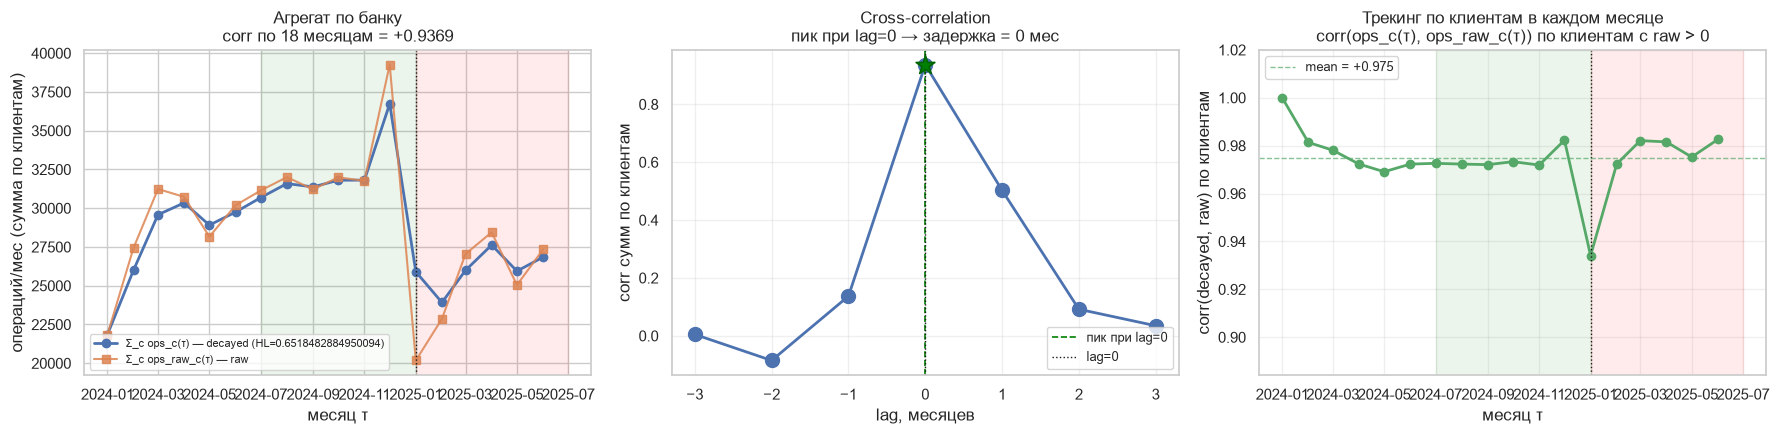

Tracking — сводка:
  corr сумм по месяцам:       +0.9369
  lag с максимальной corr:    0 мес
  corr при lag=0:    +0.9369
  corr при lag=0:             +0.9369
  corr по клиентам (среднее): +0.9748
  corr по клиентам (min):     +0.9341


In [299]:
# ============================================================
# §6.3 — Tracking: decayed живёт в той же реальности, что raw
# ============================================================

CURRENT_HL = HALF_LIFE_MONTHS

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# ---- (1) агрегат по банку ----
ax = axes[0]
ax.plot(plot_months, ops[plot_months].sum(axis=0).values, marker='o',
        color='C0', lw=2, label=f'Σ_c ops_c(τ) — decayed (HL={CURRENT_HL})')
ax.plot(plot_months, ops_raw[plot_months].sum(axis=0).values, marker='s',
        color='C1', lw=1.5, alpha=0.85, label='Σ_c ops_raw_c(τ) — raw')
ax.axvline(EVAL_START, color='k', linestyle=':', lw=1)
ax.axvspan(pd.Timestamp('2024-07-01'), BASE_END, alpha=0.08, color='green')
ax.axvspan(EVAL_START, EVAL_END, alpha=0.08, color='red')
corr_bank = float(np.corrcoef(ops[plot_months].sum(axis=0).values,
                              ops_raw[plot_months].sum(axis=0).values)[0, 1])
ax.set_xlabel('месяц τ'); ax.set_ylabel('операций/мес (сумма по клиентам)')
ax.set_title(f'Агрегат по банку\n'
             f'corr по {len(plot_months)} месяцам = {corr_bank:+.4f}')
ax.legend(fontsize=8, loc='lower left')

# ---- (2) cross-correlation с лагом ----
ax = axes[1]
agg_dec = ops[plot_months].sum(axis=0).values
agg_raw = ops_raw[plot_months].sum(axis=0).values
lags = np.arange(-3, 4)
corrs_lag = []
for lag in lags:
    if lag == 0:
        c = float(np.corrcoef(agg_dec, agg_raw)[0, 1])
    elif lag > 0:
        c = float(np.corrcoef(agg_dec[lag:], agg_raw[:-lag])[0, 1])
    else:
        c = float(np.corrcoef(agg_dec[:lag], agg_raw[-lag:])[0, 1])
    corrs_lag.append(c)
corrs_lag = np.array(corrs_lag)
peak_lag = int(lags[int(np.argmax(corrs_lag))])
ax.plot(lags, corrs_lag, 'o-', color='C0', lw=2, markersize=10)
ax.axvline(peak_lag, color='green', linestyle='--', lw=1.2,
           label=f'пик при lag={peak_lag}')
ax.axvline(0, color='k', linestyle=':', lw=1, label='lag=0')
ax.scatter([peak_lag], [corrs_lag.max()], s=200, color='green',
           marker='*', edgecolor='darkgreen', lw=1.2, zorder=6)
ax.set_xlabel('lag, месяцев'); ax.set_ylabel('corr сумм по клиентам')
ax.set_xticks(lags)
ax.set_title(f'Cross-correlation\n'
             f'пик при lag={peak_lag} → задержка = {peak_lag} мес')
ax.legend(fontsize=9, loc='lower right'); ax.grid(alpha=0.3)

# ---- (3) корреляция по клиентам в каждом месяце ----
# Для каждого τ: corr(ops_raw_c(τ), ops_c(τ)) по клиентам c
# с raw_c(τ) > 0. Обе величины — ops/мес, непрерывные по клиентам.
ax = axes[2]
corr_per_month = []
months_with_data = []
for m in plot_months:
    x = ops_raw[m].values
    y = ops[m].values
    mask = x > 0
    if mask.sum() >= 10:
        corr_per_month.append(float(np.corrcoef(x[mask], y[mask])[0, 1]))
        months_with_data.append(m)
ax.plot(months_with_data, corr_per_month, 'o-', color='C2', lw=2)
ax.axvline(EVAL_START, color='k', linestyle=':', lw=1)
ax.axvspan(pd.Timestamp('2024-07-01'), BASE_END, alpha=0.08, color='green')
ax.axvspan(EVAL_START, EVAL_END, alpha=0.08, color='red')
ax.axhline(np.mean(corr_per_month), color='C2', linestyle='--',
           lw=1, alpha=0.7, label=f'mean = {np.mean(corr_per_month):+.3f}')
ax.set_xlabel('месяц τ')
ax.set_ylabel('corr(decayed, raw) по клиентам')
ax.set_ylim(min(corr_per_month) - 0.05, 1.02)
ax.set_title(f'Трекинг по клиентам в каждом месяце\n'
             f'corr(ops_c(τ), ops_raw_c(τ)) по клиентам с raw > 0')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print('Tracking — сводка:')
print(f'  corr сумм по месяцам:       {corr_bank:+.4f}')
print(f'  lag с максимальной corr:    {peak_lag} мес')
print(f'  corr при lag={peak_lag}:    {corrs_lag.max():+.4f}')
print(f'  corr при lag=0:             {corrs_lag[list(lags).index(0)]:+.4f}')
print(f'  corr по клиентам (среднее): {np.mean(corr_per_month):+.4f}')
print(f'  corr по клиентам (min):     {np.min(corr_per_month):+.4f}')

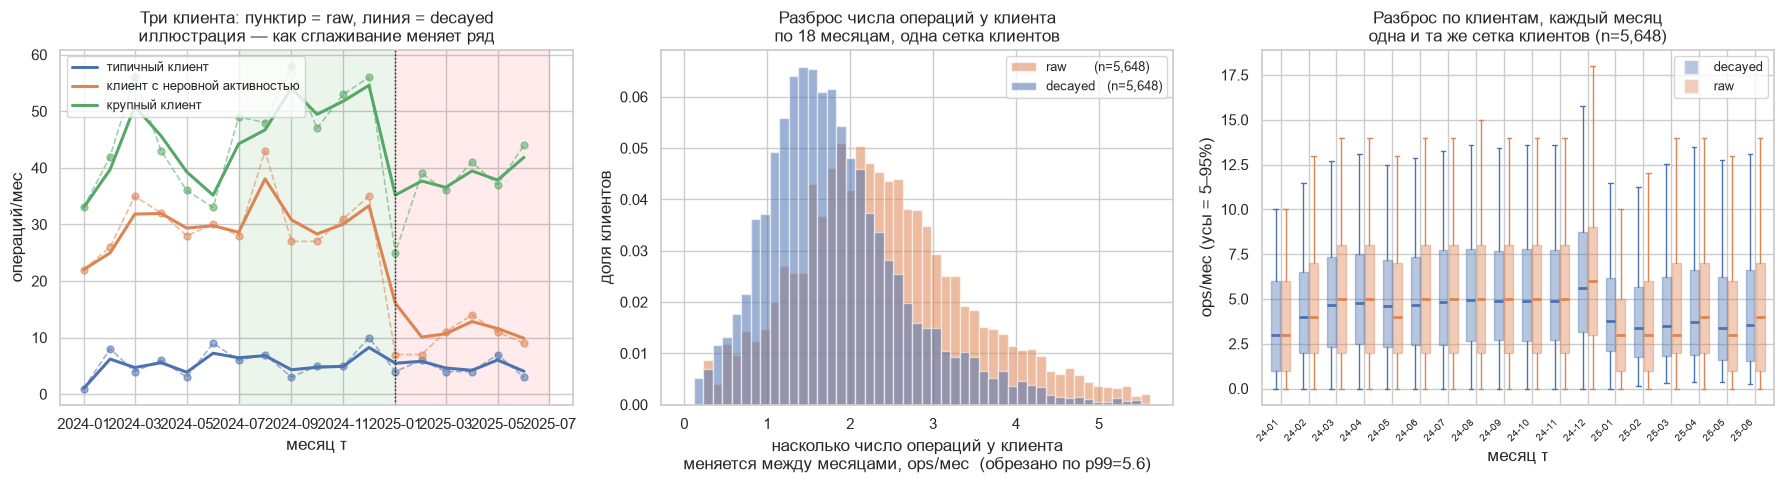

In [300]:
months_used = plot_months
level_raw  = ops_raw[months_used].mean(axis=1)
active     = level_raw[level_raw > 0].index
n_active   = len(active)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ax = axes[0]
examples = []
if n_active >= 3:
    s = ops_raw.loc[active, months_used].std(axis=1).sort_values()
    examples = [
        ('типичный клиент',               s.index[n_active // 2]),
        ('клиент с неровной активностью', s.index[-1]),
        ('крупный клиент',                level_raw.loc[active].idxmax()),
    ]
for (label, cid), color in zip(examples, ['C0', 'C1', 'C2']):
    ax.plot(plot_months, ops_raw.loc[cid, plot_months].values,
            'o--', color=color, alpha=0.55, markersize=5, lw=1.2)
    ax.plot(plot_months, ops.loc[cid, plot_months].values,
            '-', color=color, lw=2.2, label=label)
ax.axvline(EVAL_START, color='k', linestyle=':', lw=1)
ax.axvspan(pd.Timestamp('2024-07-01'), BASE_END, alpha=0.08, color='green')
ax.axvspan(EVAL_START, EVAL_END, alpha=0.08, color='red')
ax.set_xlabel('месяц τ'); ax.set_ylabel('операций/мес')
ax.set_title('Три клиента: пунктир = raw, линия = decayed\n'
             'иллюстрация — как сглаживание меняет ряд')
ax.legend(fontsize=9, loc='upper left')

ax = axes[1]
spread_raw = ops_raw.loc[active, months_used].std(axis=1).values
spread_dec = ops.loc[active, months_used].std(axis=1).values
clip_hi = float(np.percentile(np.concatenate([spread_raw, spread_dec]), 99))
bins = np.linspace(0, clip_hi, 50)
ax.hist(spread_raw, bins=bins, range=(0, clip_hi),
        weights=np.ones(n_active) / n_active,
        alpha=0.55, color='C1', label=f'raw       (n={n_active:,})')
ax.hist(spread_dec, bins=bins, range=(0, clip_hi),
        weights=np.ones(n_active) / n_active,
        alpha=0.55, color='C0', label=f'decayed   (n={n_active:,})')
ax.set_xlabel('насколько число операций у клиента\n'
              f'меняется между месяцами, ops/мес  (обрезано по p99={clip_hi:.1f})')
ax.set_ylabel('доля клиентов')
ax.set_title(f'Разброс числа операций у клиента\n'
             f'по {len(months_used)} месяцам, одна сетка клиентов')
ax.legend(fontsize=9)

ax = axes[2]
data_dec = [ops.loc[active, m].values for m in months_used]
data_raw = [ops_raw.loc[active, m].values for m in months_used]
pos_arr = np.arange(len(months_used))
ax.boxplot(data_dec, positions=pos_arr - 0.18, widths=0.32,
           patch_artist=True, showfliers=False, whis=(5, 95),
           medianprops=dict(color='C0', lw=2),
           boxprops=dict(facecolor='C0', alpha=0.4, edgecolor='C0'),
           whiskerprops=dict(color='C0'), capprops=dict(color='C0'))
ax.boxplot(data_raw, positions=pos_arr + 0.18, widths=0.32,
           patch_artist=True, showfliers=False, whis=(5, 95),
           medianprops=dict(color='C1', lw=2),
           boxprops=dict(facecolor='C1', alpha=0.4, edgecolor='C1'),
           whiskerprops=dict(color='C1'), capprops=dict(color='C1'))
ax.set_xticks(pos_arr)
ax.set_xticklabels([m.strftime('%y-%m') for m in months_used],
                   rotation=45, ha='right', fontsize=7)
ax.set_xlabel('месяц τ'); ax.set_ylabel('ops/мес (усы = 5–95%)')
ax.set_title(f'Разброс по клиентам, каждый месяц\n'
             f'одна и та же сетка клиентов (n={n_active:,})')
ax.legend(handles=[
    plt.Line2D([], [], marker='s', color='w', markerfacecolor='C0',
               alpha=0.4, markersize=10, label='decayed'),
    plt.Line2D([], [], marker='s', color='w', markerfacecolor='C1',
               alpha=0.4, markersize=10, label='raw')], fontsize=9)

plt.tight_layout()
plt.show()

## 7. Поиск и описание групп

Правило каждой группы = «кто это» (признак клиента) + «что произошло»
(какой канал/категория дал основной вклад в падение). Порог по величине
падения входит только как уточнение.

Конфликт «клиент подходит под несколько правил» разрешается порядком
правил: клиент закрепляется за первым подходящим. Отсекаются клиенты
без согласия на маркетинг и с базовой активностью < 1 операции/мес —
для них доля падения шумная.

Для понимания кто на сколько снизился в активности добавляется признак 
delta = медиана(последние 3 мес) − медиана(3 из 4 лучших без max).

max удаляется для того чтобы убрать пик который предположительно происходит перед тем как клиент прекращает активно пользоваться картой(тратит то что на ней есть).

In [301]:
# ============================================================
# §7.0 — единая delta для всего §7
# ============================================================
# Считается один раз, используется везде: §7.1 (графики),
# §7.3 (подбор групп), §7.4 (воронка).
#
# delta = медиана(последние 3 мес) − медиана(3 из 4 лучших без max).
# Единица: ops/мес. Устойчива к разовому пику (пик отброшен).
# Окна отсчитываются от card_open_date, не registration_date:
# клиент без карты в первых месяцах не занижает базу.

DATA_START = pd.Timestamp('2024-01-01')

_befores, _afters, _obs = {}, {}, {}
for cid in feat.index:
    card_start = feat.loc[cid, 'card_open_date']
    if pd.isna(card_start):
        continue
    start = max(pd.Timestamp(card_start).to_period('M').to_timestamp(),
                DATA_START)
    observed = [m for m in plot_months if m >= start]
    _obs[cid] = len(observed)
    if len(observed) < 7:
        continue
    v = ops.loc[cid, observed]
    _befores[cid] = float(v.nlargest(4).iloc[1:].median())
    _afters[cid]  = float(v.iloc[-3:].median())

feat['before']    = feat.index.map(_befores)
feat['after']     = feat.index.map(_afters)
feat['delta']     = feat['after'] - feat['before']
feat['obs_months'] = feat.index.map(_obs).fillna(0).astype(int)

feat['activity_level'] = pd.qcut(feat['ops_base'].fillna(0), q=3,
                                 labels=['низкая', 'средняя', 'высокая'])
feat['age_bucket'] = pd.cut(feat['age'],
                            bins=[0, 25, 35, 45, 55, 100],
                            labels=['<25', '25-35', '35-45', '45-55', '55+'])
_inc_ok = feat['monthly_income'].notna()
feat.loc[_inc_ok, 'income_bucket'] = pd.qcut(
    feat.loc[_inc_ok, 'monthly_income'], q=4,
    labels=['низкий', 'ниже среднего', 'выше среднего', 'высокий'])
_city_top = feat['city'].value_counts().head(6).index
feat['city_top'] = feat['city'].where(feat['city'].isin(_city_top), 'other')

print(f'feat["delta"]: посчитана для {feat["delta"].notna().sum():,} '
      f'из {len(feat):,}')
print(f'  median: {feat["delta"].median():+.2f} ops/мес')
print(f'  доля упавших (delta<0): '
      f'{(feat["delta"]<0).mean()*100:.1f}%')

feat["delta"]: посчитана для 5,330 из 5,658
  median: -2.11 ops/мес
  доля упавших (delta<0): 82.7%


### 7.1 Предварительные кандидаты в группы по признакам клиента и его затухающей активности

who_candidates — клиентские срезы

Отбор — группы с наибольшим падением относительно минимального в своём срезе (drop = before − after, vs min = насколько drop больше минимального): высокая активность 10.8→7.4 (3.38, +1.71), Массовый 6.0→2.7 (3.30, +1.18), без приложения 6.4→3.0 (3.38, +0.84), Базовый 6.3→3.1 (3.10, +0.97), 45–55 6.9→3.9 (3.04, +0.76), низкий доход 6.5→3.4 (3.12, +0.62), «Не указан» источник 6.3→3.1 (3.19, +0.65), Серебро 6.7→3.7 (2.98, +0.85), 35–45 7.2→4.4 (2.86, +0.58), средняя активность 6.3→3.7 (2.59, +0.92), Кредитная 6.9→4.3 (2.59, минимум среза), 25–35 7.2→4.9 (2.28, минимум среза), Москва 6.8→4.0 (2.72, +0.02). Исключены по малому разбросу drop внутри среза: пол (+0.05), оценка сервиса (+0.24), города кроме Москвы (0.56 на базе ~7, ~8%).

клиентов с посчитанной delta: 5,330


=== По сегментам: top-10 по падению (drop = before − after) ===
val                             n   before    after     drop    vs min
----------------------------------------------------------------------
Массовый                     2811      6.0      2.7     3.30     +1.18
Премиальный                   835      8.0      5.5     2.48     +0.36
Private                       192      7.4      5.2     2.22     +0.09
Зарплатный                   1492      7.2      5.0     2.13       min



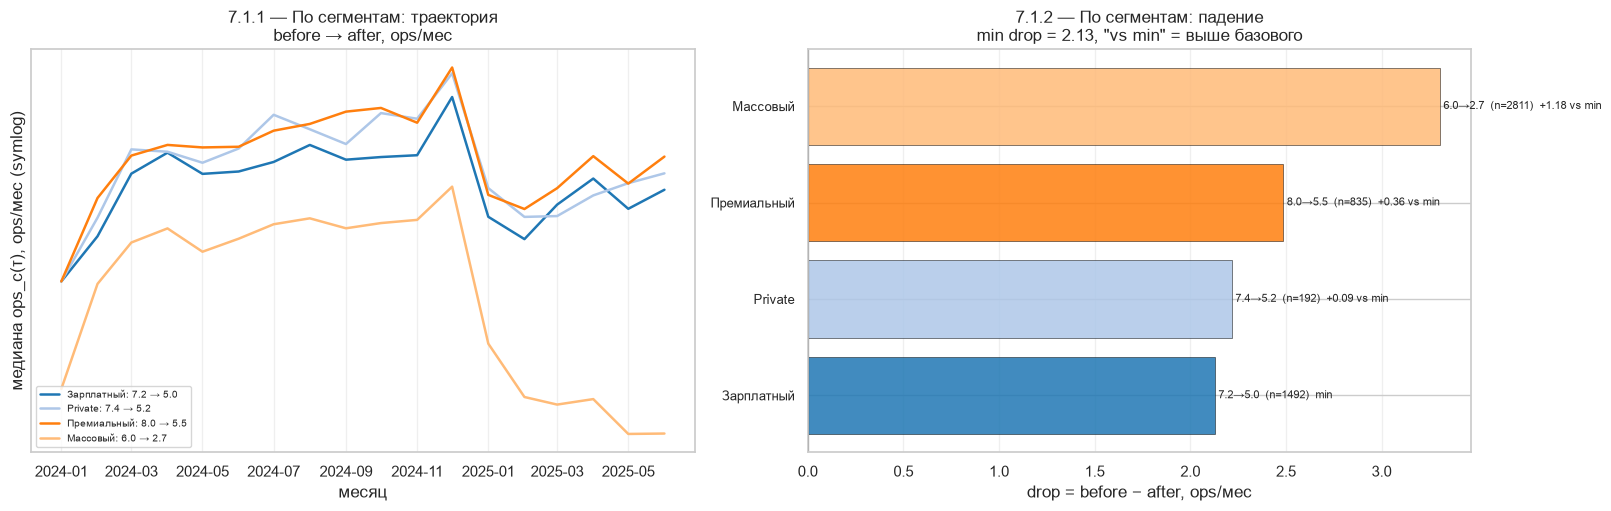


=== По уровню лояльности: top-10 по падению (drop = before − after) ===
val                             n   before    after     drop    vs min
----------------------------------------------------------------------
Базовый                      2731      6.3      3.1     3.10     +0.97
Серебро                      1449      6.7      3.7     2.98     +0.85
Платина                       299      7.9      5.7     2.19     +0.06
Золото                        851      7.4      5.3     2.13       min



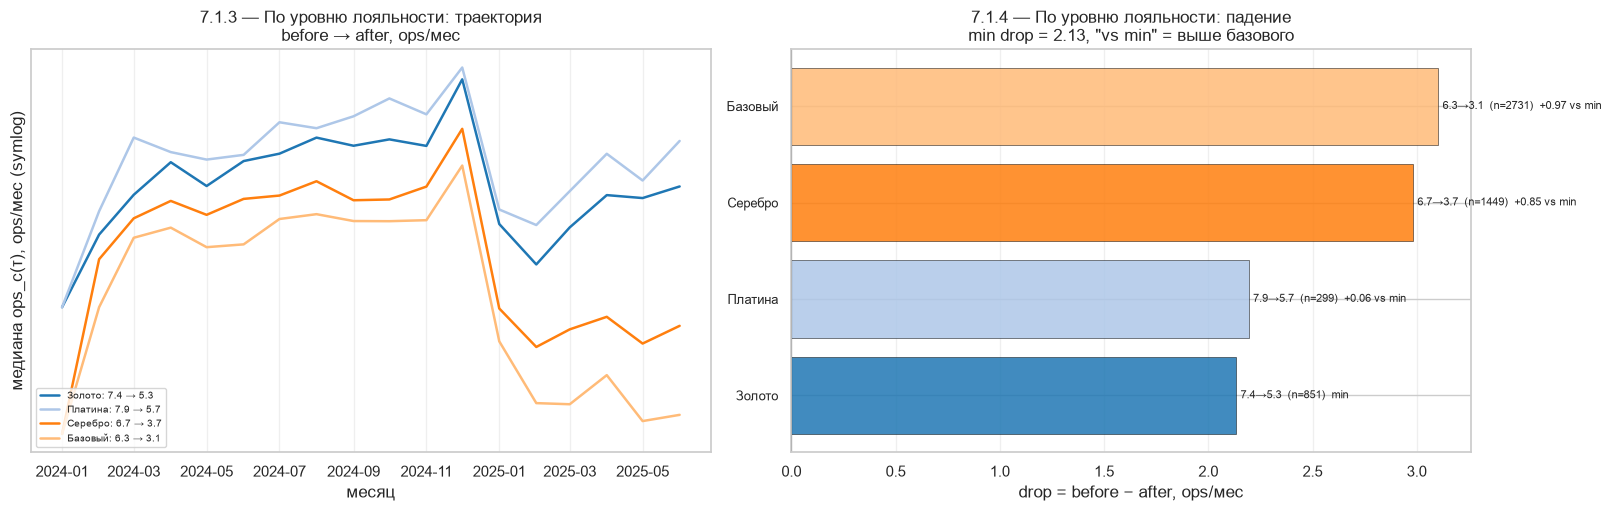


=== По типу карты: top-10 по падению (drop = before − after) ===
val                             n   before    after     drop    vs min
----------------------------------------------------------------------
Дебетовая                    3736      6.4      3.5     2.95     +0.35
Премиальная                   436      7.6      4.9     2.70     +0.10
Кредитная                    1158      6.9      4.3     2.59       min



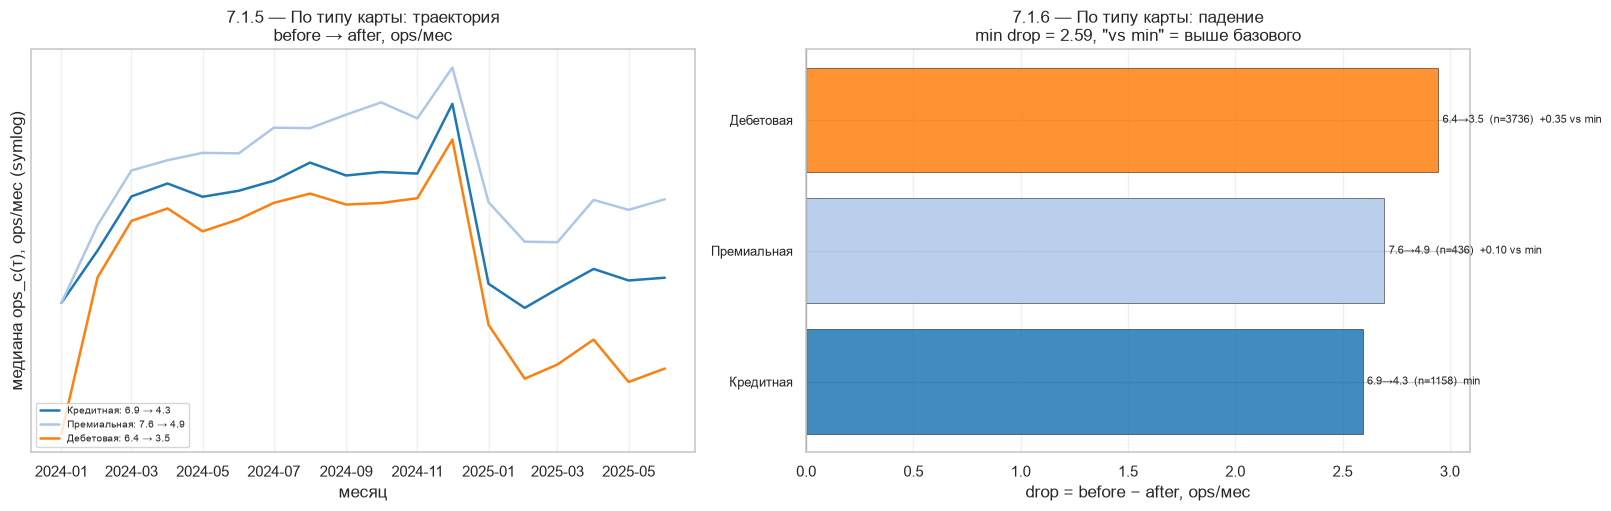


=== По наличию приложения: top-10 по падению (drop = before − after) ===
val                             n   before    after     drop    vs min
----------------------------------------------------------------------
Нет                          2048      6.4      3.0     3.38     +0.84
Да                           3282      6.7      4.2     2.54       min



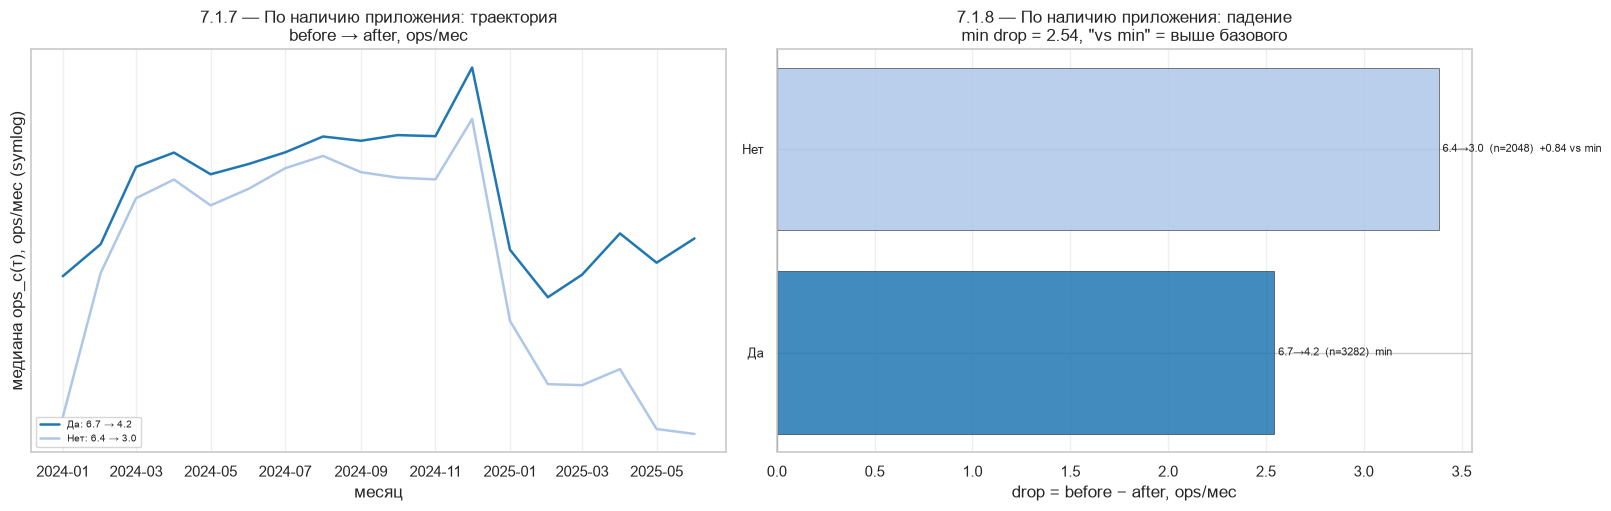


=== По источнику дохода: top-10 по падению (drop = before − after) ===
val                             n   before    after     drop    vs min
----------------------------------------------------------------------
Не указан                    1450      6.3      3.1     3.19     +0.65
Зарплата в другом банке      1441      6.5      3.3     3.14     +0.60
Зарплата в нашем банке       2439      6.9      4.4     2.54       min



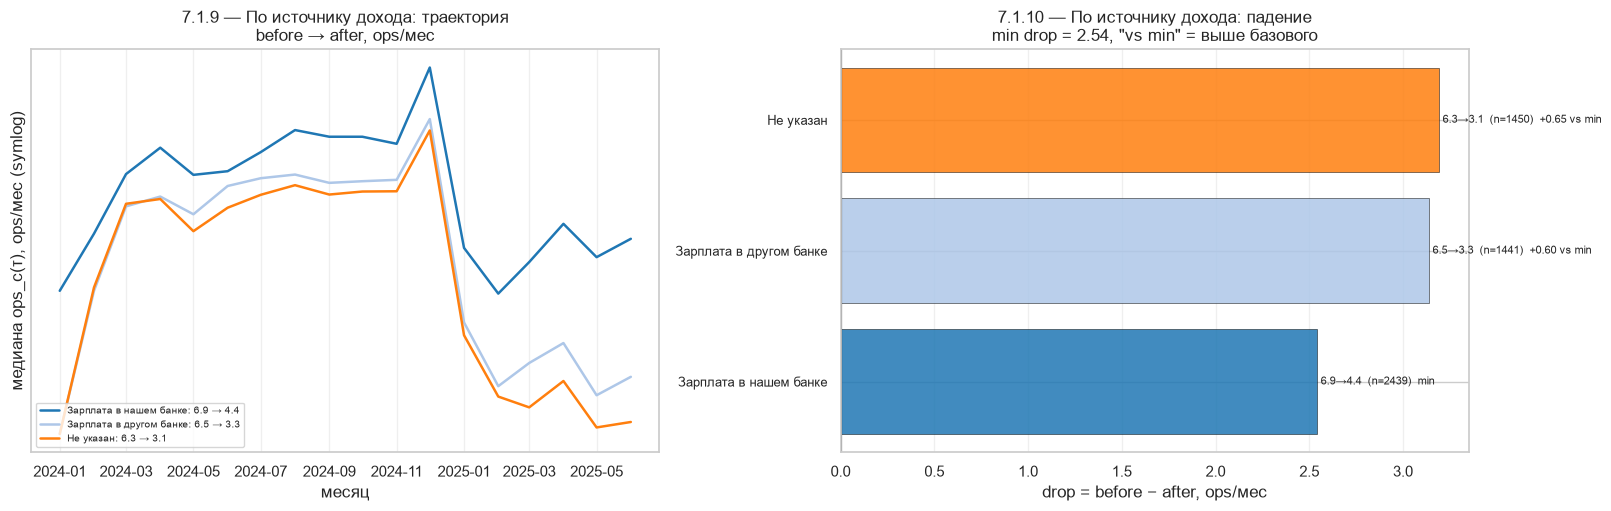


=== По полу: top-10 по падению (drop = before − after) ===
val                             n   before    after     drop    vs min
----------------------------------------------------------------------
Ж                            2679      6.7      3.8     2.88     +0.05
М                            2651      6.5      3.7     2.83       min



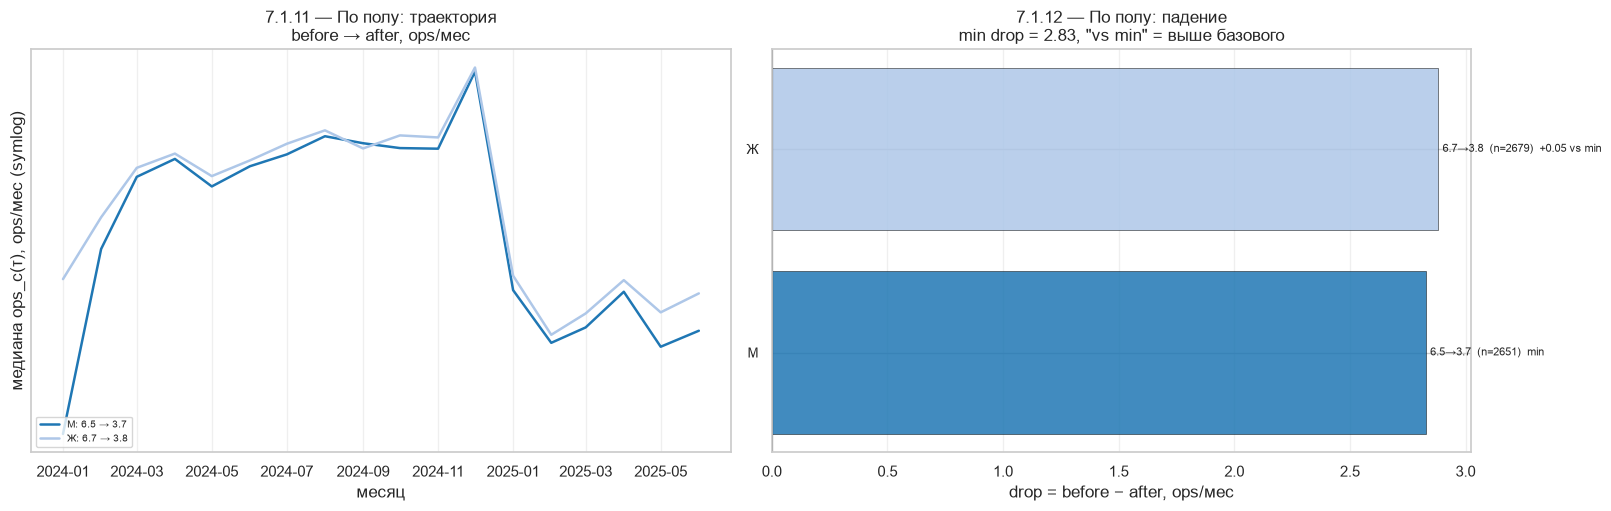


=== По возрасту: top-10 по падению (drop = before − after) ===
val                             n   before    after     drop    vs min
----------------------------------------------------------------------
45-55                         598      6.9      3.9     3.04     +0.76
35-45                         487      7.2      4.4     2.86     +0.58
55+                           887      6.0      3.3     2.71     +0.43
25-35                         124      7.2      4.9     2.28       min



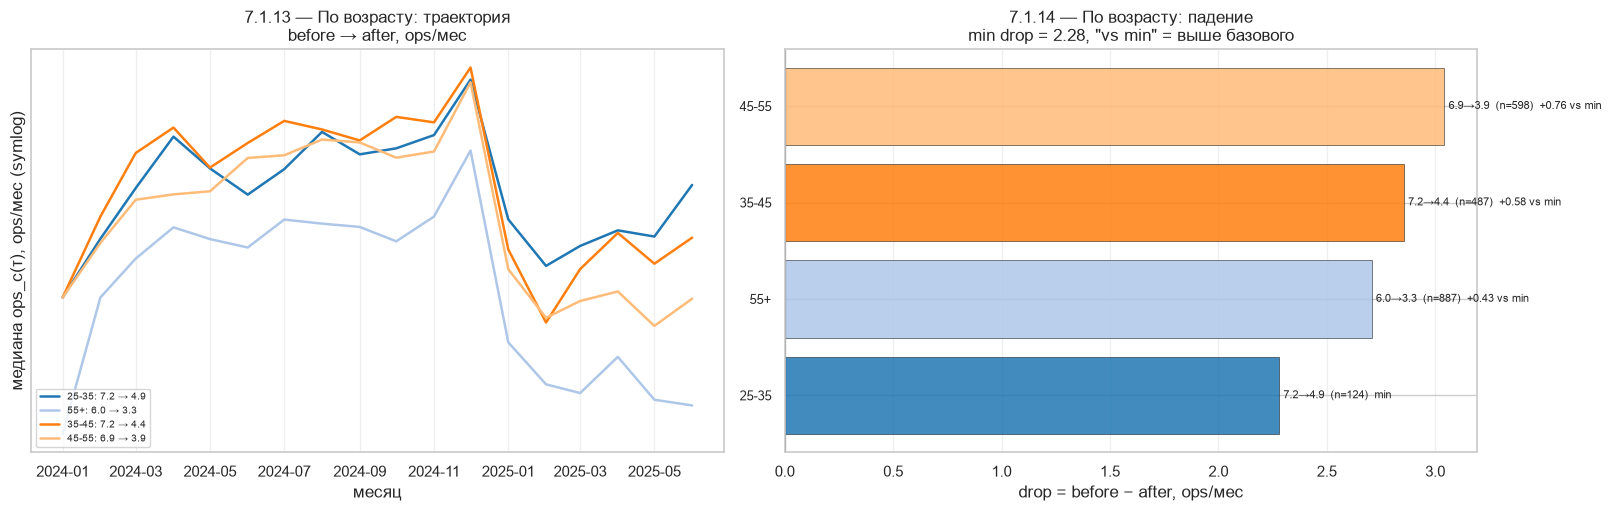


=== По доходу (квартили): top-10 по падению (drop = before − after) ===
val                             n   before    after     drop    vs min
----------------------------------------------------------------------
низкий                       1202      6.5      3.4     3.12     +0.62
ниже среднего                1204      6.4      3.4     3.03     +0.54
выше среднего                1198      6.6      4.0     2.61     +0.11
высокий                      1185      7.1      4.6     2.49       min



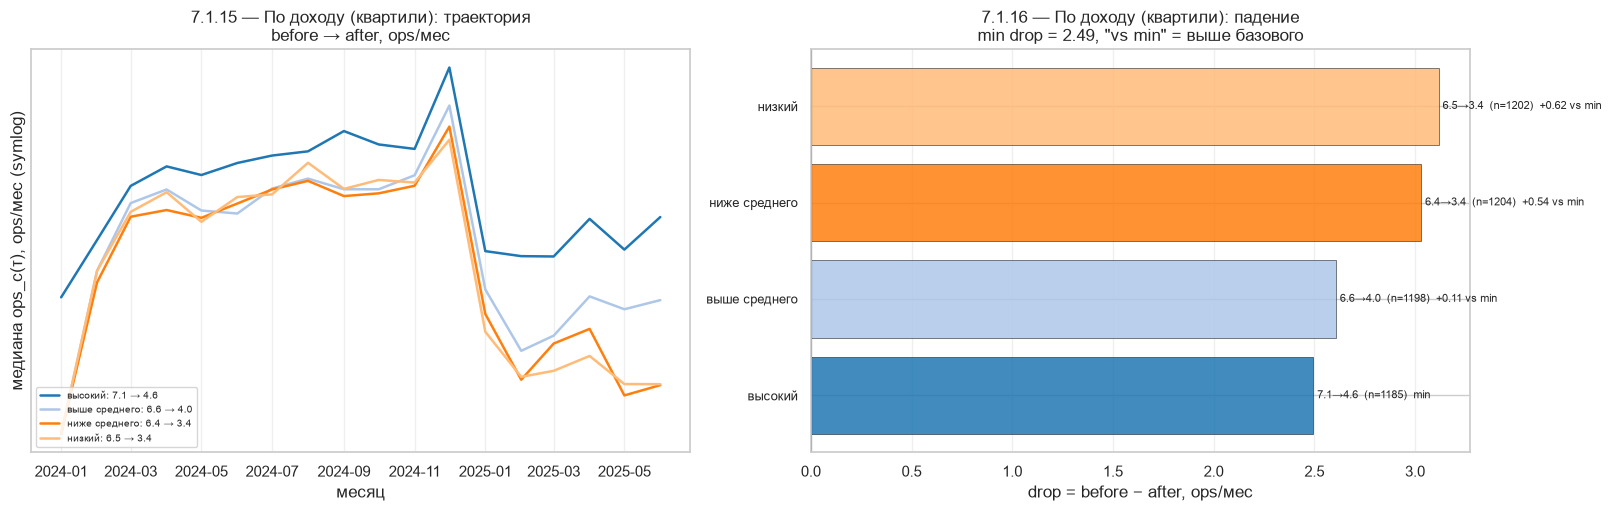


=== По уровню активности (ops_base): top-10 по падению (drop = before − after) ===
val                             n   before    after     drop    vs min
----------------------------------------------------------------------
высокая                      1886     10.8      7.4     3.38     +1.71
средняя                      1886      6.3      3.7     2.59     +0.92
низкая                       1558      3.5      1.8     1.67       min



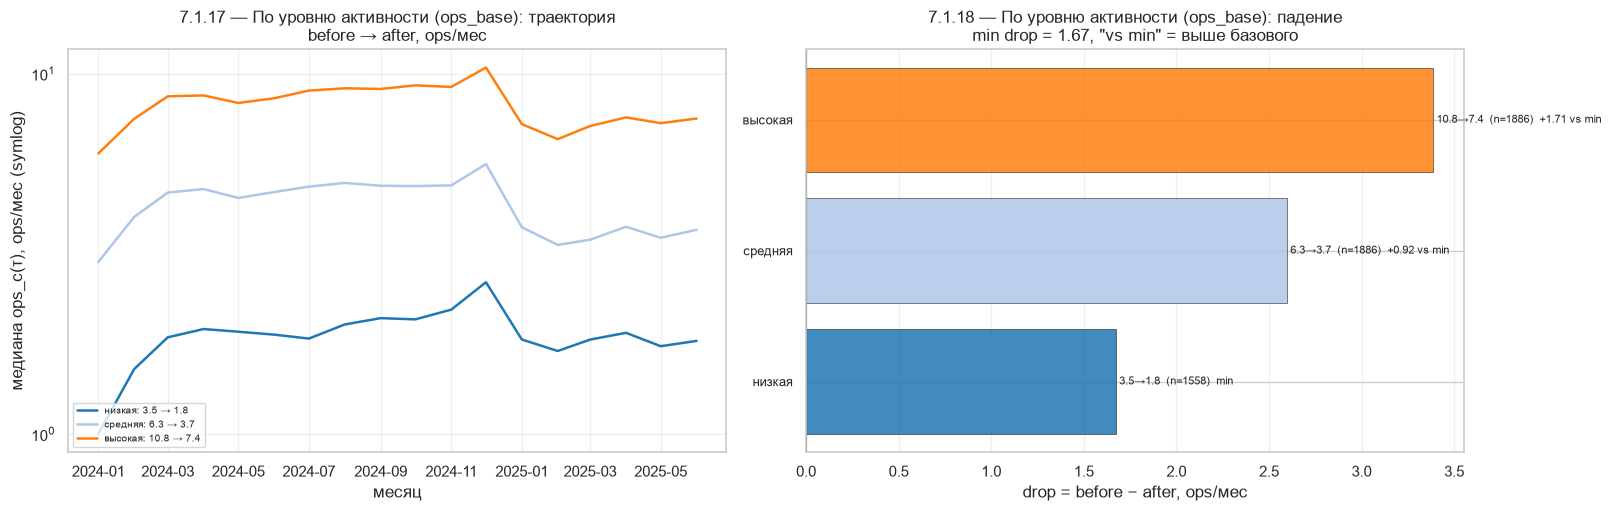


=== По оценке сервиса (1–5): top-10 по падению (drop = before − after) ===
val                             n   before    after     drop    vs min
----------------------------------------------------------------------
1.0                           278      6.1      3.3     2.77     +0.24
2.0                           439      6.9      4.3     2.62     +0.09
5.0                           599      7.2      4.6     2.61     +0.08
3.0                           442      6.7      4.1     2.58     +0.06
4.0                           398      6.6      4.0     2.53       min



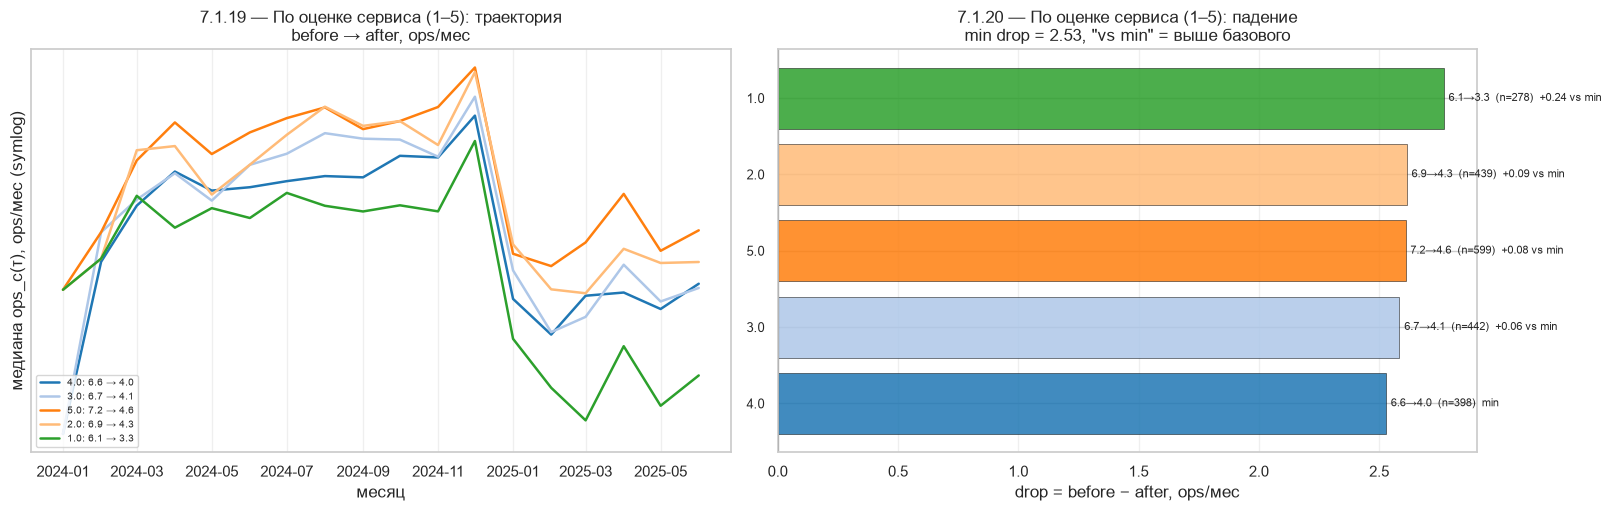


=== По городу (топ-6 + other): top-10 по падению (drop = before − after) ===
val                             n   before    after     drop    vs min
----------------------------------------------------------------------
Екатеринбург                  684      6.8      3.6     3.26     +0.56
Нижний Новгород               696      5.9      2.9     3.01     +0.31
Санкт-петербург               718      6.7      3.8     2.92     +0.22
other                         430      6.4      3.5     2.87     +0.18
Казань                        681      6.9      4.1     2.77     +0.07
Москва                       1488      6.8      4.0     2.72     +0.02
Новосибирск                   633      6.8      4.1     2.70       min



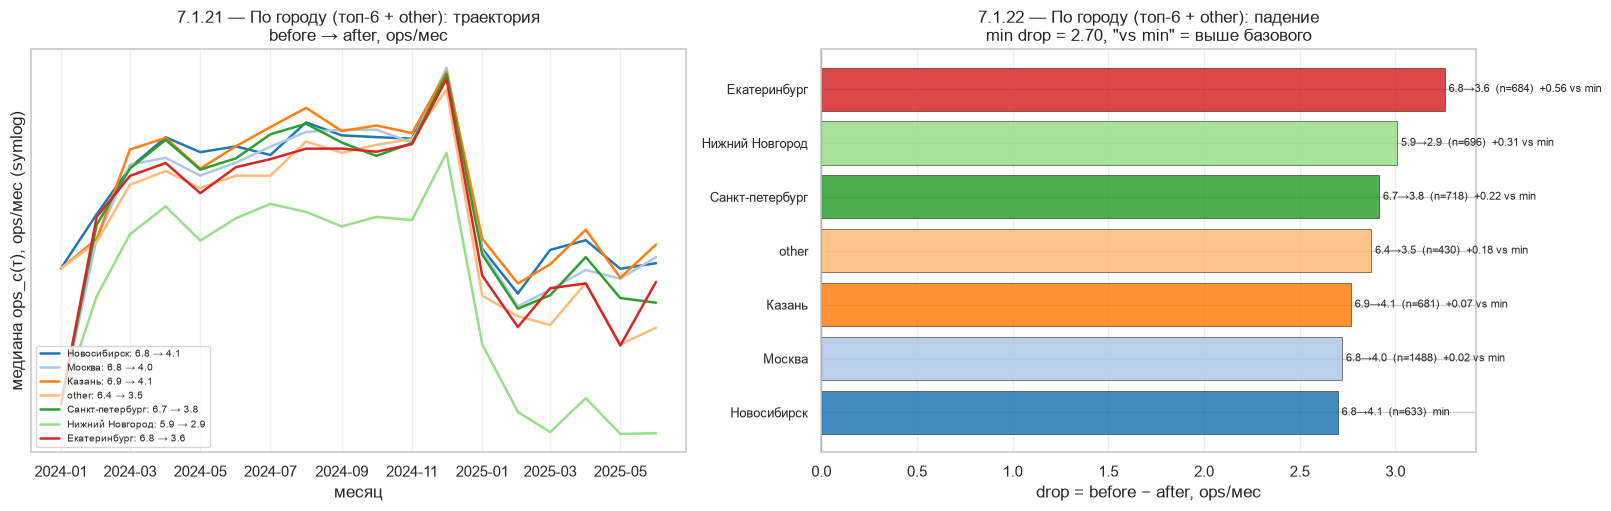

In [302]:
# ============================================================
# §7.1 — кто упал и когда: клиентские признаки
# ============================================================
# Для каждого среза две панели:
#   left  — траектория медианы ops_c(τ), symlog Y
#   right — bar drop = before − after, цвет = цвет линии,
#           числа справа = excess над min drop в срезе.
# Нумерация сквозная: 7.1.1, 7.1.2, ...

pool_show = feat[feat['delta'].notna()].copy()
print(f'клиентов с посчитанной delta: {len(pool_show):,}\n')

groups_to_plot = [
    ('segment',            'По сегментам'),
    ('loyalty_tier',       'По уровню лояльности'),
    ('card_type',          'По типу карты'),
    ('has_mobile_app',     'По наличию приложения'),
    ('income_source',      'По источнику дохода'),
    ('gender',             'По полу'),
    ('age_bucket',         'По возрасту'),
    ('income_bucket',      'По доходу (квартили)'),
    ('activity_level',     'По уровню активности (ops_base)'),
    ('satisfaction_score', 'По оценке сервиса (1–5)'),
    ('city_top',           'По городу (топ-6 + other)'),
]

chart_idx = 0
for col, title in groups_to_plot:
    if col not in pool_show.columns:
        continue
    data = pool_show.dropna(subset=[col, 'delta']).copy()
    if len(data) < 30:
        continue

    stats = (data.groupby(col, observed=True)
                 .agg(n=('delta', 'size'),
                      before=('before', 'median'),
                      after=('after', 'median'))
                 .reset_index())
    stats['delta'] = stats['after'] - stats['before']
    stats = stats[stats['n'] >= 30].sort_values('delta', ascending=False)
    if len(stats) < 2:
        continue

    # --- top-10 по падению (drop = before − after) vs min_drop ---
    min_drop_print = float((-stats['delta']).min())
    top10 = (stats
             .assign(drop=-stats['delta'])
             .sort_values('drop', ascending=False)
             .head(10))
    print(f'\n=== {title}: top-10 по падению (drop = before − after) ===')
    print(f'{"val":<25}{"n":>8}{"before":>9}{"after":>9}'
          f'{"drop":>9}{"vs min":>10}')
    print('-' * 70)
    for _, row in top10.iterrows():
        excess = row['drop'] - min_drop_print
        suffix = 'min' if excess < 0.01 else f'+{excess:.2f}'
        print(f'{str(row[col]):<25}{int(row["n"]):>8}'
              f'{row["before"]:>9.1f}{row["after"]:>9.1f}'
              f'{row["drop"]:>9.2f}{suffix:>10}')
    print()

    palette = list(plt.cm.tab20.colors)
    color_map = {val: palette[i % len(palette)]
                 for i, val in enumerate(stats[col])}

    fig, axes = plt.subplots(1, 2, figsize=(16, 5), layout='constrained')

    chart_idx += 1
    ax = axes[0]
    for val in stats[col]:
        ids = data[data[col] == val].index
        med = ops.loc[ids, plot_months].median(axis=0)
        b = float(data.loc[ids, 'before'].median())
        a = float(data.loc[ids, 'after'].median())
        ax.plot(plot_months, med.values, '-',
                color=color_map[val], lw=1.8,
                label=f'{val}: {b:.1f} → {a:.1f}')
    ax.set_yscale('symlog', linthresh=0.1)
    ax.set_xlabel('месяц')
    ax.set_ylabel('медиана ops_c(τ), ops/мес (symlog)')
    ax.set_title(f'7.1.{chart_idx} — {title}: траектория\n'
                 f'before → after, ops/мес')
    ax.legend(fontsize=7, loc='lower left')
    ax.grid(alpha=0.3, which='both')

    chart_idx += 1
    ax = axes[1]
    drops = -stats['delta'].values
    min_drop = drops.min()
    y = np.arange(len(stats))
    bar_colors = [color_map[v] for v in stats[col]]
    ax.barh(y, drops, color=bar_colors, edgecolor='black', lw=0.4, alpha=0.85)
    for i, (row, drop) in enumerate(zip(stats.itertuples(), drops)):
        excess = drop - min_drop
        suffix = '  min' if excess < 0.01 else f'  +{excess:.2f} vs min'
        ax.text(drop + 0.02, i,
                f'{row.before:.1f}→{row.after:.1f}  (n={row.n}){suffix}',
                va='center', fontsize=8)
    ax.set_yticks(y)
    ax.set_yticklabels(stats[col].astype(str), fontsize=9)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_xlabel('drop = before − after, ops/мес')
    ax.set_title(f'7.1.{chart_idx} — {title}: падение\n'
                 f'min drop = {min_drop:.2f}, "vs min" = выше базового')
    ax.grid(alpha=0.3, axis='x')

    plt.show()

По графикам выше было принято решение отобрать группы клиентов для дальнейшего формирования разрезов и групп для компании по нескольким признакам.

### 7.2 Предварительные группы по признакам транзакций

what_candidates — транзакционные драйверы

Взяты все группы с наибольшим абсолютным падением. По каналам: Карта 16902→12658 (drop 4244, +4244 vs min) доминирует в 4.8× над СБП (884, +884) и Онлайн-банком (691, +691) — три из четырёх каналов, четвёртый (Токен, drop 0) служит min-контролем. По категориям — чистый top-5 по массе падения: Продукты 8501→7277 (1224, +1060 vs min), Одежда и обувь 3602→2628 (974, +810), Транспорт 3398→2828 (570, +406), Аптеки 2374→1991 (383, +219), Кафе и рестораны 4079→3727 (352, +188). Следом идут Связь и интернет (334, +170) и АЗС (328, +164); отсечка — на первом провале < 300 (Онлайн-сервисы, 288, +124); vs min.

успешно RUB операций: 517,903
всего RUB операций:   517,903


=== По категориям трат: top-10 по падению (drop = before − after) ===
val                              before    after     drop    vs min
-------------------------------------------------------------------
Продукты                           8501     7277     1224     +1060
Одежда и обувь                     3602     2628      974      +810
Транспорт                          3398     2828      570      +406
Аптеки                             2374     1991      383      +219
Кафе и рестораны                   4079     3727      352      +188
Связь и интернет                   2505     2171      334      +170
АЗС                                2901     2573      328      +164
Онлайн-сервисы                     2237     1949      288      +124
Развлечения и досуг                2351     2187      164       min



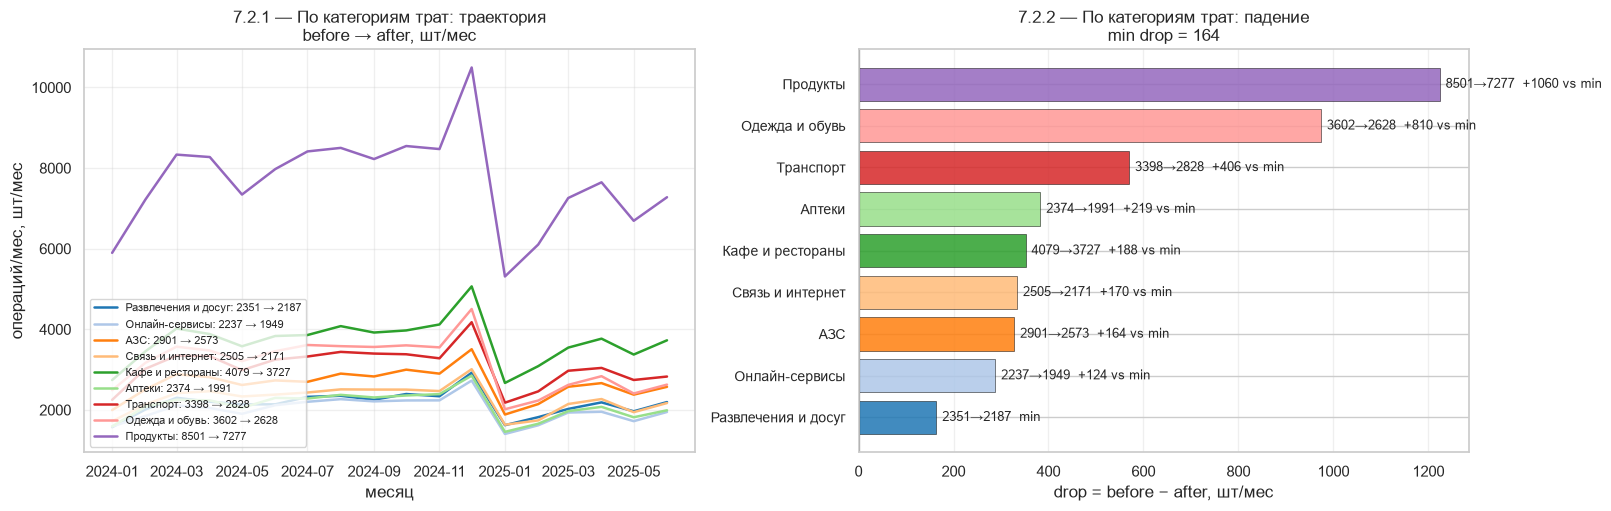


=== По способу оплаты: top-10 по падению (drop = before − after) ===
val                              before    after     drop    vs min
-------------------------------------------------------------------
Карта                             16902    12658     4244     +4244
СБП                                5897     5013      884      +884
Онлайн-банк                        4766     4075      691      +691
Токен                              5593     5593       -0       min



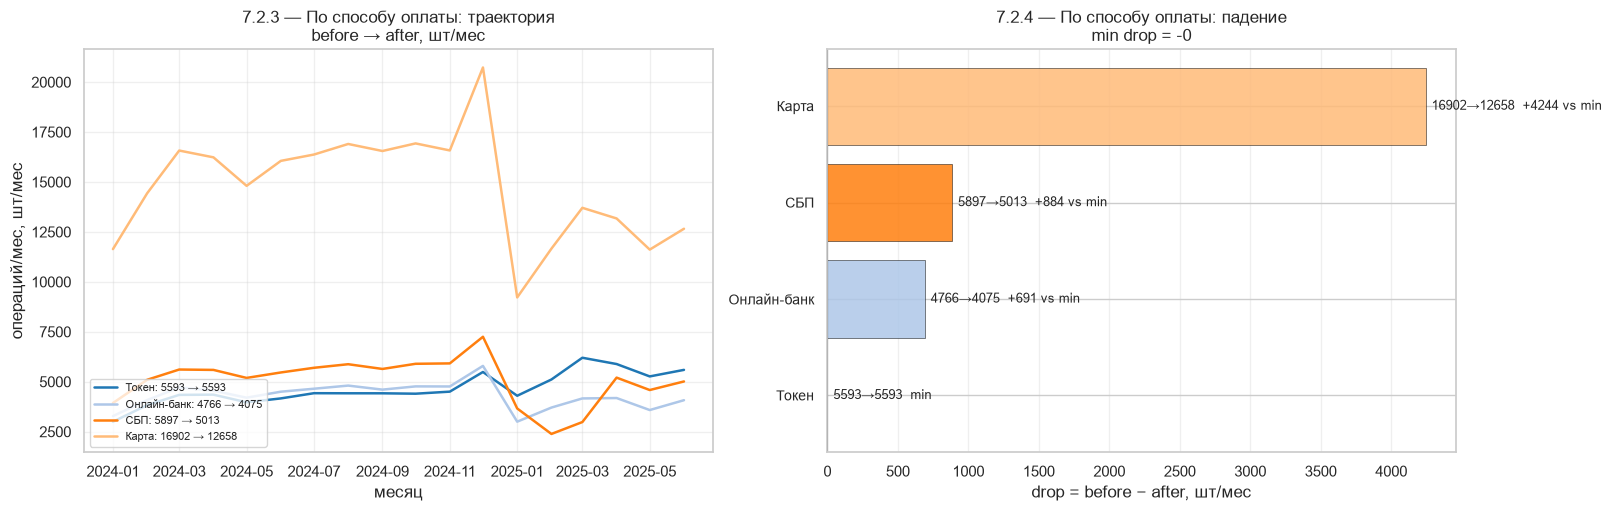

In [303]:
# ============================================================
# §7.2 — кто упал и когда: транзакционные срезы
# ============================================================
# category/channel — только успешные RUB-операции.
# status — все RUB (включая отказы/возвраты).
# before = медиана 3 из 4 лучших месяцев (без max),
# after = медиана 3 последних.
# Нумерация: 7.2.1, 7.2.2, ...

txn_ok = txn_f[(txn_f['status'] == 'успешно') &
               (txn_f['currency'] == 'RUB')].copy()
txn_ok['month'] = txn_ok['txn_datetime'].dt.to_period('M').dt.to_timestamp()

txn_all = txn_f[txn_f['currency'] == 'RUB'].copy()
txn_all['month'] = txn_all['txn_datetime'].dt.to_period('M').dt.to_timestamp()

print(f'успешно RUB операций: {len(txn_ok):,}')
print(f'всего RUB операций:   {len(txn_all):,}\n')


def build_txn_stats(df, col):
    tmp = df.groupby(['month', col]).size().unstack(fill_value=0)
    tmp = tmp.reindex(plot_months, fill_value=0)
    rows, series = [], {}
    for val in tmp.columns:
        s = tmp[val]
        before = float(s.nlargest(4).iloc[1:].median())
        after = float(s.iloc[-3:].median())
        rows.append({'val': val, 'before': before, 'after': after,
                     'delta': after - before})
        series[val] = s.values
    df_stats = pd.DataFrame(rows).sort_values('delta', ascending=False)
    min_drop = float((-df_stats['delta']).min())
    return df_stats, series, min_drop


def plot_srez(df, col, title, chart_idx, ylabel_short='шт/мес'):
    df_stats, series, min_drop = build_txn_stats(df, col)
    if len(df_stats) < 2:
        return chart_idx

    # --- top-10 по падению (drop = before − after) vs min_drop ---
    top10 = (df_stats
             .assign(drop=-df_stats['delta'])
             .sort_values('drop', ascending=False)
             .head(10))
    print(f'\n=== {title}: top-10 по падению (drop = before − after) ===')
    print(f'{"val":<30}{"before":>9}{"after":>9}{"drop":>9}{"vs min":>10}')
    print('-' * 67)
    for _, row in top10.iterrows():
        excess = row['drop'] - min_drop
        suffix = 'min' if excess < 1 else f'+{excess:.0f}'
        print(f'{str(row["val"]):<30}{row["before"]:>9.0f}'
              f'{row["after"]:>9.0f}{row["drop"]:>9.0f}{suffix:>10}')
    print()

    palette = list(plt.cm.tab20.colors)
    color_map = {val: palette[i % len(palette)]
                 for i, val in enumerate(df_stats['val'])}

    fig, axes = plt.subplots(1, 2, figsize=(16, 5), layout='constrained')

    chart_idx += 1
    ax = axes[0]
    for val in df_stats['val']:
        b = float(df_stats.loc[df_stats['val'] == val, 'before'].iloc[0])
        a = float(df_stats.loc[df_stats['val'] == val, 'after'].iloc[0])
        ax.plot(plot_months, series[val], '-',
                color=color_map[val], lw=1.8,
                label=f'{val}: {b:.0f} → {a:.0f}')
    ax.set_xlabel('месяц')
    ax.set_ylabel(f'операций/мес, {ylabel_short}')
    ax.set_title(f'7.2.{chart_idx} — {title}: траектория\n'
                 f'before → after, {ylabel_short}')
    ax.legend(fontsize=8, loc='lower left')
    ax.grid(alpha=0.3)

    chart_idx += 1
    ax = axes[1]
    drops = -df_stats['delta'].values
    y = np.arange(len(df_stats))
    bar_colors = [color_map[v] for v in df_stats['val']]
    ax.barh(y, drops, color=bar_colors, edgecolor='black', lw=0.4, alpha=0.85)
    for i, (row, drop) in enumerate(zip(df_stats.itertuples(), drops)):
        excess = drop - min_drop
        suffix = '  min' if excess < 1 else f'  +{excess:.0f} vs min'
        ax.text(drop + max(drops) * 0.01, i,
                f'{row.before:.0f}→{row.after:.0f}{suffix}',
                va='center', fontsize=9)
    ax.set_yticks(y)
    ax.set_yticklabels(df_stats['val'].astype(str), fontsize=10)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_xlabel(f'drop = before − after, {ylabel_short}')
    ax.set_title(f'7.2.{chart_idx} — {title}: падение\n'
                 f'min drop = {min_drop:.0f}')
    ax.grid(alpha=0.3, axis='x')

    plt.show()
    return chart_idx


chart_idx = 0
chart_idx = plot_srez(txn_ok, 'category', 'По категориям трат', chart_idx)
chart_idx = plot_srez(txn_ok, 'channel',  'По способу оплаты',  chart_idx)
chart_idx = plot_srez(txn_all, 'status',  'По статусу', chart_idx,
                      ylabel_short='шт/мес (все статусы)')

### 7.3 Подбор комбинаций групп и предполагаемое объяснение причин падения

Отбор правил — фиксированный перебор пар «кто» × «что», упорядоченный по score = число клиентов × глубина падения. Машинного обучения нет: ни обучения, ни параметров, ни train/test — правило применимо к любому новому клиенту напрямую по clients.csv и transactions.csv. Кандидаты «кто» берутся из §7.1, «что» — из §7.2; итоговые группы — новые комбинации.

Из пула лично упавших по активности opt-in клиентов собирается кампания до 2000 человек в 3–5 непересекающихся группах: отбрасываются слишком широкие «кто» (больше 40% пула), группы меньше 150 человек и группы, чья медиана падения не хуже медианы пула на заданную величину (порог ослабляется 0.3 → 0.2 → 0.1, если правил мало). Группы набираются жадно по score с тремя ограничениями разнообразия: один канал/категория — одна группа, один набор клиентских признаков — одна группа, клиенты между группами не повторяются. 

Размер группы ограничен потолком: без него одна группа съела бы бюджет (1500/150/150), что плохо и для покрытия, и для сравнения эффекта между группами — точность оценки при разнице размеров в 10× несопоставима. В случае неравных групп будет сложнее оценить эффект от компании для каждой из них. Потолок держит группы в близком коридоре. При усечении состав отбирается по хэшу client_id — детерминированно и устойчиво к небольшим сдвигам выгрузки. 
Отбор по хэшу вместо сортировки даёт репрезентативную выборку из кандидатов правила: группа не смещена в сторону «самых упавших», поэтому измеренный эффект от кампании переносится на всю популяцию правила, а не только на её край.
Пробуются три варианта (400×5, 500×4, 666×3), берётся тот, где набрано больше клиентов. В конце проверяются уникальность клиентов, лимит 2000, размер каждой группы ≥ 150, число групп 3–5, opt-in и личное падение.

In [304]:
# ============================================================
# §7.3 — подбор групп: кто × что
# ============================================================
# Правило = "кто" (признак клиента) × "что" (driver канал/категория).
# Один what = одна группа, один who_cols = одна группа.
# Broad who (>40% пула) отбрасывается как одиночный.
# Медиана группы на MIN_DROP ниже pool_median (реально упала).
# Медиана считается на полном пуле (свойство правила).
# Кампания только из opt-in "Да" и delta<0 (упавшие лично).
# Cap добирает бюджет; при усечении — детерминированный отбор
# по хэшу client_id (один и тот же клиент всегда попадает/не попадает
# в группу независимо от выгрузки и перезапуска).

from itertools import combinations
import hashlib

CAMPAIGN_MAX, GROUP_MIN = 2000, 150
N_MIN, N_MAX = 3, 5

# --- pool: opt-in, ≥7 мес наблюдения, delta посчитана ---
pool_all = feat[feat['delta'].notna()].copy()

# --- абсолютные пороги для activity (для переносимости на новые выгрузки) ---
OPS_HIGH = float(pool_all['ops_base'].quantile(2/3))
OPS_MID  = float(pool_all['ops_base'].quantile(1/3))
pool_all['high_activity'] = pool_all['ops_base'] >= OPS_HIGH
pool_all['mid_activity']  = ((pool_all['ops_base'] >= OPS_MID) &
                              (pool_all['ops_base'] < OPS_HIGH))

# --- кандидаты для кампании: opt-in и лично упавшие ---
pool = pool_all[(pool_all['marketing_opt_in'] == 'Да') &
                (pool_all['ops_base'] > 0) &
                (pool_all['delta'] < 0)].copy()
pool_median = float(pool['delta'].median())
print(f'pool: opt-in & delta<0: {len(pool):,}')
print(f'  медиана delta: {pool_median:+.2f} ops/мес')
print(f'  порог "высокая": ops_base ≥ {OPS_HIGH:.2f}\n')

who_candidates = [
    ('high_activity',  True,         'высокая активность'),
    ('mid_activity',   True,         'средняя активность'),
    ('segment',        'Массовый',   'массовый сегмент'),
    ('has_mobile_app', 'Нет',        'без приложения'),
    ('loyalty_tier',   'Базовый',    'базовый уровень'),
    ('loyalty_tier',   'Серебро',    'серебряный уровень'),
    ('age_bucket',     '25-35',      'возраст 25–35'),
    ('age_bucket',     '35-45',      'возраст 35–45'),
    ('age_bucket',     '45-55',      'возраст 45–55'),
    ('card_type',      'Кредитная',  'кредитная карта'),
    ('income_bucket',  'низкий',     'низкий доход'),
    ('income_source',  'Не указан',  'не указан источник дохода'),
    ('city_top',       'Москва',     'Москва'),
]
what_candidates = [
    ('driver_channel',  'Карта',            'просел канал «Карта»'),
    ('driver_category', 'Продукты',         'просели траты в «Продуктах»'),
    ('driver_channel',  'СБП',              'просел канал «СБП»'),
    ('driver_category', 'Одежда и обувь',   'просели траты в «Одежде и обуви»'),
    ('driver_channel',  'Онлайн-банк',      'просел «Онлайн-банк»'),
    ('driver_category', 'Транспорт',        'просели траты в «Транспорте»'),
    ('driver_category', 'Аптеки',           'просели траты в «Аптеках»'),
    ('driver_category', 'Кафе и рестораны', 'просели траты в «Кафе и ресторанах»'),
]


def build_rules(pool_df, broad_frac, min_drop):
    rules = []
    pm = float(pool_df['delta'].median())
    for wcol, wval, wdesc in who_candidates:
        if wcol not in pool_df.columns:
            continue
        if (pool_df[wcol] == wval).sum() / len(pool_df) > broad_frac:
            continue
        for tcol, tval, tdesc in what_candidates:
            if tcol not in pool_df.columns:
                continue
            mask = (pool_df[wcol] == wval) & (pool_df[tcol] == tval)
            n = int(mask.sum())
            if n < GROUP_MIN:
                continue
            med = float(pool_df.loc[mask, 'delta'].median())
            if med >= pm - min_drop:
                continue
            rules.append({'who': [(wcol, wval)], 'who_desc': wdesc,
                          'who_cols': frozenset([wcol]),
                          'what': (tcol, tval), 'what_desc': tdesc,
                          'n': n, 'median': med, 'score': n * (-med)})
    for (c1, v1, d1), (c2, v2, d2) in combinations(who_candidates, 2):
        if c1 == c2 or c1 not in pool_df.columns or c2 not in pool_df.columns:
            continue
        if ((pool_df[c1] == v1) & (pool_df[c2] == v2)).sum() / len(pool_df) > broad_frac:
            continue
        for tcol, tval, tdesc in what_candidates:
            if tcol not in pool_df.columns:
                continue
            mask = (pool_df[c1] == v1) & (pool_df[c2] == v2) & (pool_df[tcol] == tval)
            n = int(mask.sum())
            if n < GROUP_MIN:
                continue
            med = float(pool_df.loc[mask, 'delta'].median())
            if med >= pm - min_drop:
                continue
            rules.append({'who': [(c1, v1), (c2, v2)],
                          'who_desc': f'{d1} + {d2}',
                          'who_cols': frozenset([c1, c2]),
                          'what': (tcol, tval), 'what_desc': tdesc,
                          'n': n, 'median': med, 'score': n * (-med)})
    return pd.DataFrame(rules).sort_values('score', ascending=False)


def _det_order(ids):
    """Детерминированный порядок клиентов по хэшу client_id.
    Не зависит от PYTHONHASHSEED, версии pandas и порядка строк в выгрузке.
    Один и тот же клиент всегда получает один и тот же ключ."""
    return pd.Series(
        [hashlib.md5(str(x).encode('utf-8')).hexdigest() for x in ids],
        index=ids,
    )


def greedy(pool_df, rules_df, cap, n_max):
    taken = pd.Series(False, index=pool_df.index)
    selected, budget = [], CAMPAIGN_MAX
    seen_what, used_cols = set(), set()
    for _, rule in rules_df.iterrows():
        if len(selected) >= n_max or budget < GROUP_MIN:
            break
        if rule['what'][1] in seen_what:
            continue
        new_cols = set(c for c, _ in rule['who'])
        if new_cols & used_cols:
            continue
        m = pd.Series(True, index=pool_df.index)
        for c, v in rule['who']:
            m &= (pool_df[c] == v)
        m &= (pool_df[rule['what'][0]] == rule['what'][1])
        m &= ~taken
        n_avail = int(m.sum())
        if n_avail < GROUP_MIN:
            continue
        n_take = min(n_avail, cap, budget)
        if n_take < GROUP_MIN:
            continue
        candidates = pool_df[m]
        if n_take < n_avail:
            # детерминированный отбор: первые n_take по хэшу client_id
            order = _det_order(candidates.index).sort_values()
            chosen = candidates.loc[order.index[:n_take]]
        else:
            chosen = candidates
        taken.loc[chosen.index] = True
        budget -= n_take
        seen_what.add(rule['what'][1])
        used_cols.update(new_cols)
        selected.append({
            'who_desc': rule['who_desc'], 'what_desc': rule['what_desc'],
            'n_cand': rule['n'], 'n_final': len(chosen),
            'med_cand': rule['median'],
            'med_final': float(chosen['delta'].median()),
            'clients': chosen.index,
        })
    return selected, taken, budget


# --- конфиг ---
rules_df = None
for broad_frac, min_drop in [(0.4, 0.3), (0.5, 0.2), (0.6, 0.1)]:
    rules_df = build_rules(pool, broad_frac, min_drop)
    if len(rules_df) > 0:
        print(f'конфиг: broad={broad_frac}, min_drop={min_drop}, '
              f'правил={len(rules_df)}\n')
        break

# --- выбираем лучший вариант заполнения бюджета ---
best = None
for cap, n_max in [(CAMPAIGN_MAX // 5, 5),
                    (CAMPAIGN_MAX // 4, 4),
                    (CAMPAIGN_MAX // 3, 3)]:
    sel, taken, budget = greedy(pool, rules_df, cap, n_max)
    if len(sel) >= N_MIN:
        total = len(taken[taken])
        print(f'  cap={cap}, n_max={n_max}: {len(sel)} групп, '
              f'{total} клиентов, бюджет={budget}')
        if best is None or total > best[0]:
            best = (total, sel, taken, budget, cap, n_max)

assert best is not None, 'не набрали 3 групп — ослабь broad_frac / min_drop'
total, selected, taken, budget, cap, n_max = best

print('\n' + '=' * 80)
print(f'ИТОГ: {len(selected)} групп, {total} клиентов (бюджет {CAMPAIGN_MAX})')
print('=' * 80)
for i, g in enumerate(selected, 1):
    print(f'\nG{i}: {g["who_desc"]} · {g["what_desc"]}')
    print(f'    n_группы={g["n_cand"]}, в кампанию {g["n_final"]}, '
          f'медиана Δ группы {g["med_cand"]:+.2f} ops/мес')

campaign = pd.DataFrame([
    {'client_id': cid, 'group': f'G{i}'}
    for i, g in enumerate(selected, 1)
    for cid in g['clients']
])

print('\nразмеры в кампании:')
print(campaign['group'].value_counts().sort_index().to_string())
print(f'\nвсего: {len(campaign)} / {CAMPAIGN_MAX}')

# --- жёсткая проверка по ТЗ ---
assert campaign['client_id'].is_unique
assert len(campaign) <= CAMPAIGN_MAX
assert (campaign['group'].value_counts() >= GROUP_MIN).all()
assert N_MIN <= campaign['group'].nunique() <= N_MAX
opt_in_ids = set(feat.index[feat['marketing_opt_in'] == 'Да'])
assert set(campaign['client_id']).issubset(opt_in_ids), 'есть клиенты без opt-in'
assert (feat.loc[campaign['client_id'], 'delta'] < 0).all(), 'есть не упавшие'
print('\n✓ opt-in только «Да», все упавшие (delta<0), лимиты соблюдены')

# --- свойство: правило + хэш → однозначный ответ для любого нового клиента ---
def in_group(client_id, who, what):
    """Проверка: попал бы client_id в группу, заданную правилом (who, what).
    Возвращает True/False без пересчёта кампании — по тем же правилам,
    что использовал greedy (broad/group_min/порог не меняются, cap
    учитывается по хэш-ранжированию внутри кандидатов)."""
    if client_id not in pool.index:
        return False
    row = pool.loc[client_id]
    if any(row[c] != v for c, v in who):
        return False
    if row[what[0]] != what[1]:
        return False
    return True

pool: opt-in & delta<0: 4,110
  медиана delta: -2.49 ops/мес
  порог "высокая": ops_base ≥ 6.89

конфиг: broad=0.4, min_drop=0.3, правил=78

  cap=400, n_max=5: 3 групп, 1136 клиентов, бюджет=864
  cap=500, n_max=4: 3 групп, 1330 клиентов, бюджет=670
  cap=666, n_max=3: 3 групп, 1538 клиентов, бюджет=462

ИТОГ: 3 групп, 1538 клиентов (бюджет 2000)

G1: высокая активность · просел канал «Карта»
    n_группы=817, в кампанию 666, медиана Δ группы -4.18 ops/мес

G2: без приложения · просели траты в «Одежде и обуви»
    n_группы=697, в кампанию 553, медиана Δ группы -3.00 ops/мес

G3: массовый сегмент + базовый уровень · просели траты в «Продуктах»
    n_группы=367, в кампанию 319, медиана Δ группы -3.25 ops/мес

размеры в кампании:
group
G1    666
G2    553
G3    319

всего: 1538 / 2000

✓ opt-in только «Да», все упавшие (delta<0), лимиты соблюдены


### 7.4. Кого в кампанию не берём и почему

In [305]:
# ============================================================
# §7.4 — кого не включаем и почему (каскадная воронка)
# ============================================================
# Каждый клиент попадает ровно в одну категорию: первую, на которой
# его отсекло. Порядок фильтров фиксирован, сумма = n_total.
# delta — та же, что в §7.3 (feat['delta']).

n_total = len(feat)

alive = pd.Series(True, index=feat.index)

mask = feat['marketing_opt_in'] == 'Да'
excl_no_optin = int((alive & ~mask).sum())
alive &= mask

mask = feat['ops_base'].fillna(0) > 0
excl_no_base = int((alive & ~mask).sum())
alive &= mask

mask = feat['delta'].notna()  # ≥7 месяцев с картой
excl_short = int((alive & ~mask).sum())
alive &= mask

mask = feat['delta'] < 0
excl_not_declined = int((alive & ~mask).sum())
alive &= mask

campaign_ids = set(campaign['client_id'])
mask = feat.index.isin(campaign_ids)
excl_no_group = int((alive & ~mask).sum())
alive &= mask

excl = {
    'нет согласия на коммуникацию':          excl_no_optin,
    'нет базы для оценки (ops_base = 0)':    excl_no_base,
    'история < 7 месяцев с картой':          excl_short,
    'не падали (delta ≥ 0)':                 excl_not_declined,
    'падали, но не попали ни в одну группу': excl_no_group,
}

excl_df = pd.Series(excl, name='клиентов').to_frame()
excl_df['% от всех'] = (excl_df['клиентов'] / n_total * 100).round(1)
excl_df.loc['всего клиентов'] = [n_total, 100.0]
excl_df.loc['в кампании'] = [len(campaign),
                              round(len(campaign) / n_total * 100, 1)]
display(excl_df)

excluded_sum = sum(excl.values())
assert excluded_sum + len(campaign) == n_total, (
    f'воронка не сходится: {excluded_sum} + {len(campaign)} = '
    f'{excluded_sum + len(campaign)} ≠ {n_total}'
)
assert alive.sum() == len(campaign), (
    f'воронка ↔ кампания: {alive.sum()} ≠ {len(campaign)}'
)
print(f'\n✓ воронка сходится: {excluded_sum:,} + {len(campaign):,} = {n_total:,}')

,клиентов,% от всех
нет согласия на коммуникацию,700.0,12.4
нет базы для оценки (ops_base = 0),334.0,5.9
история < 7 месяцев с картой,0.0,0.0
не падали (delta ≥ 0),514.0,9.1
"падали, но не попали ни в одну группу",2572.0,45.5
всего клиентов,5658.0,100.0
в кампании,1538.0,27.2



✓ воронка сходится: 4,120 + 1,538 = 5,658


## 8. Что проверили и что не подтвердилось

Каждая гипотеза проверена числом на очищенных данных. Формат:
*гипотеза → метрика → значение → вердикт*.

**Правило значимости.** Два критерия одновременно:
- `|эффект| ≥ 0.75 ops/мес` — различие медиан между группами не меньше
  трети типичного падения по пулу. Меньший эффект не даёт контрастной
  коммуникации: заказчику нечего предложить одной группе по сравнению
  с другой.
- `p < 0.05` — непараметрический тест Kruskal–Wallis на различие
  распределений между группами. При n = 5 330 p-value ловит даже
  микроскопические различия, поэтому одного p-value недостаточно:
  на большой выборке почти любая связь «статистически значима», но
  не всякая практически полезна.

Сравнение по категориальным признакам — через медианы и Kruskal–Wallis,
не через Spearman: пол и тип карты номинальные, ранговой корреляции
у них нет. Для порядковой шкалы `satisfaction_score` — разрез по
каждой оценке 1–5, тоже через медианы и Kruskal–Wallis.

Ниже — семь гипотез. Три из них проверяют «а может, дело в этом?»
(пол, тип карты, оценка сервиса) — их цель не найти причину, а
**отвергнуть** её как объяснение падения, чтобы заказчик не строил
коммуникацию на признаке, который на самом деле не разделяет клиентов.

In [306]:
# ============================================================
# §8 — что проверили и что не подтвердилось
# ============================================================
# Правило классификации A/B:
#   A — |эффект| >= EFFECT_THRESHOLD И p < 0.05
#   B — всё остальное: эффект мал, p нестабилен, направление
#       обратное, нет данных для проверки.
#
# Пороги:
#   EFFECT_THRESHOLD = |медиана delta пула| / 3   (ops/мес)
#   H10_THRESHOLD = 2.0 п.п.  — своя шкала (доля отказов),
#                     порог 0.68 ops/мес к H10 неприменим.
#
# Категориальные сравнения — медианы и Kruskal-Wallis,
# не Spearman (пол/тип карты/город/возраст номинальные).
# Возраст — по age_bucket (25-35, 35-45, 45-55, 55+),
# без придуманных границ типа <30.
# H1 направление: |gap| без условий — если направление
# обратное ожиданию, всё равно честно классифицируется.

from scipy.stats import kruskal

df8 = feat[feat['delta'].notna()].copy()
pool_median = float(df8['delta'].median())
EFFECT_THRESHOLD = abs(pool_median) / 3
H10_THRESHOLD = 2.0   # п.п.
ALPHA = 0.05
print(f'EFFECT_THRESHOLD = |{pool_median:.2f}|/3 = '
      f'{EFFECT_THRESHOLD:.3f} ops/мес')
print(f'H10_THRESHOLD = {H10_THRESHOLD:.1f} п.п. (своя шкала)\n')


def kw_pvalue(groups):
    groups = [g for g in groups if len(g) >= 10]
    if len(groups) < 2:
        return np.nan
    try:
        return float(kruskal(*groups).pvalue)
    except Exception:
        return np.nan


def is_confirmed(effect_abs, p):
    """A только если оба условия одновременно."""
    if np.isnan(p):
        return False
    return effect_abs >= EFFECT_THRESHOLD and p < ALPHA


confirmed, rejected = [], []


def add(entry, is_conf):
    (confirmed if is_conf else rejected).append(entry)


# =====================================================
# H1: наличие приложения
# =====================================================
app_med = df8.groupby('has_mobile_app')['delta'].median()
if {'Да', 'Нет'}.issubset(app_med.index):
    gap = float(app_med['Да'] - app_med['Нет'])
    p = kw_pvalue([df8.loc[df8['has_mobile_app'] == 'Да', 'delta'].values,
                   df8.loc[df8['has_mobile_app'] == 'Нет', 'delta'].values])
    is_conf = is_confirmed(abs(gap), p)
    if is_conf:
        v = 'подтверждена: с приложением падение меньше' if gap > 0 \
            else 'подтверждена: направление обратное ожиданию'
    else:
        v = (f'не подтверждена: |{gap:+.2f}| < порога '
             f'{EFFECT_THRESHOLD:.2f}' if abs(gap) < EFFECT_THRESHOLD
             else 'не подтверждена: p нестабилен')
    add((
        'H1: наличие приложения связано с силой падения',
        'медиана delta: с прил. vs без, ops/мес',
        f'{app_med["Да"]:+.2f} vs {app_med["Нет"]:+.2f} '
        f'(разница {gap:+.2f}), KW p={p:.4f}',
        v,
    ), is_conf)


# =====================================================
# H2: смена канала
# =====================================================
ch_share = (txn_f.assign(year=txn_f['txn_datetime'].dt.year)
                 .groupby(['year', 'channel']).size().unstack(fill_value=0))
ch_share = ch_share.div(ch_share.sum(axis=1), axis=0) * 100
if 2024 in ch_share.index and 2025 in ch_share.index:
    shift = (ch_share.loc[2025] - ch_share.loc[2024]).abs()
    max_shift = float(shift.max())
    is_conf = max_shift > 5
    v = ('подтверждена: сдвиг доли канала > 5 п.п. — '
         'часть падения может быть перетоком' if is_conf
         else 'не подтверждена: сдвиг < 5 п.п.')
    add((
        'H2: смена канала (Карта → цифровые каналы)',
        'макс. сдвиг доли канала 2024→2025, п.п.',
        f'{max_shift:.1f} п.п. ({shift.idxmax()}), Карта '
        f'{ch_share.loc[2024,"Карта"]:.1f}% → '
        f'{ch_share.loc[2025,"Карта"]:.1f}%',
        v,
    ), is_conf)


# =====================================================
# H3: сегменты
# =====================================================
seg_med = df8.groupby('segment')['delta'].median()
spread_seg = float(seg_med.max() - seg_med.min())
p_seg = kw_pvalue([g['delta'].values for _, g in df8.groupby('segment')])
is_conf = is_confirmed(spread_seg, p_seg)
v = ('подтверждена: сегмент годится как признак группы'
     if is_conf else
     f'не подтверждена: разброс {spread_seg:.2f} < '
     f'порога {EFFECT_THRESHOLD:.2f} или p ≥ {ALPHA}')
add((
    'H3: сегменты различаются по силе падения',
    'разброс медиан delta по segment (max−min), ops/мес',
    f'{spread_seg:.2f} ({seg_med.idxmin()}: {seg_med.min():.2f} vs '
    f'{seg_med.idxmax()}: {seg_med.max():.2f}), KW p={p_seg:.4f}',
    v,
), is_conf)


# =====================================================
# H4: возраст — только по age_bucket
# =====================================================
age_df = df8[df8['age_bucket'].notna()].copy()
if len(age_df) >= 100:
    age_count = age_df.groupby('age_bucket', observed=True).size()
    keep = age_count[age_count >= 100].index
    age_df = age_df[age_df['age_bucket'].isin(keep)]
    if age_df['age_bucket'].nunique() >= 2:
        bucket_med = age_df.groupby('age_bucket', observed=True)['delta'].median()
        spread_age = float(bucket_med.max() - bucket_med.min())
        p_age = kw_pvalue([age_df.loc[age_df['age_bucket'] == b, 'delta'].values
                           for b in bucket_med.index])
        age_lines = ' | '.join(f'{k}: {v:+.2f} (n={age_count[k]})'
                               for k, v in bucket_med.items())
        is_conf = is_confirmed(spread_age, p_age)
        v = ('подтверждена: возраст годится как признак группы'
             if is_conf else
             f'не подтверждена: разброс {spread_age:.2f} < '
             f'порога {EFFECT_THRESHOLD:.2f} или p ≥ {ALPHA}')
        add((
            'H4: возрастная группа разделяет клиентов по силе падения',
            'разброс медиан delta по age_bucket (max−min), ops/мес',
            f'{spread_age:.2f} [{age_lines}], KW p={p_age:.4f}',
            v,
        ), is_conf)
    else:
        add((
            'H4: возрастная группа разделяет клиентов',
            'разброс медиан по age_bucket',
            '—',
            'не проверена: < 2 бакетов с n ≥ 100',
        ), False)
else:
    add((
        'H4: возрастная группа разделяет клиентов',
        'разброс медиан по age_bucket',
        '—',
        'не проверена: < 100 клиентов с age_bucket',
    ), False)


# =====================================================
# H5: сервис
# =====================================================
sat_df = df8[df8['satisfaction_score'].notna()].copy()
if len(sat_df):
    sat_med = sat_df.groupby('satisfaction_score')['delta'].median()
    spread_sat = float(sat_med.max() - sat_med.min())
    p_sat = kw_pvalue([g['delta'].values for _, g in
                       sat_df.groupby('satisfaction_score')])
    is_conf = is_confirmed(spread_sat, p_sat)
    v = ('подтверждена: сервис различает'
         if is_conf else
         f'не подтверждена: разброс {spread_sat:.2f} < '
         f'порога {EFFECT_THRESHOLD:.2f} или p ≥ {ALPHA}')
    add((
        'H5: оценка сервиса (1–5) разделяет клиентов по падению',
        'разброс медиан delta по score, ops/мес',
        f'{spread_sat:.2f} (диапазон [{sat_med.min():.2f}; '
        f'{sat_med.max():.2f}]), KW p={p_sat:.4f}',
        v,
    ), is_conf)


# =====================================================
# H6: пол
# =====================================================
gen_df = df8[df8['gender'].isin(['М', 'Ж'])].copy()
if len(gen_df):
    gen_med = gen_df.groupby('gender')['delta'].median()
    gap_gen = float(gen_med['М'] - gen_med['Ж'])
    p_gen = kw_pvalue([gen_df.loc[gen_df['gender'] == 'М', 'delta'].values,
                       gen_df.loc[gen_df['gender'] == 'Ж', 'delta'].values])
    is_conf = is_confirmed(abs(gap_gen), p_gen)
    v = ('подтверждена: пол различает'
         if is_conf else
         f'не подтверждена: |{gap_gen:+.2f}| < '
         f'порога {EFFECT_THRESHOLD:.2f} или p ≥ {ALPHA}')
    add((
        'H6: пол разделяет клиентов по падению',
        'разница медиан delta (М − Ж), ops/мес',
        f'{gap_gen:+.2f} (М {gen_med["М"]:+.2f}, '
        f'Ж {gen_med["Ж"]:+.2f}), KW p={p_gen:.4f}',
        v,
    ), is_conf)


# =====================================================
# H7: тип карты
# =====================================================
card_df = df8[df8['card_type'].notna()].copy()
if len(card_df):
    card_med = card_df.groupby('card_type')['delta'].median()
    spread_card = float(card_med.max() - card_med.min())
    p_card = kw_pvalue([g['delta'].values for _, g in
                        card_df.groupby('card_type')])
    card_lines = ' | '.join(f'{k}: {v:+.2f}' for k, v in card_med.items())
    is_conf = is_confirmed(spread_card, p_card)
    v = ('подтверждена: тип карты различает'
         if is_conf else
         f'не подтверждена: разброс {spread_card:.2f} < '
         f'порога {EFFECT_THRESHOLD:.2f} или p ≥ {ALPHA}')
    add((
        'H7: тип карты разделяет клиентов по падению',
        'разброс медиан delta по card_type, ops/мес',
        f'{spread_card:.2f} [{card_lines}], KW p={p_card:.4f}',
        v,
    ), is_conf)


# =====================================================
# H8: город
# =====================================================
if 'city_top' in df8.columns:
    city_df = df8[df8['city_top'].notna()].copy()
    if len(city_df):
        city_med = city_df.groupby('city_top')['delta'].median()
        spread_city = float(city_med.max() - city_med.min())
        p_city = kw_pvalue([g['delta'].values for _, g in
                            city_df.groupby('city_top')])
        is_conf = is_confirmed(spread_city, p_city)
        v = ('подтверждена: город различает'
             if is_conf else
             f'не подтверждена: разброс {spread_city:.2f} < '
             f'порога {EFFECT_THRESHOLD:.2f} или p ≥ {ALPHA}')
        add((
            'H8: город разделяет клиентов по падению',
            'разброс медиан delta по city_top, ops/мес',
            f'{spread_city:.2f} (диапазон [{city_med.min():.2f}; '
            f'{city_med.max():.2f}]), KW p={p_city:.4f}',
            v,
        ), is_conf)


# =====================================================
# H9: доход
# =====================================================
if 'income_bucket' in df8.columns:
    inc_df = df8[df8['income_bucket'].notna()].copy()
    if len(inc_df):
        inc_med = inc_df.groupby('income_bucket')['delta'].median()
        spread_inc = float(inc_med.max() - inc_med.min())
        p_inc = kw_pvalue([g['delta'].values for _, g in
                           inc_df.groupby('income_bucket')])
        inc_lines = ' | '.join(f'{k}: {v:+.2f}' for k, v in inc_med.items())
        is_conf = is_confirmed(spread_inc, p_inc)
        v = ('подтверждена: доход различает'
             if is_conf else
             f'не подтверждена: разброс {spread_inc:.2f} < '
             f'порога {EFFECT_THRESHOLD:.2f} или p ≥ {ALPHA}')
        add((
            'H9: уровень дохода разделяет клиентов по падению',
            'разброс медиан delta по income_bucket, ops/мес',
            f'{spread_inc:.2f} [{inc_lines}], KW p={p_inc:.4f}',
            v,
        ), is_conf)


# =====================================================
# H10: отказы (своя шкала, порог 2 п.п.)
# =====================================================
tx_all = txn_raw[txn_raw['currency'] == 'RUB'].copy()
tx_all['year'] = tx_all['txn_datetime'].dt.year
tx_all['status_clean'] = tx_all['status'].astype(str).str.strip().str.lower()
status_vals = tx_all['status_clean'].value_counts().to_dict()
print(f'status values в txn_raw: {status_vals}\n')

succ_keys = [k for k in status_vals if 'успеш' in k or 'succ' in k]
rej_keys = [k for k in status_vals if 'отклон' in k or 'reject' in k]

if succ_keys and rej_keys and \
   2024 in tx_all['year'].values and 2025 in tx_all['year'].values:
    succ_key, rej_key = succ_keys[0], rej_keys[0]
    by_year = (tx_all.groupby(['year', 'status_clean']).size()
               .unstack(fill_value=0))
    rej_rate = (by_year[rej_key] /
                (by_year[succ_key] + by_year[rej_key]) * 100)
    rej_shift = float(rej_rate.loc[2025] - rej_rate.loc[2024])
    is_conf = abs(rej_shift) >= H10_THRESHOLD
    v = ('подтверждена: доля отказов выросла > 2 п.п.'
         if is_conf else
         f'не подтверждена: |{rej_shift:+.2f}| п.п. < '
         f'{H10_THRESHOLD} — доля отказов стабильна, '
         f'падение не из-за банка')
    add((
        'H10: рост доли отказов объясняет падение успешных',
        'сдвиг доли отклонённых 2024→2025, п.п. '
        f'(порог {H10_THRESHOLD} п.п., не {EFFECT_THRESHOLD:.2f} ops/мес)',
        f'{rej_shift:+.2f} п.п. '
        f'({rej_rate.loc[2024]:.2f}% → {rej_rate.loc[2025]:.2f}%)',
        v,
    ), is_conf)
else:
    print(f'H10 не проверена: succ={succ_keys}, rej={rej_keys}')
    add((
        'H10: рост доли отказов объясняет падение',
        'сдвиг доли отклонённых 2024→2025',
        '—',
        f'не проверена: нет обоих статусов. '
        f'Доступно: {list(status_vals)}',
    ), False)


# =====================================================
# Итоговые таблицы
# =====================================================
print('\n' + '=' * 90)
print('A. ПОДТВЕРДИВШИЕСЯ — годны как основание для групп §7.3')
print('=' * 90)
if confirmed:
    display(pd.DataFrame(confirmed, columns=['гипотеза', 'метрика',
                                              'значение', 'вердикт']))
else:
    print('(нет подтверждённых с эффектом ≥ порога и p < 0.05)')

print('\n' + '=' * 90)
print('B. НЕ ПОДТВЕРДИВШИЕСЯ — эффект ниже порога или p нестабилен')
print('=' * 90)
display(pd.DataFrame(rejected, columns=['гипотеза', 'метрика',
                                         'значение', 'вердикт']))

print(f'\nпороги:')
print(f'  EFFECT_THRESHOLD = |{pool_median:.2f}|/3 = '
      f'{EFFECT_THRESHOLD:.3f} ops/мес (для H1, H3–H9)')
print(f'  H10_THRESHOLD    = {H10_THRESHOLD:.1f} п.п. '
      f'(для H10, своя шкала — доля отказов)')
print(f'  ALPHA            = {ALPHA}')
print(f'\nдля справки: медиана delta пула = {pool_median:+.2f} ops/мес, '
      f'n = {len(df8):,}')

EFFECT_THRESHOLD = |-2.11|/3 = 0.702 ops/мес
H10_THRESHOLD = 2.0 п.п. (своя шкала)

status values в txn_raw: {'успешно': 589414, 'отклонено': 11937, 'возврат': 7248}


A. ПОДТВЕРДИВШИЕСЯ — годны как основание для групп §7.3


,гипотеза,метрика,значение,вердикт
0,H2: смена канала (Карта → цифровые каналы),"макс. сдвиг доли канала 2024→2025, п.п.","7.5 п.п. (Токен), Карта 52.8% → 47.7%",подтверждена: сдвиг доли канала > 5 п.п. — час...
1,H3: сегменты различаются по силе падения,"разброс медиан delta по segment (max−min), ops...","0.88 (Массовый: -2.52 vs Зарплатный: -1.64), K...",подтверждена: сегмент годится как признак группы



B. НЕ ПОДТВЕРДИВШИЕСЯ — эффект ниже порога или p нестабилен


,гипотеза,метрика,значение,вердикт
0,H1: наличие приложения связано с силой падения,"медиана delta: с прил. vs без, ops/мес","-1.90 vs -2.50 (разница +0.59), KW p=0.0000",не подтверждена: |+0.59| < порога 0.70
1,H4: возрастная группа разделяет клиентов по си...,"разброс медиан delta по age_bucket (max−min), ...",0.42 [25-35: -1.66 (n=124) | 35-45: -2.06 (n=4...,не подтверждена: разброс 0.42 < порога 0.70 ил...
2,H5: оценка сервиса (1–5) разделяет клиентов по...,"разброс медиан delta по score, ops/мес","0.66 (диапазон [-2.36; -1.70]), KW p=0.0120",не подтверждена: разброс 0.66 < порога 0.70 ил...
3,H6: пол разделяет клиентов по падению,"разница медиан delta (М − Ж), ops/мес","-0.03 (М -2.12, Ж -2.09), KW p=0.8346",не подтверждена: |-0.03| < порога 0.70 или p ≥...
4,H7: тип карты разделяет клиентов по падению,"разброс медиан delta по card_type, ops/мес",0.50 [Дебетовая: -2.15 | Кредитная: -2.11 | Пр...,не подтверждена: разброс 0.50 < порога 0.70 ил...
5,H8: город разделяет клиентов по падению,"разброс медиан delta по city_top, ops/мес","0.35 (диапазон [-2.33; -1.98]), KW p=0.0518",не подтверждена: разброс 0.35 < порога 0.70 ил...
6,H9: уровень дохода разделяет клиентов по падению,"разброс медиан delta по income_bucket, ops/мес",0.46 [низкий: -2.27 | ниже среднего: -2.15 | в...,не подтверждена: разброс 0.46 < порога 0.70 ил...
7,H10: рост доли отказов объясняет падение успешных,"сдвиг доли отклонённых 2024→2025, п.п. (порог ...",-0.08 п.п. (2.00% → 1.92%),не подтверждена: |-0.08| п.п. < 2.0 — доля отк...



пороги:
  EFFECT_THRESHOLD = |-2.11|/3 = 0.702 ops/мес (для H1, H3–H9)
  H10_THRESHOLD    = 2.0 п.п. (для H10, своя шкала — доля отказов)
  ALPHA            = 0.05

для справки: медиана delta пула = -2.11 ops/мес, n = 5,330


## 9. Сохранение результатов

Сохраняем очищенную таблицу клиентов с метриками активности
(`clean_clients.parquet`), очищенные операции (`clean_txn.parquet`),
журнал изменений (`cleaning_log.csv`) и итоговый список
(`campaign_list.csv`). Промежуточные метрики живут в клиентском
parquet'е — второй ноутбук читает только его и `clean_txn.parquet`.

In [307]:
# ============================================================
# §9. Сохранение результатов
# ============================================================
# Строго по ТЗ: 4 файла.
#   clean_clients.parquet — клиенты + метрики (метрики "можно сохранять")
#   clean_txn.parquet     — очищенные операции
#   cleaning_log.csv      — журнал (8 обязательных колонок)
#   campaign_list.csv     — итоговый список (≤2000, unique client_id)

import os

OUT_CLIENTS  = 'clean_clients.parquet'
OUT_TXN      = 'clean_txn.parquet'
OUT_LOG      = 'cleaning_log.csv'
OUT_CAMPAIGN = 'campaign_list.csv'


def cast_strings(df):
    """Приводим все не-числовые, не-datetime, не-bool колонки к str.
    Работает на pandas 2 и 3 без Pandas4Warning."""
    keep_numeric = (['number', 'datetime', 'bool', 'timedelta']
                    if pd.__version__.startswith('2')
                    else ['number', 'datetime', 'bool', 'timedelta'])
    numeric_cols = set(df.select_dtypes(include=keep_numeric).columns)
    out = df.copy()
    for c in out.columns:
        if c not in numeric_cols:
            out[c] = out[c].astype(str)
    return out


# ---- 1. clean_clients.parquet ----
clean_clients = feat.reset_index()
if 'index' in clean_clients.columns and 'client_id' not in clean_clients.columns:
    clean_clients = clean_clients.rename(columns={'index': 'client_id'})
clean_clients = cast_strings(clean_clients)
clean_clients.to_parquet(OUT_CLIENTS, index=False)
print(f'{OUT_CLIENTS}')
print(f'  shape: {clean_clients.shape[0]:,} × {clean_clients.shape[1]}')
print(f'  size:  {os.path.getsize(OUT_CLIENTS) / 1024:.0f} KB')
print(f'  ключевые колонки: client_id, ops_base, ops_eval, before, '
      f'after, delta, driver_channel, driver_category')

# ---- 2. clean_txn.parquet ----
tech_cols = ['s', 'month', 'txn_month']
clean_txn = txn_f.drop(columns=[c for c in tech_cols if c in txn_f.columns]).copy()
clean_txn = cast_strings(clean_txn)
clean_txn.to_parquet(OUT_TXN, index=False)
print(f'\n{OUT_TXN}')
print(f'  shape: {clean_txn.shape[0]:,} × {clean_txn.shape[1]}')
print(f'  size:  {os.path.getsize(OUT_TXN) / 1024:.0f} KB')
print(f'  гранулярность: 1 строка = 1 успешная RUB-операция в периоде')

# ---- 3. cleaning_log.csv ----
required_cols = ['field', 'issue', 'scope', 'n_rows', 'value_before',
                 'action', 'value_after', 'rationale']
missing = [c for c in required_cols if c not in cleaning_log.columns]
assert not missing, f'в cleaning_log нет колонок: {missing}'

cleaning_log_export = cleaning_log[required_cols].copy()
cleaning_log_export.to_csv(OUT_LOG, index=False, encoding='utf-8')
print(f'\n{OUT_LOG}')
print(f'  решений: {len(cleaning_log_export)}')
print(f'  size:    {os.path.getsize(OUT_LOG)} байт')
print(f'  уникальных field: {cleaning_log_export["field"].nunique()}')
print(f'  по action: {dict(cleaning_log_export["action"].value_counts())}')

# ---- 4. campaign_list.csv ----
assert {'client_id', 'group'}.issubset(campaign.columns), \
    f'в campaign нет client_id/group. Есть: {list(campaign.columns)}'
campaign_out = campaign[['client_id', 'group']].copy()
campaign_out.to_csv(OUT_CAMPAIGN, index=False, encoding='utf-8')
print(f'\n{OUT_CAMPAIGN}')
print(f'  строк: {len(campaign_out)}')
print(f'  size:  {os.path.getsize(OUT_CAMPAIGN)} байт')

# ---- 5. Контракт по ТЗ ----
assert len(campaign_out) <= 2000, \
    f'превышен лимит 2000: {len(campaign_out)}'
assert campaign_out['client_id'].is_unique, \
    'client_id повторяется в campaign_list'
sizes = campaign_out['group'].value_counts()
assert (sizes >= 150).all(), f'есть группы <150: {sizes.to_dict()}'
assert 3 <= sizes.size <= 5, f'групп должно быть 3..5, их {sizes.size}'
assert set(campaign_out['client_id']).issubset(set(clean_clients['client_id'])), \
    'в campaign есть client_id, которого нет в clean_clients'
opt_in_ids = set(feat.index[feat['marketing_opt_in'] == 'Да'])
assert set(campaign_out['client_id']).issubset(opt_in_ids), \
    'в campaign есть клиент без marketing_opt_in = "Да"'

# ---- 6. Итог ----
print(f'\nразмеры групп:')
print(sizes.sort_index().to_string())
free = 2000 - len(campaign_out)
print(f'\nбюджет: использовано {len(campaign_out)} / 2000, свободно {free}')
if free > 0:
    print(f'  свободные {free} — declined-клиентов с подходящим '
          f'driver_* и ≥150 в группе не осталось (ограничение данных, '
          f'не баг). Зафиксировано в §7.4 «Кого не берём».')

print(f'\n✓ все лимиты соблюдены')
print(f'✓ 4 файла: {OUT_CLIENTS}, {OUT_TXN}, {OUT_LOG}, {OUT_CAMPAIGN}')
print(f'✓ 02_report читает {OUT_CLIENTS} + {OUT_TXN}; '
      f'метрики внутри clean_clients — join не нужен')

clean_clients.parquet
  shape: 5,658 × 31
  size:  458 KB
  ключевые колонки: client_id, ops_base, ops_eval, before, after, delta, driver_channel, driver_category

clean_txn.parquet
  shape: 517,903 × 10
  size:  13640 KB
  гранулярность: 1 строка = 1 успешная RUB-операция в периоде

cleaning_log.csv
  решений: 11
  size:    3709 байт
  уникальных field: 10
  по action: {'оставлено': np.int64(4), 'нормализовано': np.int64(2), 'исключено': np.int64(2), 'удалено': np.int64(1), 'приведено к datetime': np.int64(1), 'умножено на 1000': np.int64(1)}

campaign_list.csv
  строк: 1538
  size:  18473 байт

размеры групп:
group
G1    666
G2    553
G3    319

бюджет: использовано 1538 / 2000, свободно 462
  свободные 462 — declined-клиентов с подходящим driver_* и ≥150 в группе не осталось (ограничение данных, не баг). Зафиксировано в §7.4 «Кого не берём».

✓ все лимиты соблюдены
✓ 4 файла: clean_clients.parquet, clean_txn.parquet, cleaning_log.csv, campaign_list.csv
✓ 02_report читает clean_clien